# **Coin Collector với đồng xu biến mất: MDP, Q-Learning, Monte Carlo và các thuật toán mở rộng**

**Đề tài 09.** Agent di chuyển trên lưới, tối đa hóa tổng giá trị coin thu được trước khi tới Exit hoặc hết số bước.



# **Phần 1. Thiết lập**

- `SEEDS`: năm seed độc lập cho mỗi cấu hình; kết quả là trung bình và độ lệch chuẩn theo seed.
- `TUNE_SEEDS`: ba seed riêng, không trùng `SEEDS`, chỉ dùng để chọn siêu tham số (Phần 5).
- `N_EP`: số episode huấn luyện mỗi bản đồ, tăng theo kích thước không gian trạng thái. `N_EP_ABL`: số episode cho tinh chỉnh và độ nhạy.
- `GAMMA = 0.99`; epsilon giảm theo hàm mũ từ 1.0 xuống `eps_end` tại `frac` x số episode.
- `pmap` (Phần 4) chạy các lượt huấn luyện song song bằng `fork`; nếu hệ điều hành không hỗ trợ sẽ tự chạy tuần tự.

In [1]:
import sys, subprocess
try:
    import gymnasium  # noqa: F401
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'gymnasium', 'numpy', 'matplotlib', 'pandas', '-q'])

import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
import os, json, time, random, math
import multiprocessing as mp
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import gymnasium as gym
from gymnasium import spaces

plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.25
pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 200)

# ---------- Hằng số toàn cục ----------
QUICK = os.environ.get("CC_QUICK") == "1"      # chế độ chạy nhanh để kiểm tra mã (mặc định tắt)
SEEDS = [42, 123, 456, 789, 2024] if not QUICK else [42, 123]
TUNE_SEEDS = [7, 17, 27] if not QUICK else [7]
GAMMA = 0.99
EPS_START, EPS_END = 1.0, 0.05
TIE_ROLLOUTS = 20
N_JOBS = max(1, min(os.cpu_count() or 1, 8))   # số tiến trình chạy song song

_scale = 0.04 if QUICK else 1.0
N_EP = {m: max(500, int(n * _scale)) for m, n in {1: 20000, 2: 60000, 3: 150000, 4: 60000}.items()}      # chính
N_EP_ABL = {m: max(300, int(n * _scale)) for m, n in {1: 8000, 2: 25000, 3: 60000, 4: 25000}.items()}    # độ nhạy / tinh chỉnh
HP = {"QL": {"alpha": 0.5, "eps_end": EPS_END, "frac": 0.7},
      "MC": {"eps_end": EPS_END, "frac": 0.7},
      "SARSA": {"alpha": 0.5, "eps_end": EPS_END, "frac": 0.7}}
ALGOS4 = ["QL", "MC", "QL-opt", "MC-opt"]
REWARDS = [1, 2, 3, 4, 5]
print(f"Gymnasium {gym.__version__} | NumPy {np.__version__} | {N_JOBS} tiến trình song song | QUICK={QUICK}")
print("Số episode huấn luyện:", N_EP)


Gymnasium 1.3.0 | NumPy 2.4.2 | 8 tiến trình song song | QUICK=False
Số episode huấn luyện: {1: 20000, 2: 60000, 3: 150000, 4: 60000}


# **Phần 2. Mô hình MDP**

## **Các thành phần**

**Agent.** Robot di chuyển trên lưới. Tại mỗi bước $t$, robot quan sát trạng thái $s_t$, chọn hành động $a_t$ theo chính sách rồi nhận phần thưởng $r_{t+1}$. Các thuật toán đều ở dạng bảng, không dùng mạng nơ-ron hay xấp xỉ hàm.

**Môi trường.** Lưới $N \times M$ gồm ô trống, tường, các đồng xu, ô Time Bonus, ô xuất phát và ô Exit.
- Mỗi coin có giá trị riêng và nằm cố định.
- Một số coin biến mất sau một số bước nhất định.
- Ô Time Bonus cộng thêm bước đi và chỉ dùng được một lần.
- Môi trường tất định: cùng trạng thái và cùng hành động luôn cho cùng kết quả.
- Môi trường được cài đặt bằng lớp `CoinCollectorEnv`, kế thừa `gymnasium.Env`.

**Trạng thái.**
$$s = (\text{hàng},\ \text{cột},\ \text{coin\_mask},\ \text{time\_remaining},\ \text{bonus\_used})$$
Trong đó `coin_mask` là một bitmask, bit $i$ bằng $1$ nếu coin $i$ còn trên bản đồ. `time_remaining` là số bước còn lại, đã tính cả phần cộng từ Time Bonus. `bonus_used` bằng $0$ hoặc $1$, cho biết ô Time Bonus đã được dùng chưa.

**Hành động.**
$$\mathcal{A} = \{\text{Lên},\ \text{Xuống},\ \text{Trái},\ \text{Phải}\}, \qquad |\mathcal{A}| = 4$$
Nếu đâm vào tường hoặc biên, robot đứng yên nhưng vẫn mất một bước.

**Chính sách.** Chính sách tối ưu chọn hành động có giá trị lớn nhất:
$$\pi^*(s) = \arg\max_{a \in \mathcal{A}} Q^*(s, a)$$
Khi huấn luyện, robot dùng chính sách $\epsilon$-greedy để cân bằng giữa khám phá và khai thác. Khi đánh giá, robot dùng chính sách greedy thuần.

**Return.**
$$G_t = \sum_{k=0}^{\infty} \gamma^k R_{t+k+1}, \qquad \gamma = 0.99$$

**Mô hình.** Môi trường có mô hình chuyển trạng thái tất định. Tuy nhiên Q-Learning, Monte Carlo và Sarsa đều là thuật toán model-free, chỉ học từ các mẫu $(s, a, r, s')$. Chỉ Value Iteration, Policy Iteration, Truncated Policy Iteration và bộ giải quy hoạch động mới dùng đến mô hình này.

## **Điểm nhiệm vụ**

Return phụ thuộc vào hàm phần thưởng, nên không thể so sánh trực tiếp giữa các hàm phần thưởng khác nhau. Vì vậy ta dùng thêm một chỉ số chung, gọi là điểm nhiệm vụ:
$$\text{điểm nhiệm vụ} = \sum_{c \,\in\, \text{coin đã thu}} v(c) \;+\; 10 \cdot \mathbf{1}[\text{đến Exit}]$$
Giá trị tối ưu của chỉ số này được tính chính xác bằng quy hoạch động. Kết quả của mỗi chính sách được báo cáo dưới dạng tỷ lệ so với giá trị tối ưu đó, trong đó $1.00$ nghĩa là tối ưu.

## **Năm hàm phần thưởng**

Ký hiệu dùng trong các công thức:
- $v(c)$ là giá trị coin vừa thu.
- $d_{\min}$ là khoảng cách Manhattan tới coin còn lại gần nhất.
- $t$ là số bước còn lại và $T_{\max}$ là số bước tối đa.
- $u_t$ là thành phần khẩn cấp:
$$u_t = \sum_{c:\ 0 < s_c \le 8,\ d(c) < s_c} \frac{0.15\, v(c)}{s_c}$$
Tổng này lấy trên các coin sắp biến mất. Ở đây $s_c$ là số bước còn lại trước khi coin $c$ biến mất, và $d(c)$ là khoảng cách tới coin đó. Điều kiện $d(c) < s_c$ nghĩa là robot vẫn kịp tới nơi.

**R1, thưa.** Chỉ có thưởng khi thu coin hoặc đến Exit, kèm một khoản phạt nhỏ mỗi bước:
$$R_1 = v(c)\,\mathbf{1}[\text{thu coin}] + 10\,\mathbf{1}[\text{đến Exit}] - 0.01$$
Đây là reward bám sát mục tiêu nhất, nhưng tín hiệu thưa nên phần thưởng đến muộn.

**R2, theo khoảng cách.** Thêm một khoản phạt tỷ lệ với khoảng cách tới coin gần nhất:
$$R_2 = R_1 - 0.03\, d_{\min}$$
Reward này dẫn đường ở mọi bước, nhưng dễ khiến robot chỉ nhắm coin gần mà bỏ lỡ coin xa hoặc coin sắp biến mất.

**R3, khẩn cấp.** Phạt bước nặng hơn và thưởng thêm khi còn cứu được coin sắp biến mất:
$$R_3 = v(c)\,\mathbf{1}[\text{thu coin}] + 10\,\mathbf{1}[\text{đến Exit}] - 0.05 + u_t$$
Mức phạt bước lớn có thể kéo robot về Exit sớm hơn cần thiết.

**R4, theo thời gian.** Coin và Exit có giá trị cao hơn khi đạt được sớm:
$$R_4 = v(c)\left(1 + 0.3\,\frac{t}{T_{\max}}\right)\mathbf{1}[\text{thu coin}] + 10\left(1 + 0.2\,\frac{t}{T_{\max}}\right)\mathbf{1}[\text{đến Exit}] - 0.02$$
Thang đo của reward này lớn hơn các reward còn lại và nhạy với số bước tối đa.

**R5, lai ghép.** Kết hợp việc dẫn đường theo khoảng cách của R2 với tín hiệu khẩn cấp của R3:
$$R_5 = v(c)\,\mathbf{1}[\text{thu coin}] + 10\,\mathbf{1}[\text{đến Exit}] - 0.025 - 0.015\, d_{\min} + u_t$$
Hệ số khoảng cách được giảm xuống để không lấn át thành phần khẩn cấp.

## **Chuyển trạng thái, điều kiện kết thúc và tính Markov**

Hàm chuyển trạng thái là tất định và thực hiện theo thứ tự sau:
1. Tính vị trí mới: sang ô lân cận hợp lệ, hoặc giữ nguyên nếu gặp tường hay biên.
2. Giảm `time_remaining` đi $1$ và tăng số bước đã đi lên $1$.
3. Xóa khỏi `coin_mask` các coin đã quá hạn, tức là coin có số bước đã đi lớn hơn hoặc bằng hạn của nó. Sau đó kiểm tra xem ô mới có coin còn lại để thu hay không.
4. Nếu lần đầu bước vào ô Time Bonus thì cộng thêm `bonus_value` vào `time_remaining` và đặt `bonus_used = 1`.

**Điều kiện kết thúc.** Episode kết thúc theo một trong hai cách:
- `terminated`: robot đến ô Exit.
- `truncated`: `time_remaining` $\le 0$. Điều kiện này được kiểm tra sau khi đã cộng Time Bonus.

Khi episode kết thúc, giá trị tương lai không được bootstrap.

**Tính Markov.** Số bước đã đi có thể suy ra trực tiếp từ trạng thái:
$$\text{steps\_taken} = \text{max\_steps} + \text{bonus\_value} \cdot \text{bonus\_used} - \text{time\_remaining}$$
Nhờ vậy, thời điểm biến mất của từng coin hoàn toàn được xác định bởi trạng thái hiện tại, không cần biết lịch sử đường đi. Ba biến `coin_mask`, `time_remaining` và `bonus_used` đều cần thiết. Nếu thiếu một trong ba, xác suất chuyển trạng thái sẽ phụ thuộc vào những gì đã xảy ra trước đó và tính Markov không còn đúng.

# **Phần 3. Môi trường, bản đồ và nghiệm tối ưu**

## **3.1 Lớp `CoinCollectorEnv`**

`observation_space` kiểu `spaces.Tuple`, `action_space = Discrete(4)`. Hàm chuyển trạng thái `transition(state, action)` là hàm thuần túy, dùng chung cho môi trường (`step`), bộ giải DP và VI/PI/TPI; hàm `reward_fn` tách riêng cho 5 reward. `upper_bound` cung cấp cận trên của phần thưởng còn lại cho khởi tạo lạc quan.

In [2]:
ACTION_DELTAS = [(-1, 0), (1, 0), (0, -1), (0, 1)]
ACTION_NAMES = ['Lên', 'Xuống', 'Trái', 'Phải']
ACTION_ARROWS = ['^', 'v', '<', '>']


class CoinCollectorEnv(gym.Env):
    """MDP tất định: state = (hàng, cột, coin_mask, time_remaining, bonus_used)."""
    metadata = {"render_modes": ["human"]}

    def __init__(self, config, reward_type=1, step_cost=None):
        super().__init__()
        self.config = config
        self.rows, self.cols = config["rows"], config["cols"]
        self.start = tuple(config["start"])
        self.exit_pos = tuple(config["exit"])
        self.coin_dict = {tuple(k): v for k, v in config["coins"].items()}
        self.coin_pos = list(self.coin_dict.keys())
        self.n_coins = len(self.coin_pos)
        self.dis_info = {tuple(k): v for k, v in config.get("disappear_info", {}).items()}
        bp = config.get("time_bonus_pos")
        self.tb_pos = tuple(bp) if bp else None
        self.tb_val = config.get("time_bonus_value", 3) if self.tb_pos else 0
        self.max_steps = config["max_steps"]
        self.walls = {tuple(w) for w in config.get("walls", [])}
        self.rtype = reward_type
        self.step_cost = step_cost           # chỉ dùng để quét hệ số phạt bước của R1 (Phần 7)
        self.n_t = self.max_steps + self.tb_val + 1
        self.n_b = 2 if self.tb_pos else 1
        self.action_space = spaces.Discrete(4)
        self.observation_space = spaces.Tuple((spaces.Discrete(self.rows), spaces.Discrete(self.cols),
                                               spaces.Discrete(2 ** self.n_coins), spaces.Discrete(self.n_t),
                                               spaces.Discrete(self.n_b)))
        self._build_tables()
        self.reset()

    def _build_tables(self):
        R, C = self.rows, self.cols
        self._next, self._valid = [], []
        for r in range(R):
            for c in range(C):
                row = []
                for dr, dc in ACTION_DELTAS:
                    nr, nc = r + dr, c + dc
                    row.append(nr * C + nc if (0 <= nr < R and 0 <= nc < C and (nr, nc) not in self.walls) else r * C + c)
                self._next.append(row)
                self._valid.append([a for a in range(4) if row[a] != r * C + c] or [0, 1, 2, 3])
        self._coin_at = {p[0] * C + p[1]: i for i, p in enumerate(self.coin_pos)}
        self._val = [self.coin_dict[p] for p in self.coin_pos]
        self._dis = [(i, self.dis_info[p]) for i, p in enumerate(self.coin_pos) if p in self.dis_info]
        self._lim = dict(self._dis)
        self._exit_cell = self.exit_pos[0] * C + self.exit_pos[1]
        self._tb_cell = self.tb_pos[0] * C + self.tb_pos[1] if self.tb_pos else -1

    # ----- thuộc tính tiện dụng -----
    pos = property(lambda self: [self.state[0], self.state[1]])
    mask = property(lambda self: self.state[2])
    time = property(lambda self: self.state[3])
    bonus = property(lambda self: bool(self.state[4]))
    steps = property(lambda self: self.max_steps + self.tb_val * self.state[4] - self.state[3])

    def initial_state(self):
        return (self.start[0], self.start[1], (1 << self.n_coins) - 1, self.max_steps, 0)

    def _present(self, i):
        return bool(self.state[2] & (1 << i))

    def upper_bound(self, state, reward_type=1):
        """Cận trên hợp lệ của phần thưởng còn lại: dùng cho khởi tạo lạc quan (QL-opt, MC-opt)."""
        r, c, mask, time_left, bonus = state
        steps = self.max_steps + self.tb_val * bonus - time_left
        reach = time_left + (self.tb_val if (self.tb_pos and not bonus) else 0)
        total_value, urgent_value = 0.0, 0.0
        for i, (pr, pc) in enumerate(self.coin_pos):
            if (mask >> i) & 1:
                d = abs(pr - r) + abs(pc - c)
                if d <= reach and (i not in self._lim or steps + d < self._lim[i]):
                    total_value += self._val[i]
                    if i in self._lim:
                        urgent_value += self._val[i]
        exit_ok = abs(self.exit_pos[0] - r) + abs(self.exit_pos[1] - c) <= reach
        if reward_type == 4:
            return 1.3 * total_value + (12.0 if exit_ok else 0.0)
        bound = total_value + (10.0 if exit_ok else 0.0)
        if reward_type in (3, 5):
            bound += 0.4 * urgent_value
        return bound

    def transition(self, state, action):
        """Hàm chuyển trạng thái thuần túy (dùng chung cho môi trường, DP và VI/PI/TPI)."""
        r, c, mask, time_left, bonus = state
        p = self._next[r * self.cols + c][action]
        steps = self.max_steps + self.tb_val * bonus - time_left + 1
        time_left -= 1
        for i, lim in self._dis:
            if steps >= lim:
                mask &= ~(1 << i)
        gain, collected = 0, -1
        i = self._coin_at.get(p)
        if i is not None and (mask >> i) & 1:
            gain, collected = self._val[i], i
            mask &= ~(1 << i)
        if p == self._tb_cell and not bonus:
            time_left += self.tb_val
            bonus = 1
        terminated = p == self._exit_cell
        truncated = time_left <= 0
        return (p // self.cols, p % self.cols, mask, time_left, bonus), gain, collected, terminated, truncated

    def _nearest_dist(self, r, c, mask):
        best = -1
        for i, (pr, pc) in enumerate(self.coin_pos):
            if (mask >> i) & 1:
                d = abs(pr - r) + abs(pc - c)
                if best < 0 or d < best:
                    best = d
        return float(best) if best >= 0 else 0.0

    def _urgency(self, r, c, mask, steps):
        u = 0.0
        for i, lim in self._dis:
            if (mask >> i) & 1:
                sl = lim - steps
                if 0 < sl <= 8:
                    pr, pc = self.coin_pos[i]
                    if abs(pr - r) + abs(pc - c) < sl:
                        u += 0.15 * self._val[i] / max(sl, 1)
        return u

    def reward_fn(self, ns, gain, terminated):
        """Phần thưởng của bước vừa thực hiện, tính từ trạng thái kế tiếp ns (5 phiên bản R1..R5)."""
        r, c, mask, time_left, bonus = ns
        steps = self.max_steps + self.tb_val * bonus - time_left
        base = float(gain) + (10.0 if terminated else 0.0)
        t_ratio = max(0.0, time_left / self.max_steps)
        rt = self.rtype
        if rt == 1:
            return base - (0.01 if self.step_cost is None else self.step_cost)
        if rt == 2:
            return base - 0.01 - 0.03 * self._nearest_dist(r, c, mask)
        if rt == 3:
            return base - 0.05 + self._urgency(r, c, mask, steps)
        if rt == 4:
            return gain * (1.0 + 0.3 * t_ratio) + (10.0 * (1.0 + 0.2 * t_ratio) if terminated else 0.0) - 0.02
        return base - 0.025 - 0.015 * self._nearest_dist(r, c, mask) + self._urgency(r, c, mask, steps)

    def reset(self, seed=None, options=None):
        if seed is not None:
            super().reset(seed=seed)
        self.state = self.initial_state()
        self.coins_caught = self.disappeared_caught = self.value_caught = 0
        self.reached_exit = False
        return self.state, {}

    def step(self, action):
        ns, gain, idx, terminated, truncated = self.transition(self.state, int(action))
        self.state = ns
        if idx >= 0:
            self.coins_caught += 1
            self.value_caught += gain
            if self.coin_pos[idx] in self.dis_info:
                self.disappeared_caught += 1
        if terminated:
            self.reached_exit = True
        return ns, self.reward_fn(ns, gain, terminated), terminated, truncated, {}

    def state_space_size(self):
        return self.rows * self.cols * (2 ** self.n_coins) * self.n_t * self.n_b

    def render(self):
        g = [["." for _ in range(self.cols)] for _ in range(self.rows)]
        for r, c in self.walls:
            g[r][c] = "#"
        g[self.exit_pos[0]][self.exit_pos[1]] = "E"
        if self.tb_pos and not self.bonus:
            g[self.tb_pos[0]][self.tb_pos[1]] = "T"
        for i, p in enumerate(self.coin_pos):
            if self._present(i):
                g[p[0]][p[1]] = str(self.coin_dict[p])
        g[self.state[0]][self.state[1]] = "A"
        print(f"Bước: {self.steps:3d} | Thời gian: {self.time:3d} | Coin đã thu: {self.coins_caught}/{self.n_coins}")
        print("    " + "  ".join(str(c) for c in range(self.cols)))
        for r in range(self.rows):
            print(f"{r}   " + "  ".join(g[r]))
        print()


## **3.2 Kiểm tra nhanh môi trường**

Một bước xuống rồi một bước vào ô Time Bonus: `time_remaining` giảm 1 mỗi bước, bước vào ô T cộng thêm bước và bật cờ `bonus_used`.

In [3]:
_env = CoinCollectorEnv(MAPS_DEMO := {"rows": 4, "cols": 4, "start": (0, 0), "exit": (3, 3), "coins": {(0, 2): 3, (2, 0): 5},
                       "disappear_info": {}, "time_bonus_pos": (1, 1), "time_bonus_value": 3, "max_steps": 9, "walls": []})
s0, _ = _env.reset()
print("Trạng thái đầu:", s0, "| observation_space:", _env.observation_space, "| action_space:", _env.action_space)
for a in (1, 3):    # xuống rồi phải: vào ô Time Bonus (1,1)
    ns, r, ter, trun, _ = _env.step(a)
    print(f"hành động {ACTION_NAMES[a]:<6} -> {ns} | reward {r:+.3f} | terminated={ter} truncated={trun}")

Trạng thái đầu: (0, 0, 3, 9, 0) | observation_space: Tuple(Discrete(4), Discrete(4), Discrete(4), Discrete(13), Discrete(2)) | action_space: Discrete(4)
hành động Xuống  -> (1, 0, 3, 8, 0) | reward -0.010 | terminated=False truncated=False
hành động Phải   -> (1, 1, 3, 10, 1) | reward -0.010 | terminated=False truncated=False


## **3.3 Bốn bản đồ**

Độ khó tăng dần theo kích thước lưới, số coin, số coin biến mất và độ chặt của ngân sách bước. Map 1 đến 3 dùng Time Bonus +3; **Map 4** là bản đồ mở rộng với ngõ cụt chữ U (coin 9 điểm nằm trong cụm tường, biến mất sau 14 bước), Time Bonus lớn hơn (+8) nằm lệch khỏi đường chính và ngân sách chặt. Cấu hình lưu ở `configs/map*.json`.

## **3.4 Nghiệm tối ưu bằng quy hoạch động và kích thước không gian trạng thái**


In [4]:
MAPS = {
    1: {"rows": 4, "cols": 4, "start": (0, 0), "exit": (3, 3), "coins": {(0, 2): 3, (2, 0): 5}, "disappear_info": {},
        "time_bonus_pos": (1, 1), "time_bonus_value": 3, "max_steps": 9, "walls": []},
    2: {"rows": 6, "cols": 6, "start": (0, 0), "exit": (5, 5),
        "coins": {(0, 3): 2, (2, 2): 4, (3, 4): 3, (5, 3): 6}, "disappear_info": {(5, 3): 10},
        "time_bonus_pos": (4, 2), "time_bonus_value": 3, "max_steps": 13, "walls": [(1, 1)]},
    3: {"rows": 8, "cols": 8, "start": (0, 0), "exit": (7, 7),
        "coins": {(0, 4): 2, (2, 5): 5, (4, 1): 3, (5, 6): 7, (6, 3): 4, (7, 5): 6},
        "disappear_info": {(2, 5): 10, (5, 6): 16}, "time_bonus_pos": (5, 2), "time_bonus_value": 3,
        "max_steps": 24, "walls": [(1, 1), (1, 2), (3, 5), (4, 4)]},
    4: {"rows": 7, "cols": 7, "start": (0, 0), "exit": (6, 6),
        "coins": {(3, 2): 9, (5, 5): 2, (1, 3): 4, (6, 2): 5}, "disappear_info": {(3, 2): 14, (6, 2): 20},
        "time_bonus_pos": (1, 5), "time_bonus_value": 8, "max_steps": 28,
        "walls": [(2, 1), (3, 1), (4, 1), (4, 2), (2, 2), (0, 5), (5, 3)]},
}
MAP_TITLES = {1: "Map 1 (easy 4x4)", 2: "Map 2 (medium 6x6)", 3: "Map 3 (hard 8x8)", 4: "Map 4 (challenge 7x7)"}
REWARD_LABELS = {1: "R1 sparse", 2: "R2 distance", 3: "R3 urgency", 4: "R4 time-decay", 5: "R5 hybrid"}
ALGO_COLORS = {"QL": "steelblue", "MC": "firebrick", "QL-opt": "forestgreen", "MC-opt": "darkorange",
               "SARSA": "purple", "SARSA-opt": "orchid"}


def make_cfg(map_id, **over):
    cfg = dict(MAPS[map_id])
    cfg.update(over)
    return cfg


os.makedirs("configs", exist_ok=True)
for m, cfg in MAPS.items():
    with open(f"configs/map{m}.json", "w", encoding="utf-8") as f:
        json.dump({k: ([list(x) for x in v] if k in ("walls",) else
                       {f"{a},{b}": val for (a, b), val in v.items()} if k in ("coins", "disappear_info") else
                       (list(v) if isinstance(v, tuple) else v)) for k, v in cfg.items()}, f, ensure_ascii=False, indent=1)
print("Đã ghi", sorted(os.listdir("configs")))


Đã ghi ['map1.json', 'map2.json', 'map3.json', 'map4.json']


In [5]:
def solve_optimal(config):
    """Quy hoạch động tiến theo tầng thời gian: điểm nhiệm vụ tối ưu (tổng coin + 10 nếu tới Exit)."""
    env = CoinCollectorEnv(config, 1)
    layers = [{env.initial_state(): (0, None)}]
    best_score, best_end, reachable = -1, None, 0
    for t in range(env.max_steps + env.tb_val):
        nxt = {}
        for s, (sc, _) in layers[t].items():
            reachable += 1
            for a in range(4):
                ns, gain, idx, ter, trun = env.transition(s, a)
                nsc = sc + gain + (10 if ter else 0)
                if ter or trun:
                    if nsc > best_score:
                        best_score, best_end = nsc, (t, s, a)
                elif ns not in nxt or nsc > nxt[ns][0]:
                    nxt[ns] = (nsc, (s, a))
        layers.append(nxt)
        if not nxt:
            break
    t, s, a = best_end
    actions = [a]
    while t > 0:
        s, a = layers[t][s][1]
        actions.append(a)
        t -= 1
    actions = actions[::-1]
    env.reset()
    path = [tuple(env.start)]
    for a in actions:
        env.step(a)
        path.append((env.state[0], env.state[1]))
    return {"score": float(best_score), "actions": actions, "steps": len(actions), "path": path,
            "coins": env.coins_caught, "value": env.value_caught, "bonus": int(env.state[4]),
            "exit": env.reached_exit, "reachable": reachable}


DP = {m: solve_optimal(MAPS[m]) for m in MAPS}
DP_SCORES = {m: DP[m]["score"] for m in MAPS}
print({m: DP_SCORES[m] for m in MAPS})


{1: 18.0, 2: 23.0, 3: 37.0, 4: 30.0}


In [6]:
# Hàm trực quan hóa dùng chung
def smooth(x, w):
    x = np.asarray(x, dtype=float)
    return x if (len(x) < w or w <= 1) else np.convolve(x, np.ones(w) / w, mode="valid")


def cfg_parts(cfg):
    walls = {tuple(w) for w in cfg.get("walls", [])}
    cdict = {tuple(k): v for k, v in cfg["coins"].items()}
    dis = {tuple(k): v for k, v in cfg.get("disappear_info", {}).items()}
    tbp = tuple(cfg["time_bonus_pos"]) if cfg.get("time_bonus_pos") else None
    return walls, tuple(cfg["start"]), tuple(cfg["exit"]), cdict, dis, tbp, cfg.get("time_bonus_value", 3)


def draw_board(ax, cfg, scale=1.0):
    rows, cols = cfg["rows"], cfg["cols"]
    walls, start, exit_p, cdict, dis, tbp, tbv = cfg_parts(cfg)
    for r in range(rows):
        for c in range(cols):
            p = (r, c)
            fc = ("#3a3a3a" if p in walls else "#f7c6c7" if p == exit_p else "#d4ecd5" if p == start
                  else "#d2e3f8" if (tbp and p == tbp) else "#ffffff")
            ax.add_patch(patches.Rectangle((c - 0.5, r - 0.5), 1, 1, lw=0.6, ec="#bfbfbf", fc=fc))
            if p == start:
                ax.text(c, r, "S", ha="center", va="center", fontsize=10 * scale, fontweight="bold", color="#1b4d1b")
            elif p == exit_p:
                ax.text(c, r, "E", ha="center", va="center", fontsize=10 * scale, fontweight="bold", color="#7a1c1d")
            elif tbp and p == tbp:
                ax.text(c, r, f"T+{tbv}", ha="center", va="center", fontsize=8.5 * scale, fontweight="bold", color="#1c3d7a")
            if p in cdict:
                ax.add_patch(patches.Circle((c, r), 0.28, fc="#f6c342", ec="#c99718", lw=1.0, zorder=3))
                ax.text(c, r, str(cdict[p]), ha="center", va="center", fontsize=8.5 * scale, fontweight="bold", color="#3b2b04", zorder=4)
                if p in dis:
                    ax.text(c, r + 0.38, f"<{dis[p]}", ha="center", va="center", fontsize=6.5 * scale, color="#d9383a", fontweight="bold", zorder=5)
    ax.set_xlim(-0.5, cols - 0.5)
    ax.set_ylim(rows - 0.5, -0.5)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)


def draw_path(ax, traj, lw=1.7, label_size=6.5):
    if len(traj) < 2:
        return
    cmap = plt.cm.viridis
    n_steps = len(traj) - 1
    pair_counts = {}
    for st in range(n_steps):
        p1, p2 = traj[st], traj[st + 1]
        color = cmap(st / max(1, n_steps - 1))
        if p1 != p2:
            ax.annotate("", xy=(p2[1], p2[0]), xytext=(p1[1], p1[0]),
                        arrowprops=dict(arrowstyle="->", color=color, lw=lw, shrinkA=4, shrinkB=4, mutation_scale=11), zorder=6)
            mx, my = (p1[1] + p2[1]) / 2.0, (p1[0] + p2[0]) / 2.0
        else:
            mx, my = float(p1[1]), float(p1[0])
        key = (min(p1, p2), max(p1, p2))
        occ = pair_counts.get(key, 0)
        pair_counts[key] = occ + 1
        off = (occ - 0.5) * 0.14 if occ > 0 else 0.0
        ax.text(mx + off, my - off, f"s{st + 1}", ha="center", va="center", fontsize=label_size, fontweight="bold",
                color="#111111", bbox=dict(boxstyle="round,pad=0.12", fc="white", ec=color, lw=0.6, alpha=0.85), zorder=7)


def plot_maps_with_optimum():
    """Hàng trên: 4 bản đồ. Hàng dưới: đường đi tối ưu do DP tìm được."""
    fig, axes = plt.subplots(2, 4, figsize=(21, 10.5))
    for j, m in enumerate(MAPS):
        draw_board(axes[0, j], MAPS[m], 1.1)
        axes[0, j].set_title(f"{MAP_TITLES[m]}\n{len(MAPS[m]['coins'])} coins, {len(MAPS[m]['disappear_info'])} disappearing, "
                             f"T+{MAPS[m]['time_bonus_value']}, max {MAPS[m]['max_steps']} steps", fontsize=10)
        draw_board(axes[1, j], MAPS[m], 1.1)
        draw_path(axes[1, j], DP[m]["path"])
        axes[1, j].set_title(f"Optimal path (DP): score {DP[m]['score']:.0f}, {DP[m]['steps']} steps, "
                             f"{'uses' if DP[m]['bonus'] else 'no'} Time Bonus", fontsize=10)
    fig.suptitle("Number in coin: value | <N: disappears at step N | T+N: Time Bonus | S: start | E: exit", fontsize=10, y=0.02)
    plt.tight_layout()
    plt.show()


def state_space_table():
    rows = []
    for m, cfg in MAPS.items():
        env = CoinCollectorEnv(cfg)
        rows.append({"Bản đồ": MAP_TITLES[m], "Coin (biến mất)": f"{env.n_coins} ({len(env.dis_info)})", "Tường": len(env.walls),
                     "max_steps": env.max_steps, "|A|": 4, "|S| lý thuyết": env.state_space_size(),
                     "|S| đạt tới": DP[m]["reachable"], "Đạt tới/lý thuyết (%)": round(100 * DP[m]["reachable"] / env.state_space_size(), 2),
                     "Điểm tối ưu (DP)": DP[m]["score"], "Số bước tối ưu": DP[m]["steps"],
                     "Dùng Time Bonus": "có" if DP[m]["bonus"] else "không"})
    return pd.DataFrame(rows).set_index("Bản đồ")


def results_df(RES, algos=ALGOS4, maps=(1, 2, 3, 4), rewards=REWARDS):
    rows = []
    for m in maps:
        for a in algos:
            for rt in rewards:
                r = RES.get((m, a, rt))
                if r is None:
                    continue
                e2o = [x for x in r["e2o"] if not np.isnan(x)]
                rows.append({"map": m, "algo": a, "reward": f"R{rt}", "greedy": r["greedy"], "std": r["greedy_std"], "dp": r["dp"],
                             "ratio": r["ratio"], "seeds_opt": f"{r['n_opt']}/{r['n_seeds']}",
                             "e2o_median": float(np.median(e2o)) if e2o else np.nan, "return_cuoi": r["final_return"],
                             "mission_train": r["final_mission"], "states": r["n_states"],
                             "coverage_%": 100 * r["n_states"] / DP[m]["reachable"], "cứu_coin_%": 100 * r["greedy_dis"],
                             "time_s": r["time"]})
    return pd.DataFrame(rows)


def plot_ratio_heatmaps(RES, algos=ALGOS4, maps=(1, 2, 3, 4), rewards=REWARDS, title="Greedy score / DP optimum (mean over seeds)"):
    fig, axes = plt.subplots(1, len(maps), figsize=(5.2 * len(maps), 0.62 * len(algos) + 3.4), squeeze=False)
    for idx, m in enumerate(maps):
        ax = axes[0, idx]
        mat = np.array([[RES[(m, a, rt)]["ratio"] if (m, a, rt) in RES else np.nan for rt in rewards] for a in algos])
        ax.imshow(mat, cmap=plt.cm.YlGn, vmin=0.4, vmax=1.0, aspect="auto")
        ax.set_title(MAP_TITLES[m], fontsize=10.5)
        ax.set_xticks(range(len(rewards)))
        ax.set_xticklabels([f"R{rt}" for rt in rewards])
        ax.set_yticks(range(len(algos)))
        ax.set_yticklabels(algos if idx == 0 else [""] * len(algos))
        ax.grid(False)
        for i in range(len(algos)):
            for j in range(len(rewards)):
                v = mat[i, j]
                if not np.isnan(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9, fontweight="bold", color="white" if v > 0.82 else "black")
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.show()


def plot_greedy_curves(RES, algos=ALGOS4, maps=(1, 2, 3, 4), rewards=REWARDS):
    """Lưới (bản đồ x reward): điểm chính sách greedy theo episode, mọi thuật toán trên cùng một khung."""
    fig, axes = plt.subplots(len(maps), len(rewards), figsize=(4.0 * len(rewards), 3.0 * len(maps)), squeeze=False)
    for i, m in enumerate(maps):
        for j, rt in enumerate(rewards):
            ax = axes[i, j]
            ax.axhline(DP_SCORES[m], color="black", ls="--", lw=1)
            for a in algos:
                r = RES.get((m, a, rt))
                if r is None:
                    continue
                c = ALGO_COLORS[a]
                ax.plot(r["eval_x"], r["eval_mean"], color=c, lw=1.4, label=a)
                ax.fill_between(r["eval_x"], r["eval_mean"] - r["eval_std"], r["eval_mean"] + r["eval_std"], color=c, alpha=0.12)
            ax.set_xscale("log")
            if i == 0:
                ax.set_title(REWARD_LABELS[rt], fontsize=10)
            if j == 0:
                ax.set_ylabel(f"{MAP_TITLES[m].split(' (')[0]}\ngreedy score", fontsize=9)
            if i == len(maps) - 1:
                ax.set_xlabel("Episode (log scale)", fontsize=9)
            if i == 0 and j == 0:
                ax.legend(fontsize=7.5, loc="lower right")
    fig.suptitle("Learning curves: task score of the greedy policy vs episode (dashed: DP optimum; band: std over seeds)", fontsize=12, y=0.995)
    plt.tight_layout()
    plt.show()


def plot_trajectory_grid(RES, m, algos=ALGOS4, rewards=REWARDS):
    cfg = MAPS[m]
    fig, axes = plt.subplots(len(algos), len(rewards), figsize=(3.7 * len(rewards), 4.0 * len(algos)), squeeze=False)
    for i, a in enumerate(algos):
        for j, rt in enumerate(rewards):
            ax = axes[i, j]
            draw_board(ax, cfg, 0.9)
            r = RES.get((m, a, rt))
            if r is None:
                continue
            f = greedy_rollout(CoinCollectorEnv(cfg, 1), r["best_Q"])
            draw_path(ax, f["path"])
            ax.set_title(f"{a} | {REWARD_LABELS[rt]} | seed {r['best_seed']}\nscore {f['score']:.0f}/{DP_SCORES[m]:.0f}, coins {f['value']}, {f['steps']} steps", fontsize=8.5)
    fig.suptitle(f"{MAP_TITLES[m]}: final greedy path of the best seed (s1, s2...: step order)", fontsize=12, y=0.995)
    plt.tight_layout()
    plt.show()


def policy_cells(Q, cfg):
    fixed_mask = (1 << len(cfg["coins"])) - 1
    best = {}
    for s, q in Q.items():
        if s[2] == fixed_mask:
            k, pri = (s[0], s[1]), (s[4] == 0, s[3])
            if k not in best or pri > best[k][0]:
                best[k] = (pri, q)
    return best


def plot_policy_grid(RES, m, algos=ALGOS4, rewards=REWARDS):
    cfg = MAPS[m]
    rows, cols = cfg["rows"], cfg["cols"]
    walls, start, exit_p, cdict, dis, tbp, tbv = cfg_parts(cfg)
    fig, axes = plt.subplots(len(algos), len(rewards), figsize=(3.6 * len(rewards), 3.5 * len(algos)), squeeze=False)
    cmap = plt.cm.YlOrRd.copy()
    cmap.set_bad("lightgray")
    fs = 16 if max(rows, cols) <= 5 else (13 if max(rows, cols) <= 7 else 11)
    for i, a in enumerate(algos):
        for j, rt in enumerate(rewards):
            ax = axes[i, j]
            r = RES[(m, a, rt)]
            best = policy_cells(r["best_Q"], cfg)
            val = np.full((rows, cols), np.nan)
            for (y, x), (_, q) in best.items():
                val[y, x] = max(q)
            ax.imshow(np.ma.array(val, mask=np.isnan(val)), cmap=cmap, aspect="equal", alpha=0.5)
            for y in range(rows):
                for x in range(cols):
                    if (y, x) in walls:
                        ax.add_patch(patches.Rectangle((x - .5, y - .5), 1, 1, color="#444", zorder=5))
                    elif (y, x) == exit_p:
                        ax.text(x, y, "E", ha="center", va="center", fontsize=fs, fontweight="bold", color="red")
                    elif (y, x) in cdict:
                        ax.text(x, y, f"C{cdict[(y, x)]}", ha="center", va="center", fontsize=fs - 5, color="darkgreen", fontweight="bold")
                    elif (y, x) in best:
                        pri, q = best[(y, x)]
                        ax.text(x, y, ACTION_ARROWS[int(np.argmax(q))], ha="center", va="center", fontsize=fs, color="black" if pri[0] else "navy")
                    if (y, x) == start:
                        ax.text(x - .32, y - .32, "S", ha="center", va="center", fontsize=fs - 6, color="navy", fontweight="bold")
                    if tbp == (y, x):
                        ax.text(x + .3, y - .3, f"T+{tbv}", ha="center", va="center", fontsize=fs - 6, color="purple", fontweight="bold")
            ax.set_xticks(range(cols))
            ax.set_yticks(range(rows))
            ax.tick_params(labelsize=7)
            ax.grid(False)
            ax.set_title(f"{a} | {REWARD_LABELS[rt]} | seed {r['best_seed']}", fontsize=9)
    fig.suptitle(f"{MAP_TITLES[m]}: greedy policy with all coins present, earliest visited time (background: max Q; blue: Time Bonus already used)", fontsize=11, y=0.995)
    plt.tight_layout()
    plt.show()


def policy_summary(RES, m, algos=ALGOS4, rewards=REWARDS):
    """Tóm tắt hành vi của chính sách greedy (Q-table seed tốt nhất): coin nào được thu, số bước, Time Bonus, Exit."""
    cfg = MAPS[m]
    rows = []
    for a in algos:
        for rt in rewards:
            r = RES.get((m, a, rt))
            if r is None:
                continue
            env = CoinCollectorEnv(cfg, 1)
            f = greedy_rollout(env, r["best_Q"])
            env.reset()
            got = []
            for act in f["actions"]:
                c0 = env.coins_caught
                env.step(act)
                if env.coins_caught > c0:
                    got.append(cfg["coins"][tuple(env.pos)])
            rows.append({"thuật toán": a, "reward": f"R{rt}", "coin thu (theo thứ tự)": "-".join(map(str, got)) or "không", "tổng coin": f["value"],
                         "Exit": "có" if f["exit"] else "không", "bước": f["steps"], "Time Bonus": "có" if f["bonus"] else "không",
                         "va tường": f["bumps"], "điểm": f["score"]})
    return pd.DataFrame(rows)


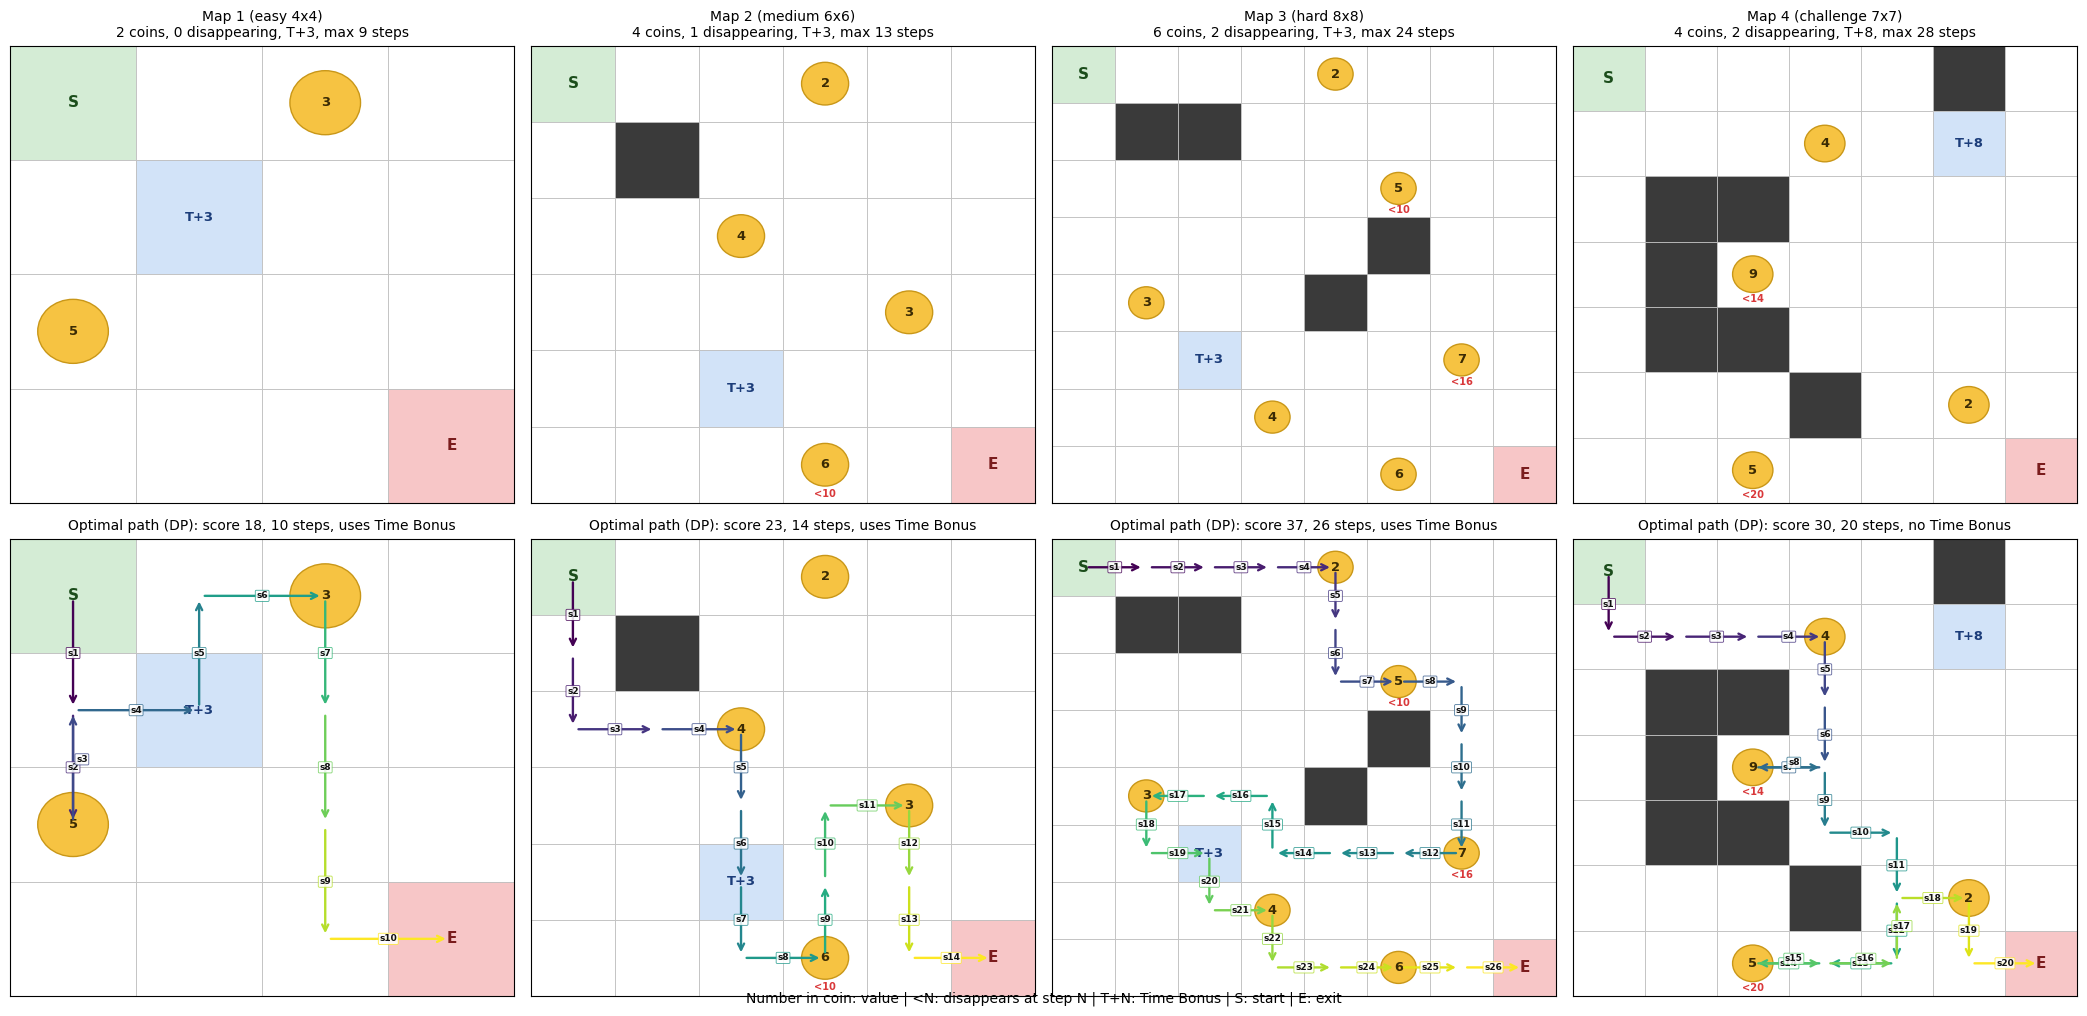

In [7]:
plot_maps_with_optimum()

In [8]:
state_space_table()

,Coin (biến mất),Tường,max_steps,|A|,|S| lý thuyết,|S| đạt tới,Đạt tới/lý thuyết (%),Điểm tối ưu (DP),Số bước tối ưu,Dùng Time Bonus
Bản đồ,,,,,,,,,,
Map 1 (easy 4x4),2 (0),0,9,4,1664,523,31.43,18.0,10,có
Map 2 (medium 6x6),4 (1),1,13,4,19584,2252,11.50,23.0,14,có
Map 3 (hard 8x8),6 (2),4,24,4,229376,16109,7.02,37.0,26,có
Map 4 (challenge 7x7),4 (2),7,28,4,58016,7117,12.27,30.0,20,không


# **Phần 4. Thuật toán**


## **4.1 Q-Learning (off-policy TD(0), cập nhật trực tuyến)**

$$Q(s,a)\leftarrow Q(s,a)+\alpha\bigl[r+\gamma\max_{a'}Q(s',a')\cdot\mathbf 1[\text{chưa kết thúc}]-Q(s,a)\bigr]$$

Mục tiêu cập nhật dùng $\max_{a'}$ độc lập với chính sách khám phá (off-policy), cập nhật ngay sau mỗi bước nên giá trị lan truyền nhanh. Nhược điểm: nhạy với $\alpha$, $\epsilon$ và **cách khởi tạo Q**.

## **4.2 First-Visit Monte Carlo (on-policy, cập nhật sau episode)**

$$Q(s,a)\leftarrow Q(s,a)+\tfrac{1}{N(s,a)}\bigl[G_t-Q(s,a)\bigr],\qquad G_t=\sum_{k=0}^{T-t-1}\gamma^k R_{t+k+1}$$

Chỉ cập nhật tại lần xuất hiện đầu tiên của $(s,a)$ trong episode; vì thời gian nằm trong trạng thái nên một trạng thái không lặp lại trong cùng episode (first-visit trùng every-visit). Ước lượng không chệch, không bootstrap, nhưng $G_t$ cộng dồn nhiễu của cả phần còn lại của episode (phương sai lớn) và chỉ học được khi episode kết thúc.

## **4.3 Khởi tạo lạc quan (QL-opt, MC-opt)**

Mỗi trạng thái mới được khởi tạo bằng một **cận trên hợp lệ** của phần thưởng còn lại có thể nhận từ trạng thái đó (tổng giá trị coin còn tới kịp, cộng thưởng Exit). Hành động chưa thử luôn hấp dẫn cho tới khi bị dữ liệu bác bỏ: khám phá có hệ thống thay cho khám phá ngẫu nhiên. Với MC, giá trị khởi tạo được tính như $n_0$ quan sát ban đầu (mặc định $n_0=1$) trong trung bình tăng dần.
## **4.4 Sarsa (on-policy TD(0)) — thuật toán bổ sung**

$$Q(s,a)\leftarrow Q(s,a)+\alpha\bigl[r+\gamma Q(s',a')-Q(s,a)\bigr],\quad a'\sim\epsilon\text{-greedy}(Q(s',\cdot))$$

Khác Q-Learning ở chỗ mục tiêu dùng hành động $a'$ **thực sự sẽ chọn** thay vì $\max$. Nó học giá trị của chính sách $\epsilon$-greedy đang chạy, nên thận trọng hơn khi epsilon còn lớn. Dùng cùng $\alpha$, lịch epsilon (tinh chỉnh riêng ở Phần 5) và cùng số episode với Q-Learning.

## **4.5 Thuật toán quy hoạch động dựa trên mô hình: VI, PI, TPI — thuật toán bổ sung**

Ba thuật toán này **biết** hàm chuyển và phần thưởng nên là *lập kế hoạch*, không phải học theo mẫu. Hàm `build_model` liệt kê toàn bộ trạng thái đạt tới (BFS) và dựng bảng $NS[s,a]$, $R[s,a]$; mọi thuật toán là phép tính vector hóa trên bảng này.

- **Value Iteration (VI):** $V_{k+1}(s)=\max_a\,[R(s,a)+\gamma V_k(s')]$. Một lần quét tốn $S\times 4$ backup.
- **Policy Iteration (PI):** lặp (đánh giá chính sách bằng quét tới hội tụ) rồi (cải thiện tham lam) tới khi chính sách ổn định.
- **Truncated Policy Iteration (TPI, modified PI):** mỗi vòng cải thiện tham lam rồi chỉ đánh giá **m** lần quét. $m=1$ là VI, $m\to\infty$ là PI; $m$ trung gian đánh đổi chi phí đánh giá lấy số vòng cải thiện.


In [9]:
# Hàm dùng chung cho các tác tử học
def greedy_rollout(env, Q, rng=None):
    """Chạy một episode theo chính sách greedy trên Q (dict: state -> [Q(a) x 4])."""
    state, _ = env.reset()
    unseen = bumps = 0
    path, actions = [(state[0], state[1])], []
    while True:
        q = Q.get(state)
        if q is None:
            unseen += 1
            a = rng.randrange(4) if rng else 0
        elif rng:
            m = max(q)
            a = rng.choice([k for k in range(4) if q[k] == m])
        else:
            a = max(range(4), key=lambda k: q[k])
        prev = (state[0], state[1])
        state, _, ter, trun, _ = env.step(a)
        bumps += (state[0], state[1]) == prev
        actions.append(a)
        path.append((state[0], state[1]))
        if ter or trun:
            break
    score = env.value_caught + (10.0 if env.reached_exit else 0.0)
    return {"score": float(score), "coins": env.coins_caught, "value": env.value_caught, "steps": len(actions),
            "exit": env.reached_exit, "bonus": int(state[4]), "dis_caught": env.disappeared_caught,
            "unseen": unseen, "bumps": bumps, "path": path, "actions": actions}


def epsilon_greedy(q, eps, rng):
    if rng.random() < eps:
        return rng.randrange(4)
    m = max(q)
    if q.count(m) > 1:
        return rng.choice([k for k in range(4) if q[k] == m])
    return q.index(m)


def new_stats(n):
    return {"lengths": np.zeros(n, np.float32), "returns": np.zeros(n, np.float32),
            "missions": np.zeros(n, np.float32), "coin_rates": np.zeros(n, np.float32),
            "dis_rates": np.zeros(n, np.float32), "eval_episodes": [], "greedy_scores": []}


def record_episode(st, ep, env, total, terminated, n_dis):
    st["returns"][ep] = total
    st["lengths"][ep] = env.steps
    cr = env.coins_caught / env.n_coins if env.n_coins > 0 else 1.0
    st["coin_rates"][ep] = cr
    st["dis_rates"][ep] = env.disappeared_caught / n_dis if n_dis > 0 else cr
    st["missions"][ep] = env.value_caught + (10.0 if terminated else 0.0)


# Q-Learning (off-policy TD(0))
def train_q_learning(config, reward_type, n_episodes, seed=42, alpha=0.5, gamma=GAMMA, eps_start=EPS_START,
                     eps_end=EPS_END, eps_decay=0.9995, optimistic_val=0.0, eval_interval=500, init_fn=None,
                     step_cost=None, n0=None, starts=None, es_prob=0.0):
    env = CoinCollectorEnv(config, reward_type, step_cost)
    eval_env = CoinCollectorEnv(config, 1)
    rng = random.Random(seed)
    Q, N = {}, {}
    st = new_stats(n_episodes)
    eps, n_dis = eps_start, len(env.dis_info)
    for ep in range(n_episodes):
        state, _ = env.reset(seed=seed if ep == 0 else None)
        if starts is not None and rng.random() < es_prob:     # can thiệp 'exploring starts' (Phần 7)
            state = env.state = starts[rng.randrange(len(starts))]
        total = 0.0
        while True:
            q = Q.get(state)
            if q is None:
                q = Q[state] = [init_fn(state) if init_fn else optimistic_val] * 4
                N[state] = [0, 0, 0, 0]
            action = epsilon_greedy(q, eps, rng)
            ns, r, ter, trun, _ = env.step(action)
            if ter or trun:
                target = r
            else:
                qn = Q.get(ns)
                target = r + gamma * (max(qn) if qn is not None else (init_fn(ns) if init_fn else optimistic_val))
            q[action] += alpha * (target - q[action])
            N[state][action] += 1
            total += r
            state = ns
            if ter or trun:
                break
        eps = max(eps_end, eps * eps_decay)
        record_episode(st, ep, env, total, ter, n_dis)
        if (ep + 1) % eval_interval == 0 or ep + 1 == n_episodes:
            st["eval_episodes"].append(ep + 1)
            st["greedy_scores"].append(greedy_rollout(eval_env, Q)["score"])
    st["N"] = N
    return Q, st


# Sarsa (on-policy TD(0))
def train_sarsa(config, reward_type, n_episodes, seed=42, alpha=0.5, gamma=GAMMA, eps_start=EPS_START,
                eps_end=EPS_END, eps_decay=0.9995, optimistic_val=0.0, eval_interval=500, init_fn=None,
                step_cost=None, n0=None, starts=None, es_prob=0.0):
    env = CoinCollectorEnv(config, reward_type, step_cost)
    eval_env = CoinCollectorEnv(config, 1)
    rng = random.Random(seed)
    Q, N = {}, {}
    st = new_stats(n_episodes)
    eps, n_dis = eps_start, len(env.dis_info)

    def get_q(s):
        q = Q.get(s)
        if q is None:
            q = Q[s] = [init_fn(s) if init_fn else optimistic_val] * 4
            N[s] = [0, 0, 0, 0]
        return q

    for ep in range(n_episodes):
        state, _ = env.reset(seed=seed if ep == 0 else None)
        if starts is not None and rng.random() < es_prob:     # can thiệp 'exploring starts' (Phần 7)
            state = env.state = starts[rng.randrange(len(starts))]
        q = get_q(state)
        action = epsilon_greedy(q, eps, rng)
        total = 0.0
        while True:
            ns, r, ter, trun, _ = env.step(action)
            if ter or trun:
                target, na = r, 0
            else:
                qn = get_q(ns)
                na = epsilon_greedy(qn, eps, rng)       # hành động THỰC SỰ sẽ chọn (on-policy)
                target = r + gamma * qn[na]
            q[action] += alpha * (target - q[action])
            N[state][action] += 1
            total += r
            if ter or trun:
                break
            state, q, action = ns, qn, na
        eps = max(eps_end, eps * eps_decay)
        record_episode(st, ep, env, total, ter, n_dis)
        if (ep + 1) % eval_interval == 0 or ep + 1 == n_episodes:
            st["eval_episodes"].append(ep + 1)
            st["greedy_scores"].append(greedy_rollout(eval_env, Q)["score"])
    st["N"] = N
    return Q, st


# First-Visit Monte Carlo (on-policy, trung bình tăng dần)
def train_monte_carlo(config, reward_type, n_episodes, seed=42, alpha=None, gamma=GAMMA, eps_start=EPS_START,
                      eps_end=EPS_END, eps_decay=0.9995, optimistic_val=0.0, eval_interval=500, init_fn=None,
                      step_cost=None, n0=None, starts=None, es_prob=0.0):
    env = CoinCollectorEnv(config, reward_type, step_cost)
    eval_env = CoinCollectorEnv(config, 1)
    rng = random.Random(seed)
    # n0: "số mẫu ảo" của giá trị khởi tạo. Mặc định 1 khi khởi tạo lạc quan, 0 khi khởi tạo 0.
    if n0 is None:
        n0 = 1 if (optimistic_val != 0.0 or init_fn is not None) else 0
    Q, N, Nvis = {}, {}, {}
    st = new_stats(n_episodes)
    eps, n_dis = eps_start, len(env.dis_info)
    for ep in range(n_episodes):
        state, _ = env.reset(seed=seed if ep == 0 else None)
        if starts is not None and rng.random() < es_prob:     # can thiệp 'exploring starts' (Phần 7)
            state = env.state = starts[rng.randrange(len(starts))]
        traj, total = [], 0.0
        while True:
            q = Q.get(state)
            if q is None:
                q = Q[state] = [init_fn(state) if init_fn else optimistic_val] * 4
                N[state] = [n0] * 4
                Nvis[state] = [0, 0, 0, 0]
            action = epsilon_greedy(q, eps, rng)
            ns, r, ter, trun, _ = env.step(action)
            traj.append((state, action, r))
            total += r
            state = ns
            if ter or trun:
                break
        first = {}
        for t, (s_t, a_t, _) in enumerate(traj):
            first.setdefault((s_t, a_t), t)
        G = 0.0
        for t in range(len(traj) - 1, -1, -1):
            s_t, a_t, r_t = traj[t]
            G = gamma * G + r_t
            if first[(s_t, a_t)] == t:
                N[s_t][a_t] += 1
                Nvis[s_t][a_t] += 1
                step = 1.0 / N[s_t][a_t]
                if alpha is not None and step < alpha:      # alpha != None: bước học hằng (quên mẫu cũ), mặc định trung bình mọi mẫu
                    step = alpha
                Q[s_t][a_t] += step * (G - Q[s_t][a_t])
        eps = max(eps_end, eps * eps_decay)
        record_episode(st, ep, env, total, ter, n_dis)
        if (ep + 1) % eval_interval == 0 or ep + 1 == n_episodes:
            st["eval_episodes"].append(ep + 1)
            st["greedy_scores"].append(greedy_rollout(eval_env, Q)["score"])
    st["N"] = Nvis
    return Q, st


TRAINERS = {"QL": train_q_learning, "MC": train_monte_carlo, "SARSA": train_sarsa}


In [10]:
# Thuật toán dựa trên mô hình: VI, PI, TPI
def build_model(cfg, rtype, step_cost=None):
    """Liệt kê toàn bộ trạng thái đạt tới (BFS) và dựng bảng chuyển trạng thái/phần thưởng:
    NS[s,a] = chỉ số trạng thái kế tiếp (S nếu kết thúc), R[s,a] = phần thưởng."""
    env = CoinCollectorEnv(cfg, rtype, step_cost)
    s0 = env.initial_state()
    idx, states = {s0: 0}, [s0]
    NS, R = [], []
    i = 0
    while i < len(states):
        s = states[i]
        nrow, rrow = [], []
        for a in range(4):
            ns, gain, _, ter, trun = env.transition(s, a)
            rrow.append(env.reward_fn(ns, gain, ter))
            if ter or trun:
                nrow.append(-1)
            else:
                j = idx.get(ns)
                if j is None:
                    j = idx[ns] = len(states)
                    states.append(ns)
                nrow.append(j)
        NS.append(nrow)
        R.append(rrow)
        i += 1
    S = len(states)
    NS = np.array(NS, dtype=np.int64)
    NSx = np.where(NS < 0, S, NS)                 # trạng thái kết thúc trỏ tới ô V[S] = 0
    return {"S": S, "idx": idx, "states": states, "NSx": NSx, "R": np.array(R, dtype=np.float64), "cfg": cfg, "rtype": rtype}


def _q_from_v(M, V, gamma):
    return M["R"] + gamma * V[M["NSx"]]


def value_iteration(M, gamma=GAMMA, tol=1e-9, max_iter=10000):
    """V_{k+1}(s) = max_a [R + gamma V_k(s')]. Mỗi vòng quét: S x 4 cập nhật."""
    S = M["S"]
    V = np.zeros(S + 1)
    hist, t0 = [], time.perf_counter()
    for it in range(1, max_iter + 1):
        Vn = np.append(_q_from_v(M, V, gamma).max(axis=1), 0.0)
        res = float(np.abs(Vn - V).max())
        hist.append(res)
        V = Vn
        if res < tol:
            break
    return {"Q": _q_from_v(M, V, gamma), "iters": it, "backups": it * S * 4, "time": time.perf_counter() - t0, "hist": hist}


def policy_iteration(M, gamma=GAMMA, eval_tol=1e-9, max_iter=500):
    """Lặp: (1) đánh giá chính sách pi bằng quét lặp tới hội tụ; (2) cải thiện tham lam. Dừng khi pi ổn định."""
    S, ar = M["S"], np.arange(M["S"])
    pi = np.zeros(S, dtype=np.int64)               # chính sách ban đầu: luôn đi "Lên"
    V = np.zeros(S + 1)
    eval_sweeps, hist, t0 = 0, [], time.perf_counter()
    for k in range(1, max_iter + 1):
        Rp, NSp = M["R"][ar, pi], M["NSx"][ar, pi]
        while True:                                 # đánh giá chính sách
            Vn = np.append(Rp + gamma * V[NSp], 0.0)
            res = float(np.abs(Vn - V).max())
            V = Vn
            eval_sweeps += 1
            if res < eval_tol:
                break
        Q = _q_from_v(M, V, gamma)
        newpi = Q.argmax(axis=1)
        keep = Q[ar, pi] >= Q.max(axis=1) - 1e-12   # giữ hành động cũ nếu vẫn tối ưu (tránh dao động do hòa)
        newpi = np.where(keep, pi, newpi)
        hist.append(int((newpi != pi).sum()))
        if (newpi == pi).all():
            break
        pi = newpi
    backups = eval_sweeps * S + k * S * 4
    return {"Q": Q, "iters": k, "eval_sweeps": eval_sweeps, "backups": backups, "time": time.perf_counter() - t0, "hist": hist}


def truncated_policy_iteration(M, m=3, gamma=GAMMA, tol=1e-9, max_iter=10000):
    """TPI (modified PI): mỗi vòng cải thiện tham lam rồi chỉ đánh giá m lần quét (m=1 là VI, m->inf là PI)."""
    S, ar = M["S"], np.arange(M["S"])
    V = np.zeros(S + 1)
    hist, t0 = [], time.perf_counter()
    for it in range(1, max_iter + 1):
        Q = _q_from_v(M, V, gamma)
        pi = Q.argmax(axis=1)
        Vold = V
        V = np.append(Q.max(axis=1), 0.0)           # lần quét đầu = cải thiện + đánh giá
        Rp, NSp = M["R"][ar, pi], M["NSx"][ar, pi]
        for _ in range(m - 1):                      # m-1 lần quét đánh giá thêm với pi cố định
            V = np.append(Rp + gamma * V[NSp], 0.0)
        res = float(np.abs(V - Vold).max())
        hist.append(res)
        if res < tol:
            break
    return {"Q": _q_from_v(M, V, gamma), "iters": it, "backups": it * (S * 4 + (m - 1) * S),
            "time": time.perf_counter() - t0, "hist": hist}


_MODEL_CACHE = {}
def get_model(map_id, rtype):
    key = (map_id, rtype)
    if key not in _MODEL_CACHE:
        M = build_model(MAPS[map_id], rtype)
        M["vi"] = value_iteration(M)
        M["Qstar"] = M["vi"]["Q"]
        _MODEL_CACHE[key] = M
    return _MODEL_CACHE[key]


def q_dict(M, Q):
    return {s: list(Q[i]) for i, s in enumerate(M["states"])}


def eval_policy_q(map_id, Q):
    """Điểm nhiệm vụ của chính sách greedy theo Q (dạng dict) trên bản đồ map_id."""
    return greedy_rollout(CoinCollectorEnv(MAPS[map_id], 1), Q)


## **4.6 Bộ chạy thí nghiệm song song**

Mỗi lượt huấn luyện (một seed của một cấu hình) là một đơn vị độc lập; `run_configs` chạy mọi lượt song song rồi gộp theo cấu hình bằng `aggregate` (điểm greedy, tỷ lệ so với DP, đường học, số seed đạt tối ưu, episode tới tối ưu `e2o`, độ phủ trạng thái...). Mọi phần sau dùng chung bộ chạy này.

In [11]:
def pmap(fn, items, n_jobs=N_JOBS, label=""):
    t0 = time.time()
    if n_jobs <= 1 or len(items) <= 1:
        out = [fn(x) for x in items]
    else:
        try:
            ctx = mp.get_context("fork")
        except ValueError:                           # hệ điều hành không hỗ trợ fork: chạy tuần tự
            out = [fn(x) for x in items]
        else:
            with ctx.Pool(n_jobs) as pool:
                out = pool.map(fn, items, chunksize=1)
    if label:
        print(f"[{label}] {len(items)} lượt huấn luyện xong sau {time.time() - t0:.0f}s")
    return out


def eps_decay_for(n_ep, eps_end, frac):
    return eps_end ** (1.0 / (frac * n_ep))


def run_task(spec):
    """Một lượt huấn luyện (1 seed) + đánh giá greedy cuối. Đây là đơn vị chạy song song."""
    algo, rt, seed, n_ep = spec["algo"], spec["rt"], spec["seed"], spec["n_ep"]
    cfg, opt = spec["cfg"], spec.get("opt", False)
    hp = {**HP[algo], **spec.get("hp", {})}
    init_fn = None
    if opt:
        ub_env = CoinCollectorEnv(cfg, rt)
        init_fn = lambda s: ub_env.upper_bound(s, rt)
    kw = dict(eps_end=hp["eps_end"], eps_decay=eps_decay_for(n_ep, hp["eps_end"], hp["frac"]),
              eval_interval=spec.get("eval_interval", max(100, n_ep // 40)), init_fn=init_fn,
              optimistic_val=spec.get("q0", 0.0), step_cost=spec.get("step_cost"), n0=spec.get("n0"))
    if "alpha" in hp:
        kw["alpha"] = hp["alpha"]
    if spec.get("es", 0) > 0:                         # exploring starts: bắt đầu từ trạng thái đạt tới ngẫu nhiên
        kw["starts"], kw["es_prob"] = build_model(cfg, rt)["states"], spec["es"]
    t0 = time.time()
    Q, st = TRAINERS[algo](cfg, rt, n_ep, seed=seed, **kw)
    ev = CoinCollectorEnv(cfg, 1)
    fin = greedy_rollout(ev, Q)
    tr = random.Random(1000 + seed)
    ties = float(np.mean([greedy_rollout(ev, Q, tr)["score"] for _ in range(TIE_ROLLOUTS)]))
    return {"spec": spec, "Q": Q, "N": st.pop("N"), "st": st, "fin": fin, "tie": ties, "time": time.time() - t0}


def make_specs(algo, cfg, rt, n_ep, seeds, **extra):
    return [dict(algo=algo, cfg=cfg, rt=rt, seed=s, n_ep=n_ep, **extra) for s in seeds]


def aggregate(runs, dp):
    """Gộp các seed của một cấu hình thành một bản ghi thống kê."""
    cfg = runs[0]["spec"]["cfg"]
    n_dis = len(cfg.get("disappear_info", {}))
    fin = [r["fin"] for r in runs]
    scores = np.array([f["score"] for f in fin])
    curves = np.array([r["st"]["greedy_scores"] for r in runs])
    ex = runs[0]["st"]["eval_episodes"]
    n_ep = runs[0]["spec"]["n_ep"]
    tail = max(0, n_ep - 1000)
    best = max(range(len(runs)), key=lambda i: (scores[i], float(np.mean(runs[i]["st"]["missions"][-1000:]))))
    e2o = []
    for c in curves:                                  # episode đầu tiên mà từ đó greedy luôn đạt tối ưu
        ok = np.where(c >= dp - 1e-9)[0]
        good = [i for i in ok if (c[i:] >= dp - 1e-9).all()]
        e2o.append(ex[good[0]] if good else np.nan)
    return {
        "runs": runs, "dp": dp, "scores": scores.tolist(), "greedy": float(scores.mean()), "greedy_std": float(scores.std()),
        "ratio": float(scores.mean() / dp), "n_opt": int((scores >= dp - 1e-9).sum()), "n_seeds": len(runs),
        "eval_x": ex, "eval_mean": curves.mean(0), "eval_std": curves.std(0), "e2o": e2o,
        "mission_mean": np.mean([r["st"]["missions"] for r in runs], axis=0),
        "final_return": float(np.mean([r["st"]["returns"][tail:].mean() for r in runs])),
        "final_mission": float(np.mean([r["st"]["missions"][tail:].mean() for r in runs])),
        "final_cr": float(np.mean([r["st"]["coin_rates"][tail:].mean() for r in runs])),
        "final_dis": float(np.mean([r["st"]["dis_rates"][tail:].mean() for r in runs])),
        "greedy_dis": float(np.mean([(f["dis_caught"] / n_dis) if n_dis else f["coins"] / len(cfg["coins"]) for f in fin])),
        "bonus": float(np.mean([f["bonus"] for f in fin])), "steps": float(np.mean([f["steps"] for f in fin])),
        "bumps": float(np.mean([f["bumps"] for f in fin])), "unseen": float(np.mean([f["unseen"] for f in fin])),
        "tie": float(np.mean([r["tie"] for r in runs])), "n_states": float(np.mean([len(r["Q"]) for r in runs])),
        "time": float(sum(r["time"] for r in runs)), "best": best, "best_seed": runs[best]["spec"]["seed"],
        "best_Q": runs[best]["Q"], "n_ep": n_ep,
    }


def run_configs(configs, label=""):
    """configs: dict key -> (list[spec], dp). Chạy toàn bộ spec song song rồi gộp theo key."""
    flat = [(k, s) for k, (specs, _) in configs.items() for s in specs]
    flat.sort(key=lambda x: -x[1]["n_ep"] * len(x[1]["cfg"]["coins"]))      # việc nặng chạy trước để cân tải
    outs = pmap(run_task, [s for _, s in flat], label=label)
    grouped = {}
    for (k, _), o in zip(flat, outs):
        grouped.setdefault(k, []).append(o)
    return {k: aggregate(sorted(v, key=lambda o: o["spec"]["seed"]), configs[k][1]) for k, v in grouped.items()}


# **Phần 5. Tinh chỉnh siêu tham số**

Siêu tham số chọn riêng cho từng thuật toán rồi dùng chung cho mọi bản đồ, reward và biến thể khởi tạo:

- **Q-Learning, Sarsa:** $\alpha\in\{0.1,0.3,0.5,0.7\}$, `frac` $\in\{0.5,0.7,0.9\}$ (tỷ lệ số episode để epsilon giảm tới 0.05).
- **Monte Carlo:** `eps_end` $\in\{0.05,0.10\}$, `frac` $\in\{0.5,0.7,0.9\}$ (MC dùng trung bình tăng dần nên không có $\alpha$).
- **Dữ liệu chọn:** Map 2 và Map 3, Reward 3, `N_EP_ABL` episode, `TUNE_SEEDS` (không trùng `SEEDS`). Tiêu chí: trung bình tỷ lệ điểm greedy trên điểm DP của hai bản đồ.


[tinh chỉnh] 180 lượt huấn luyện xong sau 605s


,Thuật toán,"(alpha|eps_end, frac)",Tỷ lệ Map 2,Tỷ lệ Map 3,Trung bình
0,QL,"(0.1, 0.5)",0.957,0.847,0.902
1,QL,"(0.1, 0.7)",1.000,0.829,0.914
2,QL,"(0.1, 0.9)",0.913,0.811,0.862
3,QL,"(0.3, 0.5)",0.957,0.883,0.920
4,QL,"(0.3, 0.7)",0.913,0.847,0.880
5,QL,"(0.3, 0.9)",0.870,0.811,0.840
6,QL,"(0.5, 0.5)",0.826,0.811,0.818
7,QL,"(0.5, 0.7)",0.942,0.811,0.876
8,QL,"(0.5, 0.9)",0.957,0.793,0.875
9,QL,"(0.7, 0.5)",0.913,0.811,0.862


Siêu tham số được chọn: {'QL': {'alpha': 0.3, 'eps_end': 0.05, 'frac': 0.5}, 'MC': {'eps_end': 0.05, 'frac': 0.7}, 'SARSA': {'alpha': 0.1, 'eps_end': 0.05, 'frac': 0.5}}


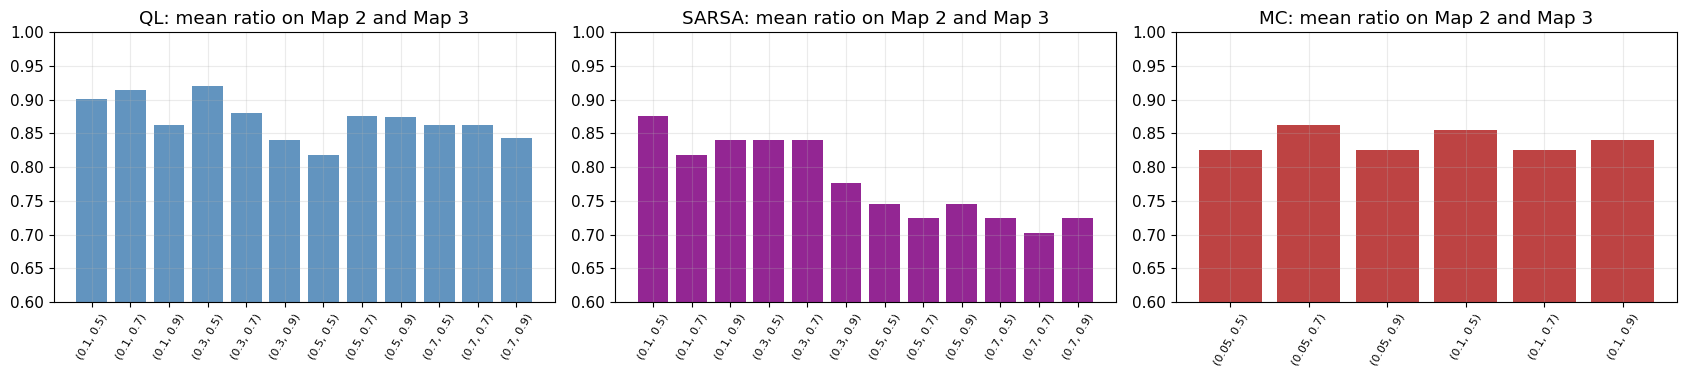

In [12]:
TUNE_GRID = {"QL": [(a, f) for a in (0.1, 0.3, 0.5, 0.7) for f in (0.5, 0.7, 0.9)],        # (alpha, frac)
             "SARSA": [(a, f) for a in (0.1, 0.3, 0.5, 0.7) for f in (0.5, 0.7, 0.9)],
             "MC": [(e, f) for e in (0.05, 0.10) for f in (0.5, 0.7, 0.9)]}                # (eps_end, frac)
cfgs = {}
for algo, grid in TUNE_GRID.items():
    for g in grid:
        hp = {"alpha": g[0], "frac": g[1]} if algo != "MC" else {"eps_end": g[0], "frac": g[1]}
        for m in (2, 3):
            cfgs[(algo, g, m)] = (make_specs(algo, MAPS[m], 3, N_EP_ABL[m], TUNE_SEEDS, hp=hp), DP_SCORES[m])
TUNE_RAW = run_configs(cfgs, "tinh chỉnh")
rows = []
for algo, grid in TUNE_GRID.items():
    for g in grid:
        r2, r3 = TUNE_RAW[(algo, g, 2)]["ratio"], TUNE_RAW[(algo, g, 3)]["ratio"]
        rows.append({"Thuật toán": algo, "(alpha|eps_end, frac)": str(g), "Tỷ lệ Map 2": r2, "Tỷ lệ Map 3": r3, "Trung bình": (r2 + r3) / 2, "_g": g})
TUNE_DF = pd.DataFrame(rows)
for algo in TUNE_GRID:
    sub = TUNE_DF[TUNE_DF["Thuật toán"] == algo]
    g = sub.loc[sub["Trung bình"].idxmax(), "_g"]
    HP[algo] = {"alpha": g[0], "eps_end": EPS_END, "frac": g[1]} if algo != "MC" else {"eps_end": g[0], "frac": g[1]}
display(TUNE_DF.drop(columns="_g").style.format({"Tỷ lệ Map 2": "{:.3f}", "Tỷ lệ Map 3": "{:.3f}", "Trung bình": "{:.3f}"})
        .background_gradient(subset=["Trung bình"], cmap="YlGn"))
print("Siêu tham số được chọn:", HP)

fig, axes = plt.subplots(1, 3, figsize=(17, 3.9))
for ax, algo in zip(axes, TUNE_GRID):
    sub = TUNE_DF[TUNE_DF["Thuật toán"] == algo]
    ax.bar(range(len(sub)), sub["Trung bình"], color=ALGO_COLORS[algo], alpha=.85)
    ax.set_xticks(range(len(sub)))
    ax.set_xticklabels(sub["(alpha|eps_end, frac)"], rotation=60, fontsize=8)
    ax.set_ylim(0.6, 1.0)
    ax.set_title(f"{algo}: mean ratio on Map 2 and Map 3")
plt.tight_layout()
plt.show()


# **Phần 6. Thí nghiệm chính**

Hai thuật toán chính và hai biến thể khởi tạo lạc quan (QL, MC, QL-opt, MC-opt) trên cả 4 bản đồ x 5 reward x 5 seed, tức 400 lượt huấn luyện chạy trong **một** lệnh. Mọi kết quả nằm trong `RES[(map, thuật toán, reward)]`; các mục sau chỉ là các lát cắt khác nhau của cùng cấu trúc đó.

In [13]:
cfgs = {}
for m in MAPS:
    for a in ALGOS4:
        for rt in REWARDS:
            cfgs[(m, a, rt)] = (make_specs(a.split("-")[0], MAPS[m], rt, N_EP[m], SEEDS, opt=a.endswith("opt")), DP_SCORES[m])
RES = run_configs(cfgs, "lưới chính")
print("Số cấu hình:", len(RES), "| tổng thời gian CPU (s):", round(sum(r["time"] for r in RES.values())))


[lưới chính] 400 lượt huấn luyện xong sau 1909s
Số cấu hình: 80 | tổng thời gian CPU (s): 1909


## **6.1 Bảng tổng hợp**

`greedy`: điểm nhiệm vụ của chính sách greedy cuối (trung bình 5 seed); `ratio`: greedy / DP; `seeds_opt`: số seed đạt đúng tối ưu; `e2o_median`: episode median tới khi greedy luôn tối ưu (chỉ tính seed có đạt); `coverage_%`: tỷ lệ trạng thái đạt tới mà Q-table đã thăm.

In [14]:
DF = results_df(RES)
display(DF.pivot_table(index=["map", "algo"], columns="reward", values="ratio", sort=False).style.format("{:.3f}").background_gradient(cmap="YlGn", vmin=0.4, vmax=1.0)
        .set_caption("Tỷ lệ điểm greedy / tối ưu DP"))
display(DF.pivot_table(index=["map", "algo"], columns="reward", values="seeds_opt", aggfunc="first", sort=False).style.set_caption("Số seed đạt đúng tối ưu (trên 5)"))
display(DF.groupby(["map", "algo"], sort=False)[["ratio", "coverage_%", "return_cuoi", "mission_train", "cứu_coin_%", "time_s"]].mean().round(2)
        .rename(columns={"ratio": "tỷ lệ TB", "coverage_%": "độ phủ TB (%)", "mission_train": "điểm HL", "cứu_coin_%": "cứu coin (%)", "time_s": "CPU (s)"}))
tie_diff = max(abs(r["tie"] - r["greedy"]) for r in RES.values())
print(f"Kiểm tra cách phá hòa khi đánh giá greedy: chênh lệch lớn nhất giữa 'greedy cố định' và 'greedy phá hòa ngẫu nhiên' = {tie_diff:.3f} điểm")

tỷ lệ TB  độ phủ TB (%)  return_cuoi  điểm HL  cứu coin (%)  CPU (s)
map algo                                                                        
1   QL          0.85          91.66        14.89    14.91          54.0     2.17
    MC          0.83          97.99        15.00    14.96          50.0     2.37
    QL-opt      1.00         100.00        17.73    17.66         100.0     2.91
    MC-opt      0.83          98.49        14.99    14.95          50.0     2.31
2   QL          0.82          50.62        17.20    17.08          48.0    14.00
    MC          0.89          74.15        19.75    19.43          96.0    15.85
    QL-opt      1.00          93.17        21.77    21.45         100.0    16.28
    MC-opt      0.85          75.17        19.23    18.88          88.0    14.84
3   QL          0.71          24.24        24.74    24.28          66.0    70.46
    MC          0.81          51.13        29.62    29.13          50.0    47.89
    QL-opt      1.00          76.08        33.75    33.41         100.0    50.75
    MC-opt      0.81          49.53        29.70    29.25          50.0    51.33
4   QL          0.83          38.82        24.71    24.00          50.0    24.16
    MC          0.94          55.00        27.91    27.48          82.0    21.64
    QL-opt      1.00          83.60        30.17    29.07         100.0    22.97
    MC-opt      0.93          56.84        27.75    27.38          80.0    21.92

Kiểm tra cách phá hòa khi đánh giá greedy: chênh lệch lớn nhất giữa 'greedy cố định' và 'greedy phá hòa ngẫu nhiên' = 0.000 điểm


## **6.2 Tỷ lệ so với tối ưu theo (thuật toán, reward) trên từng bản đồ**

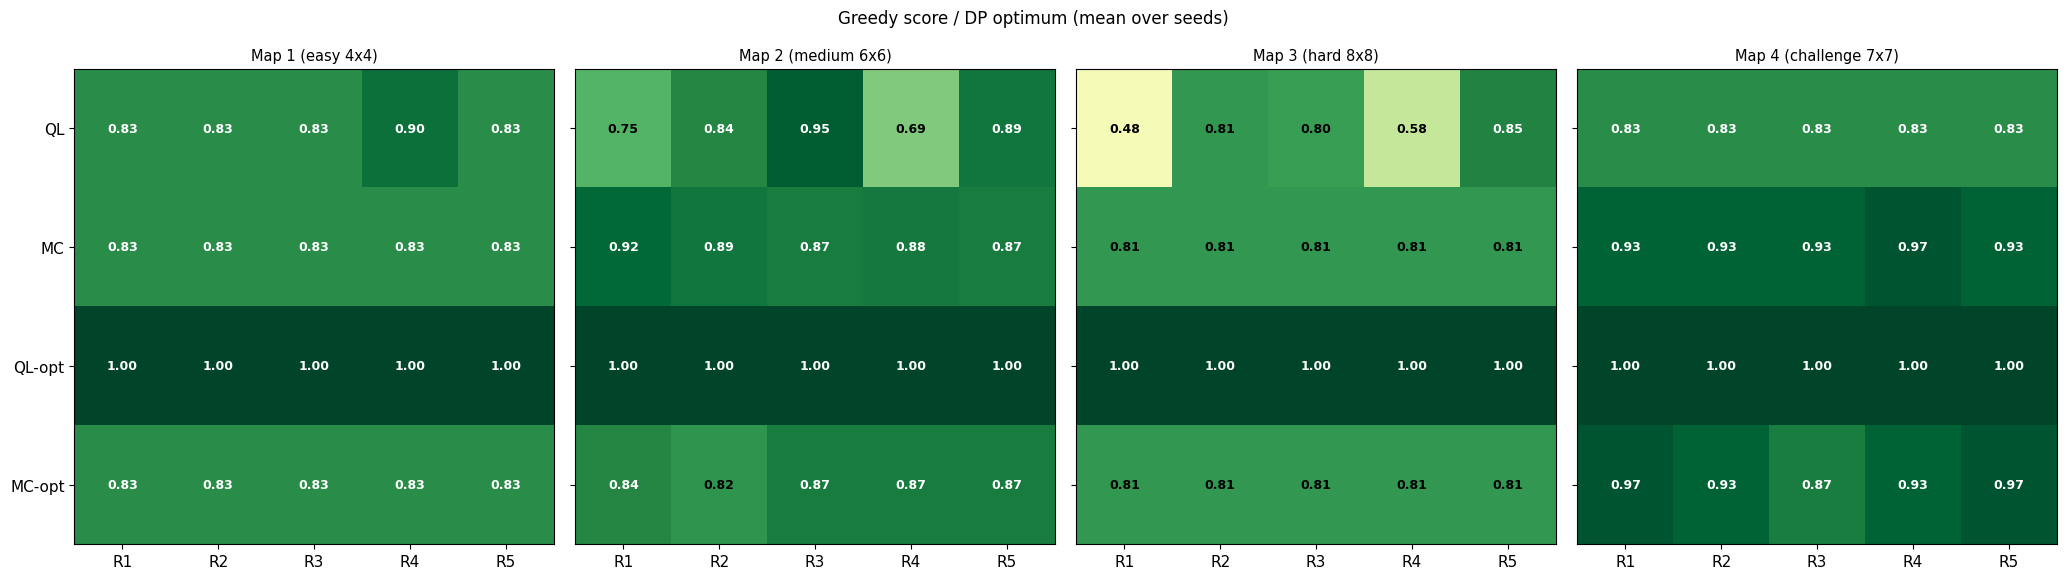

In [15]:
plot_ratio_heatmaps(RES)

## **6.3 Đường học trên cả 4 bản đồ x 5 reward**

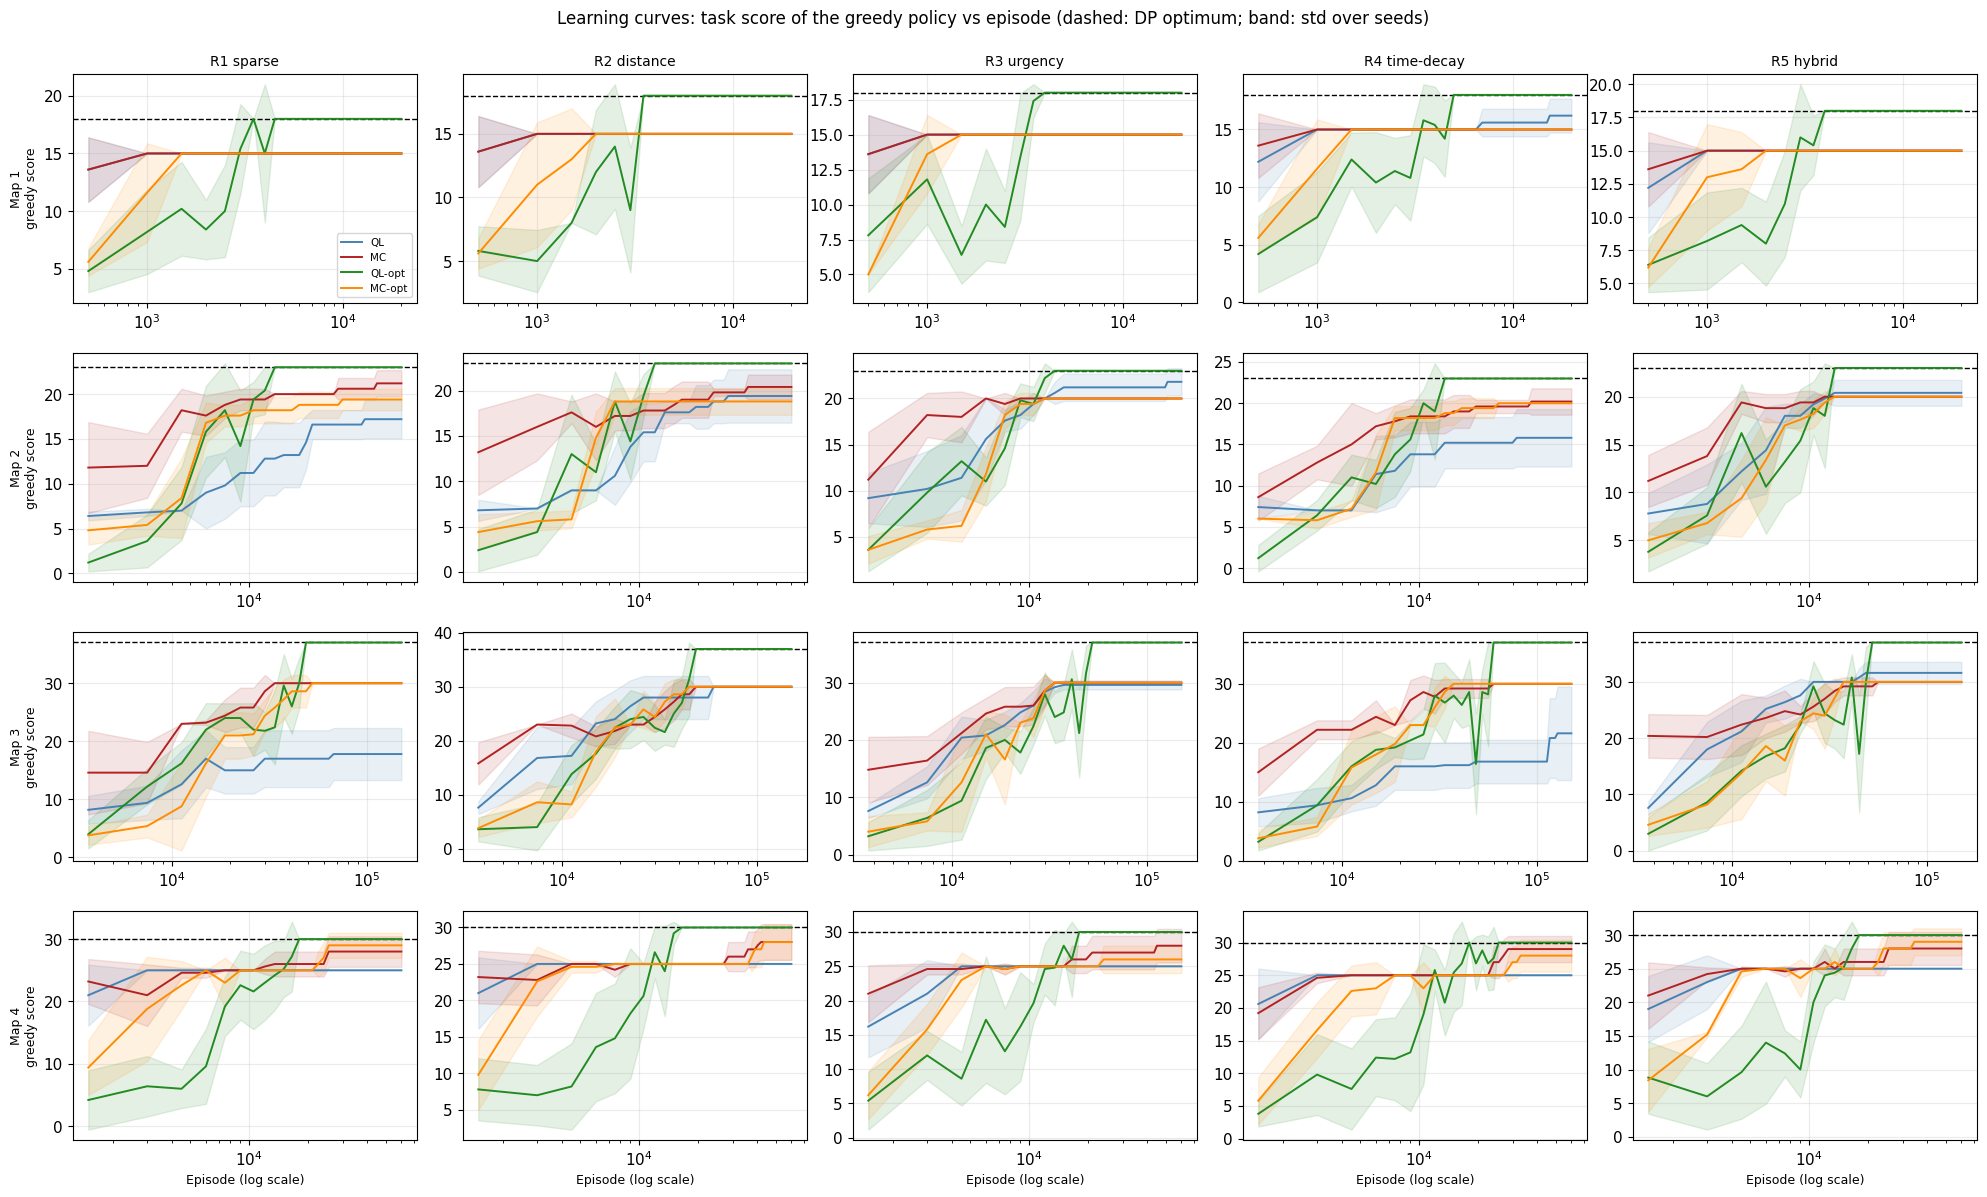

In [16]:
plot_greedy_curves(RES)

## **6.4 Chính sách cuối cùng: đường đi và mũi tên**

Hàng là thuật toán, cột là reward. Mỗi ô là Q-table của seed tốt nhất. Dưới đây vẽ đường đi greedy cho cả 4 bản đồ và chính sách mũi tên cho Map 2 và Map 3.

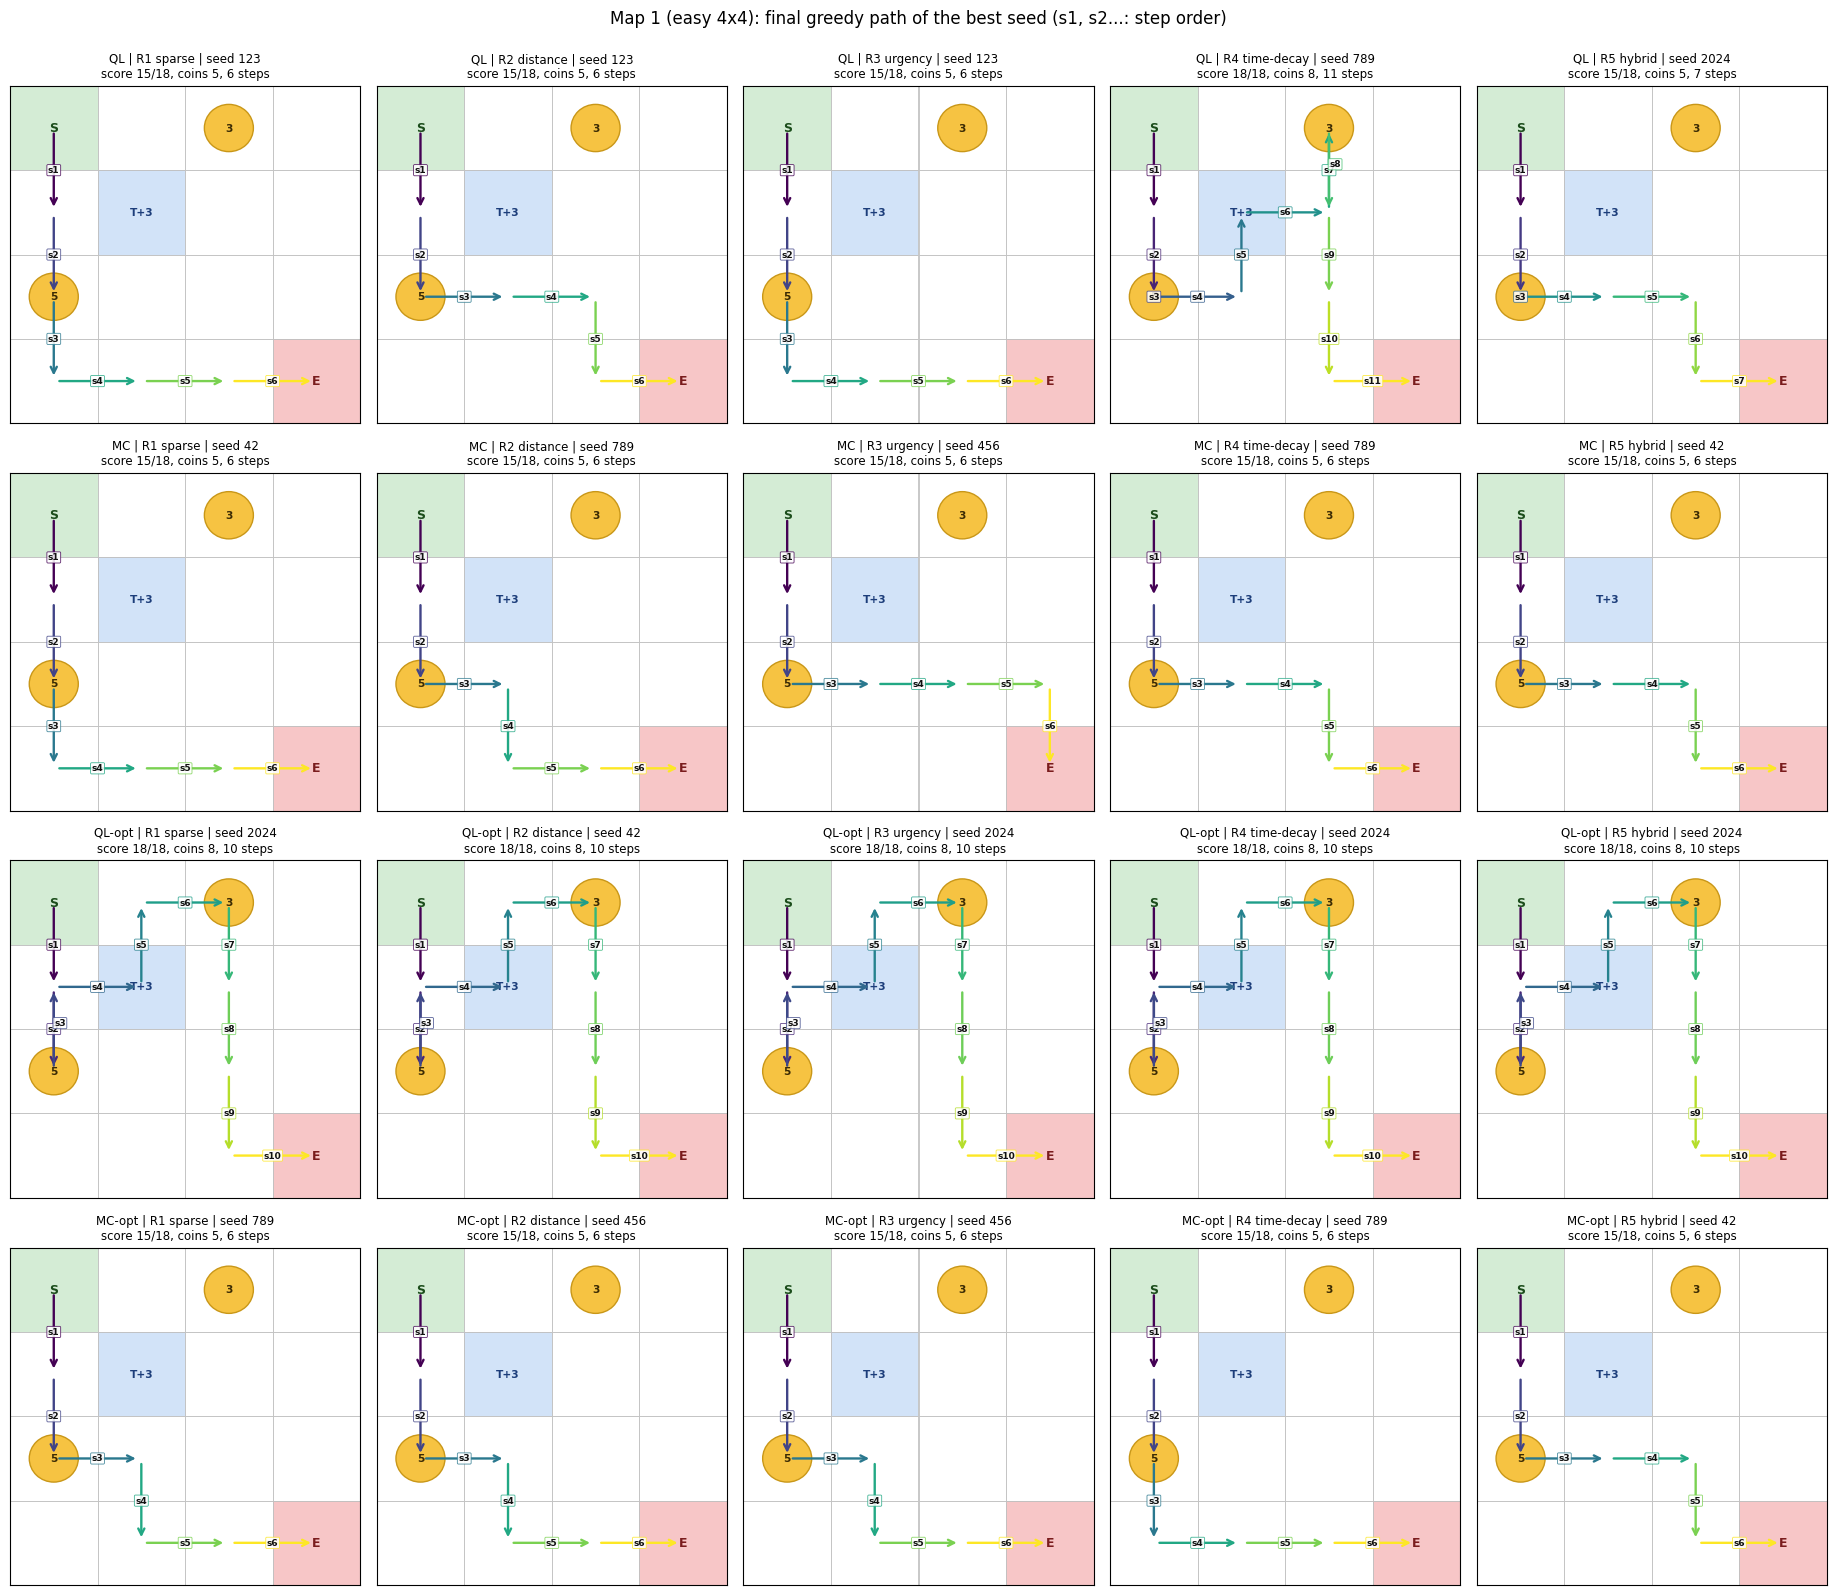

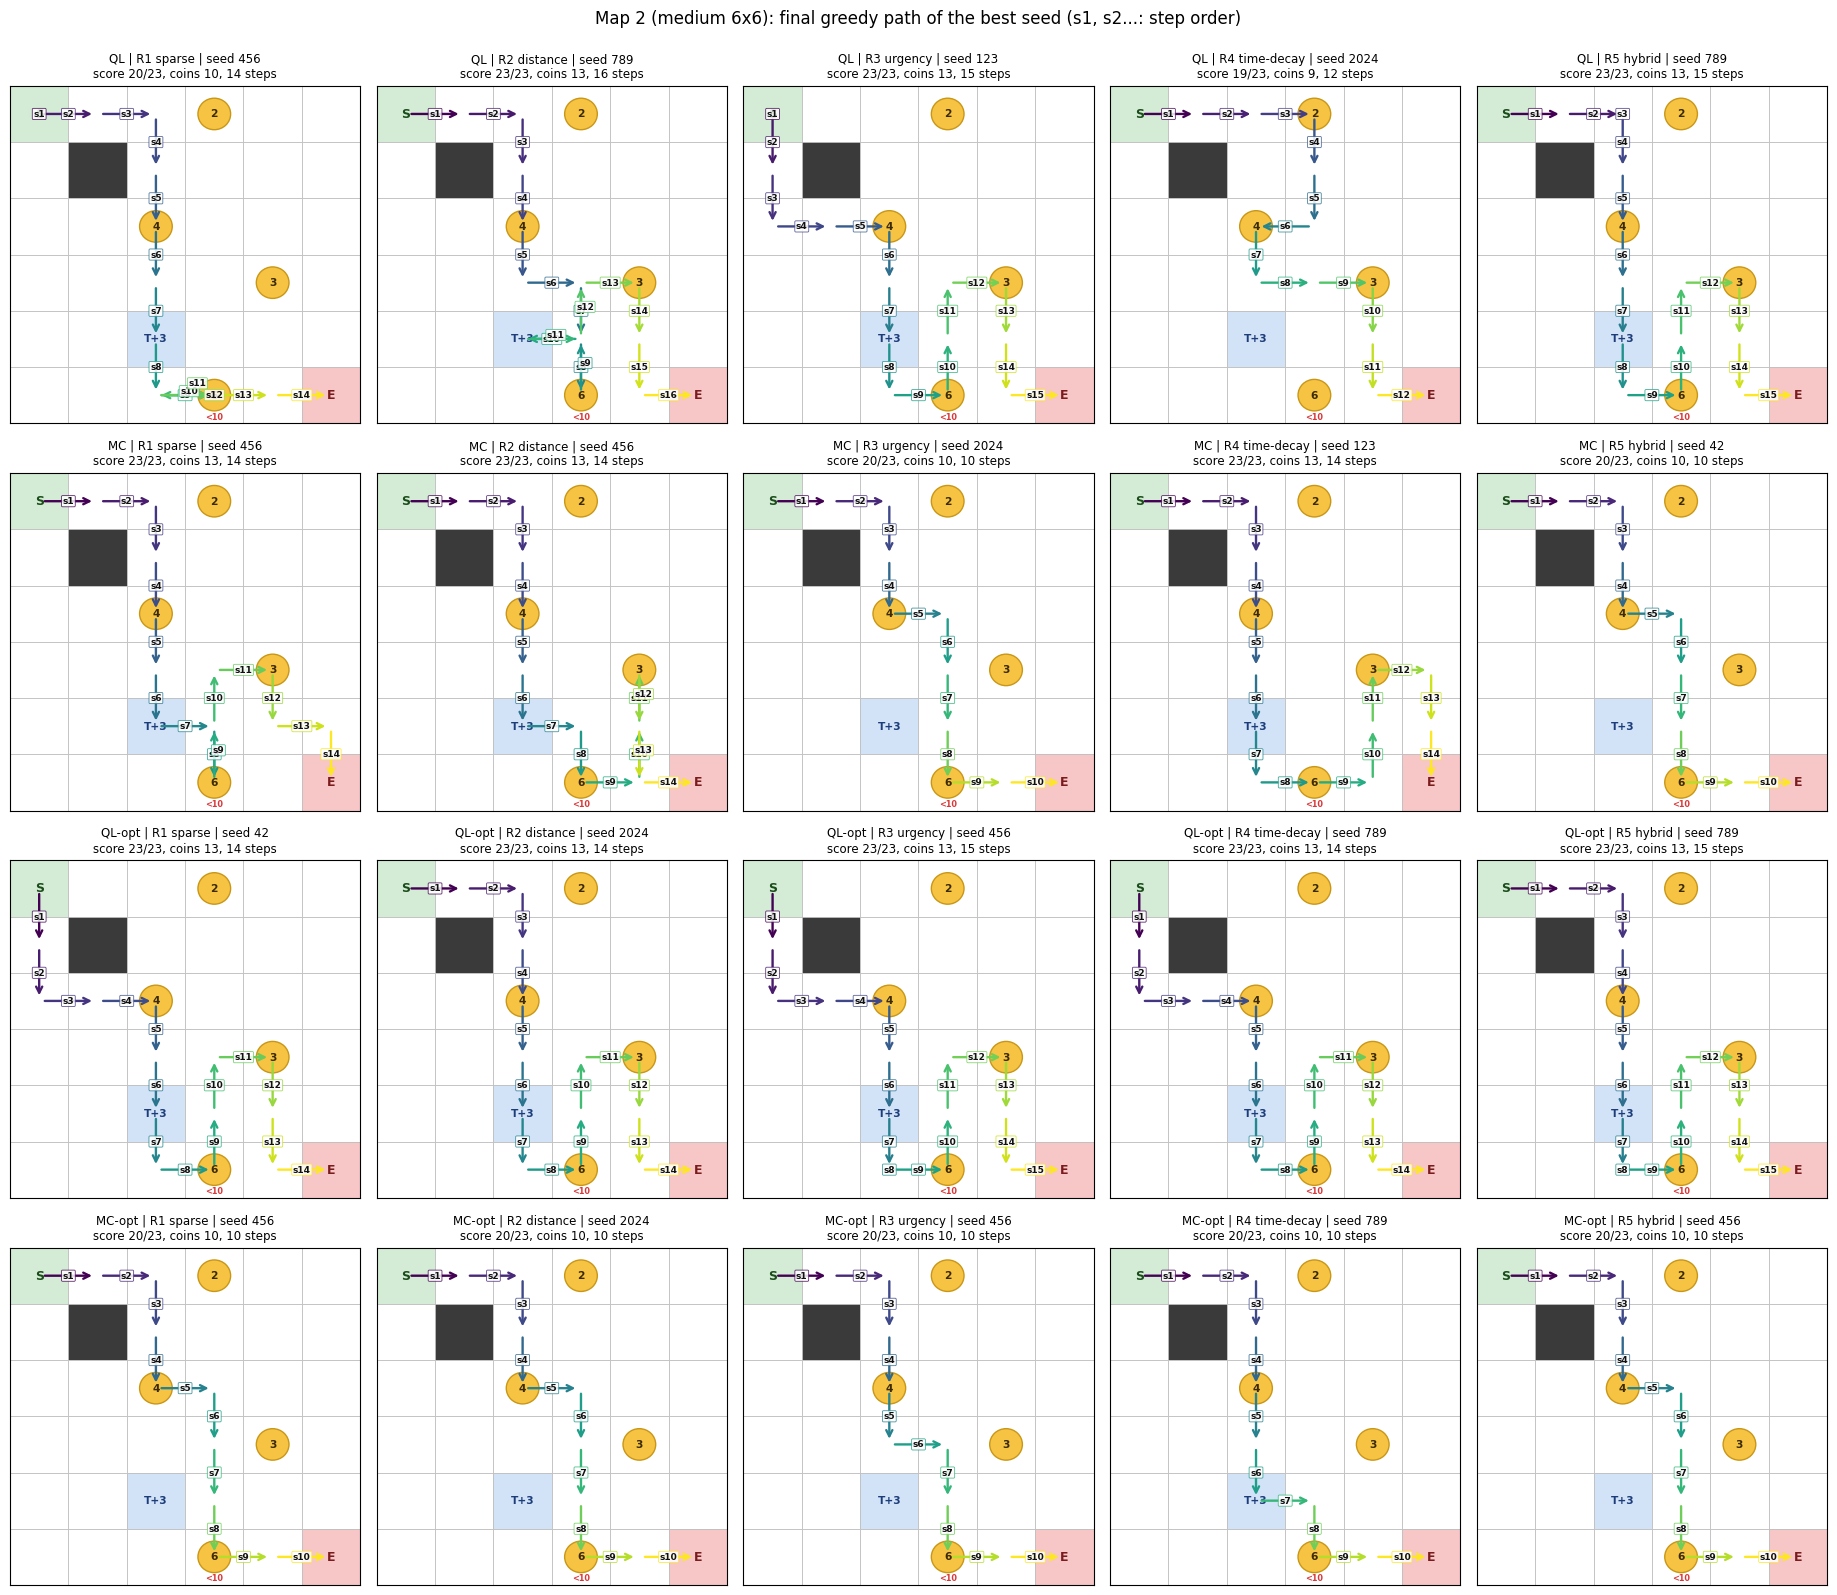

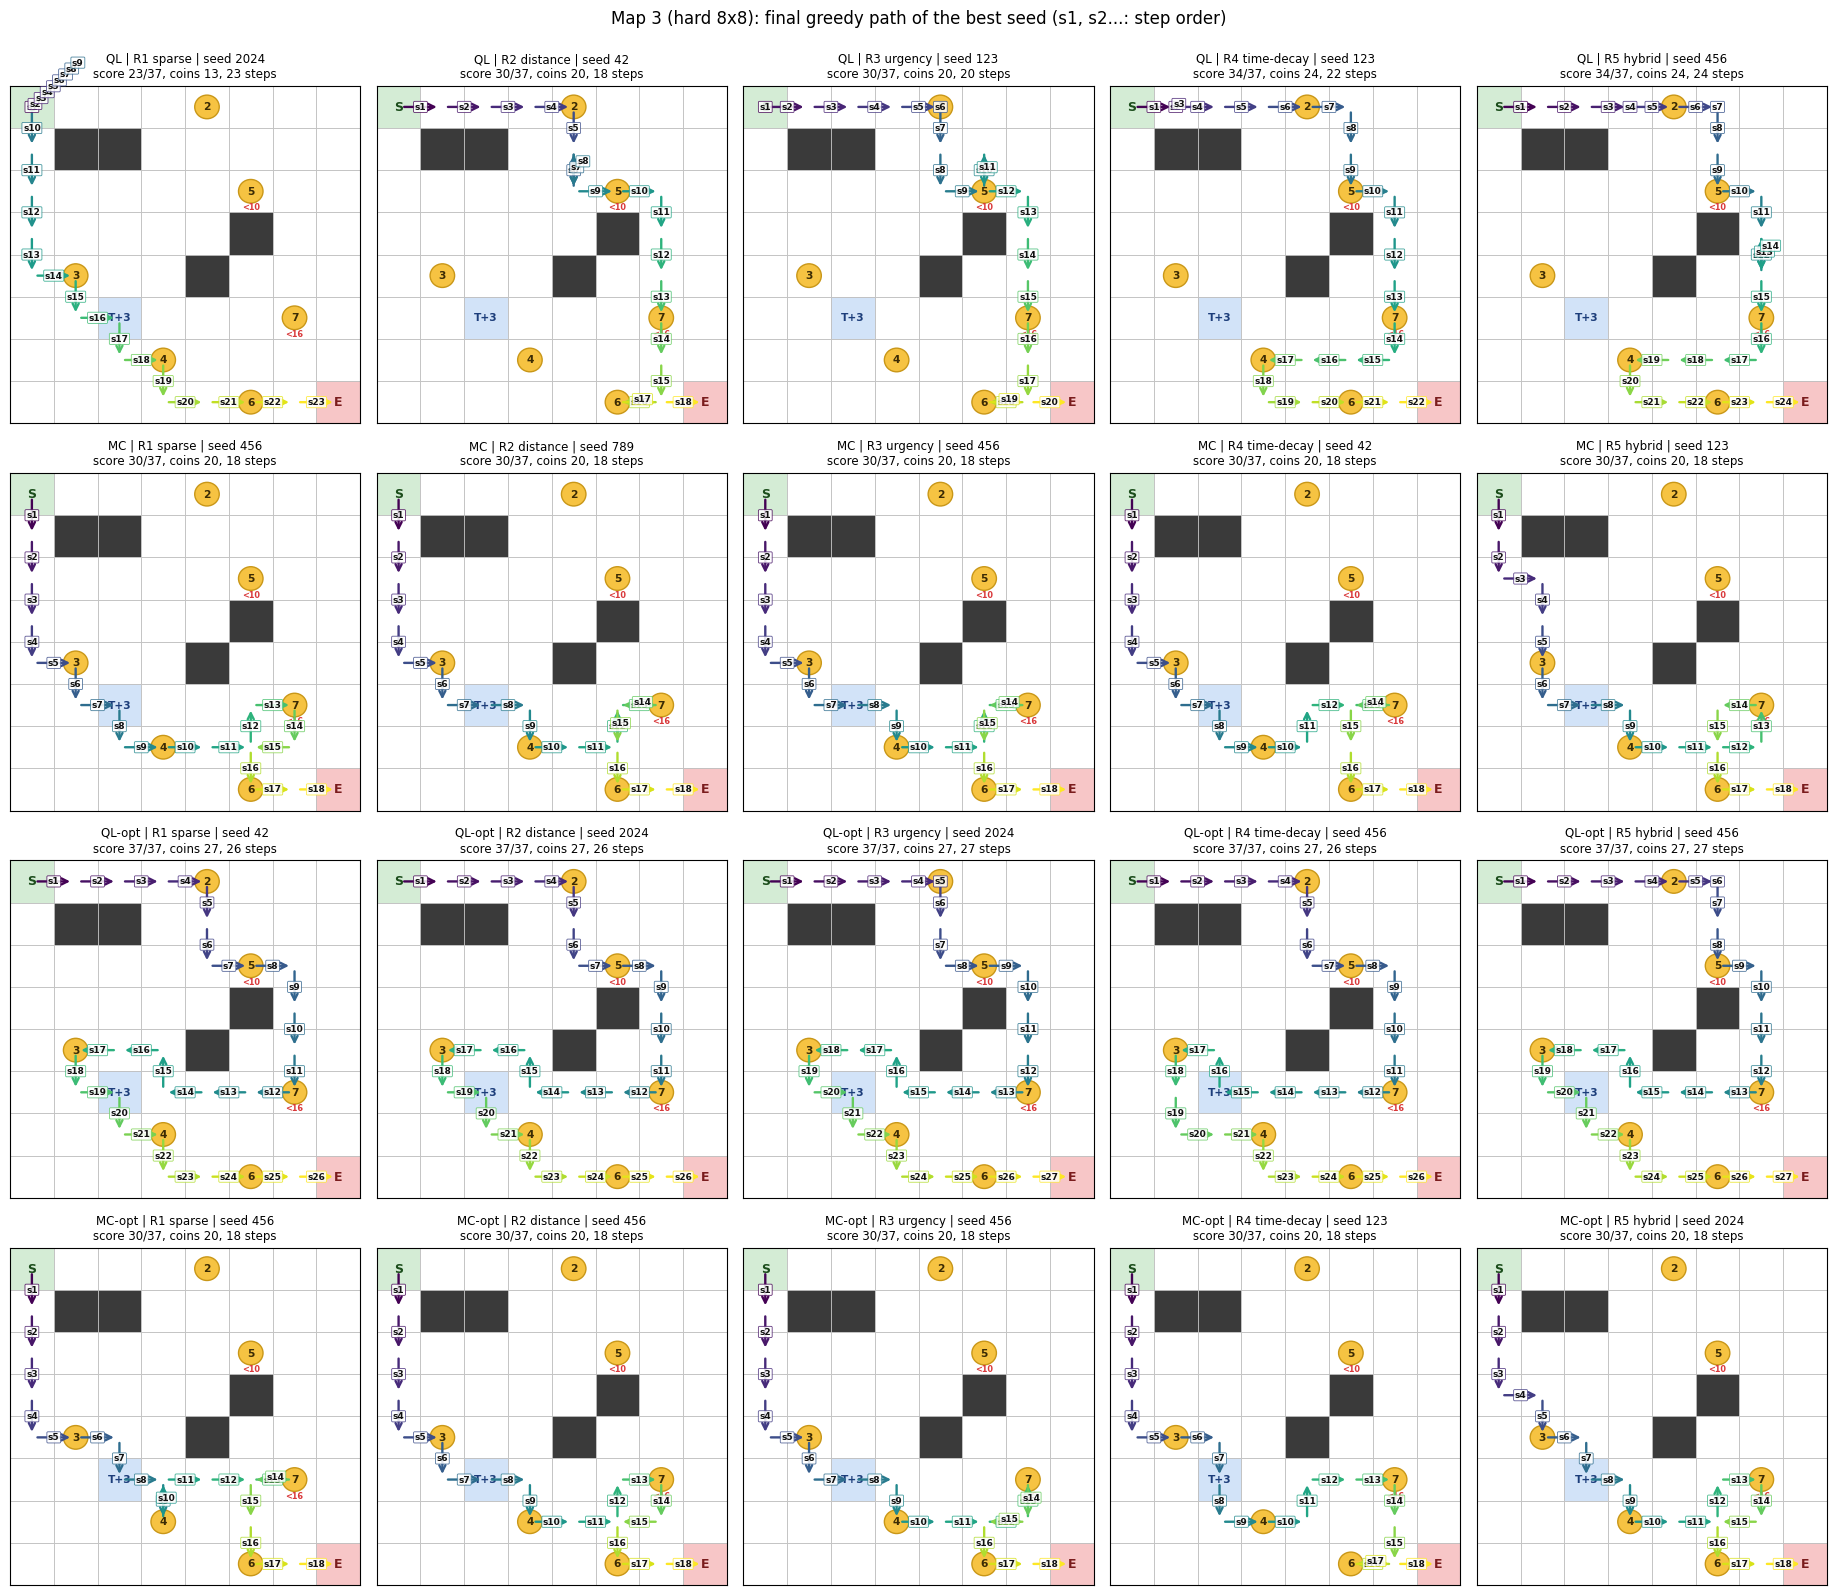

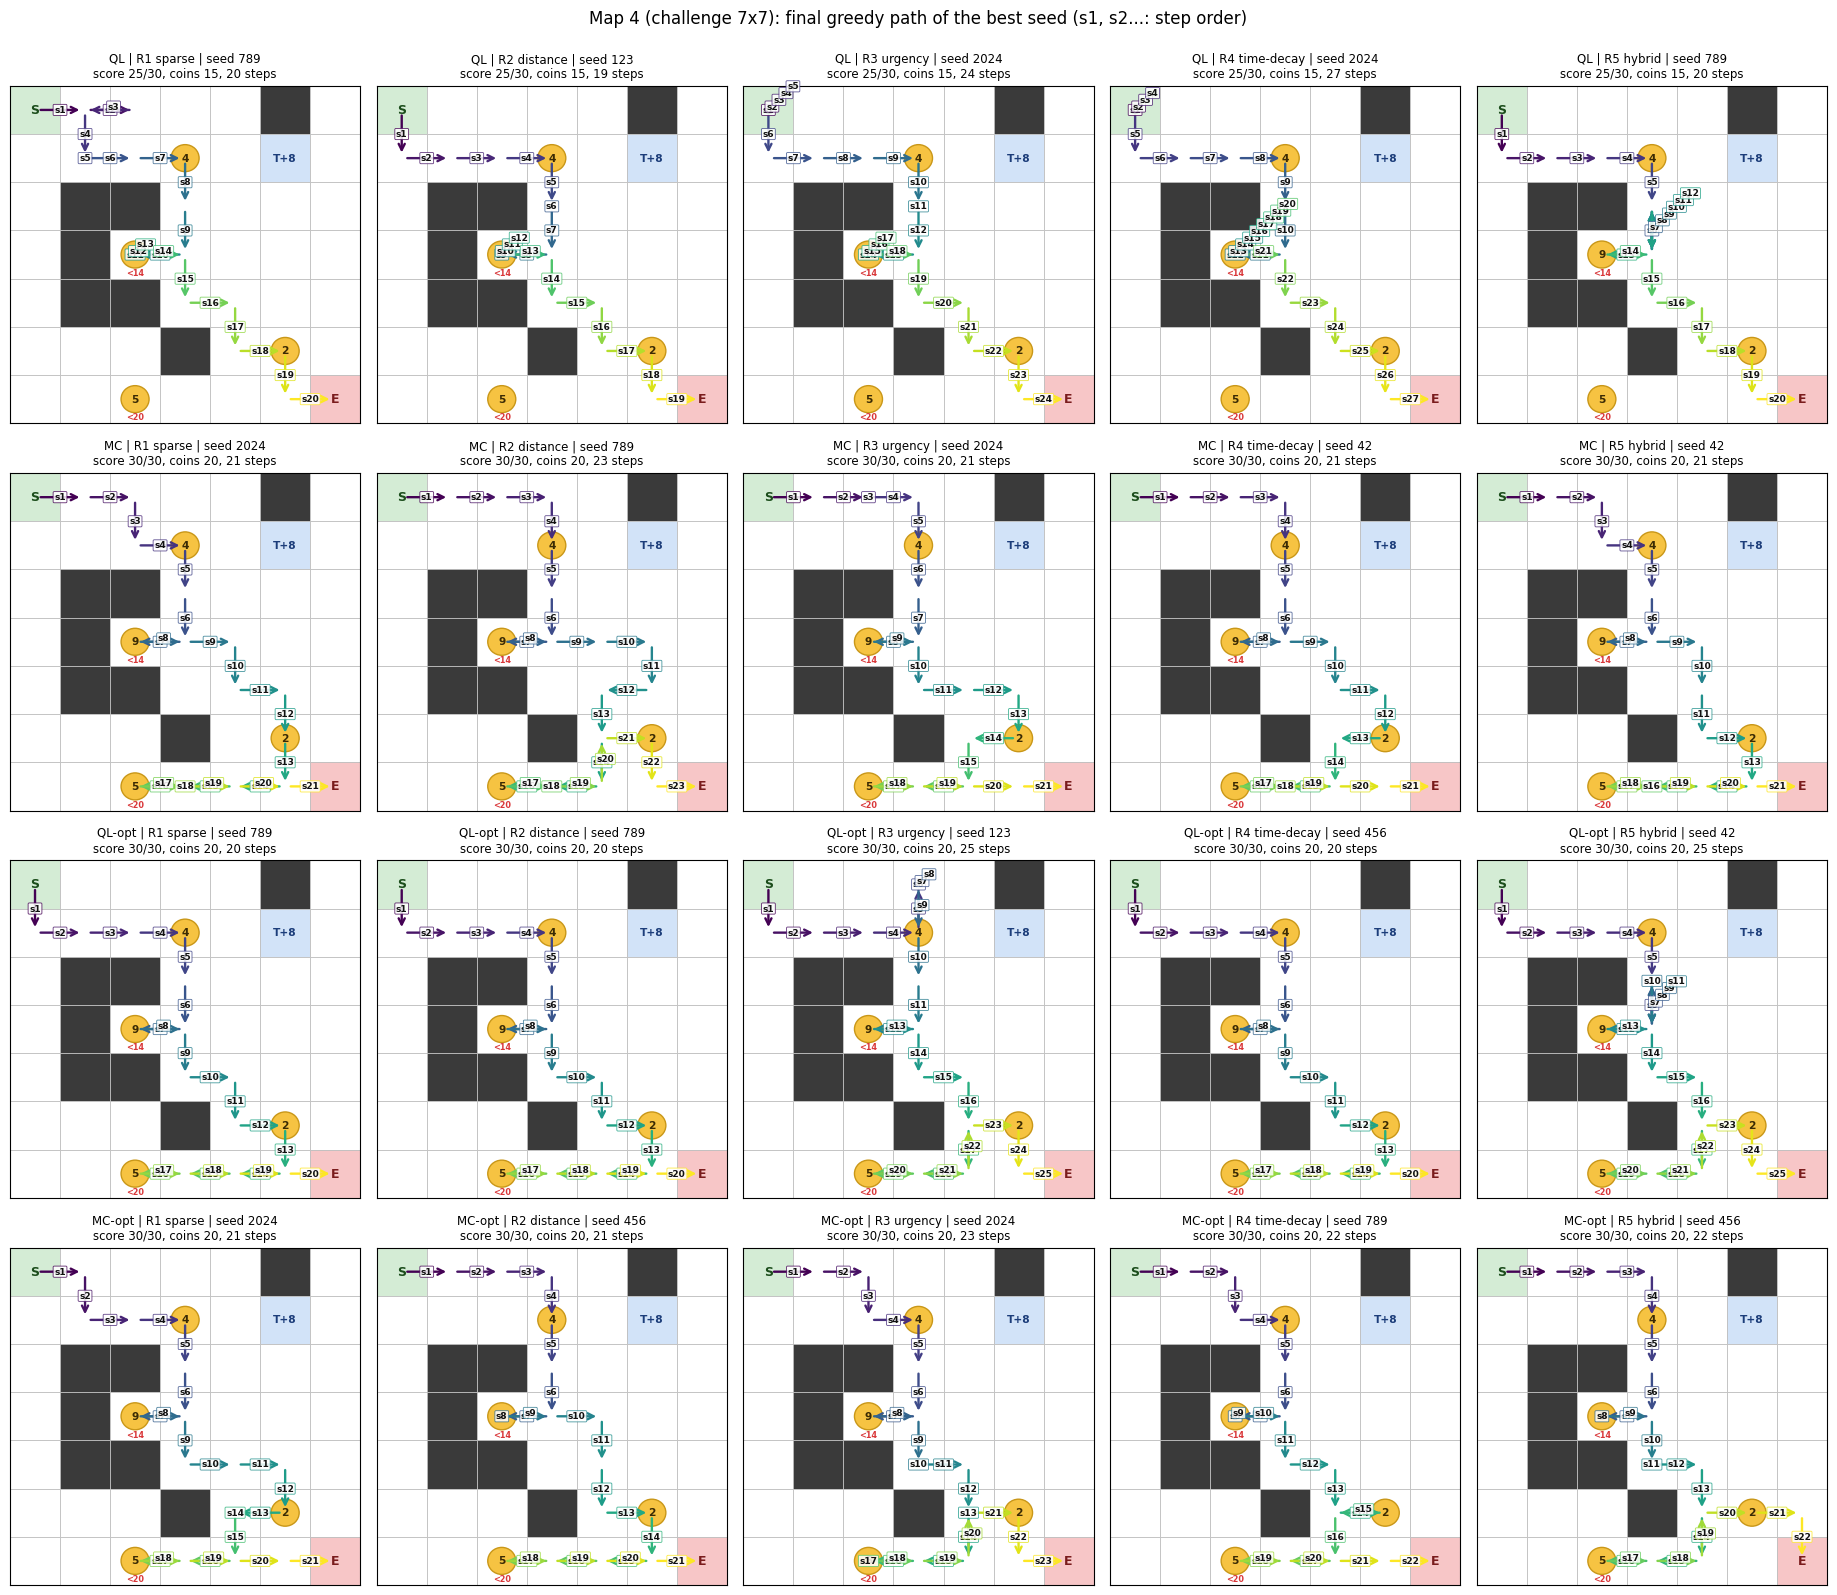

In [17]:
for m in MAPS:
    plot_trajectory_grid(RES, m)

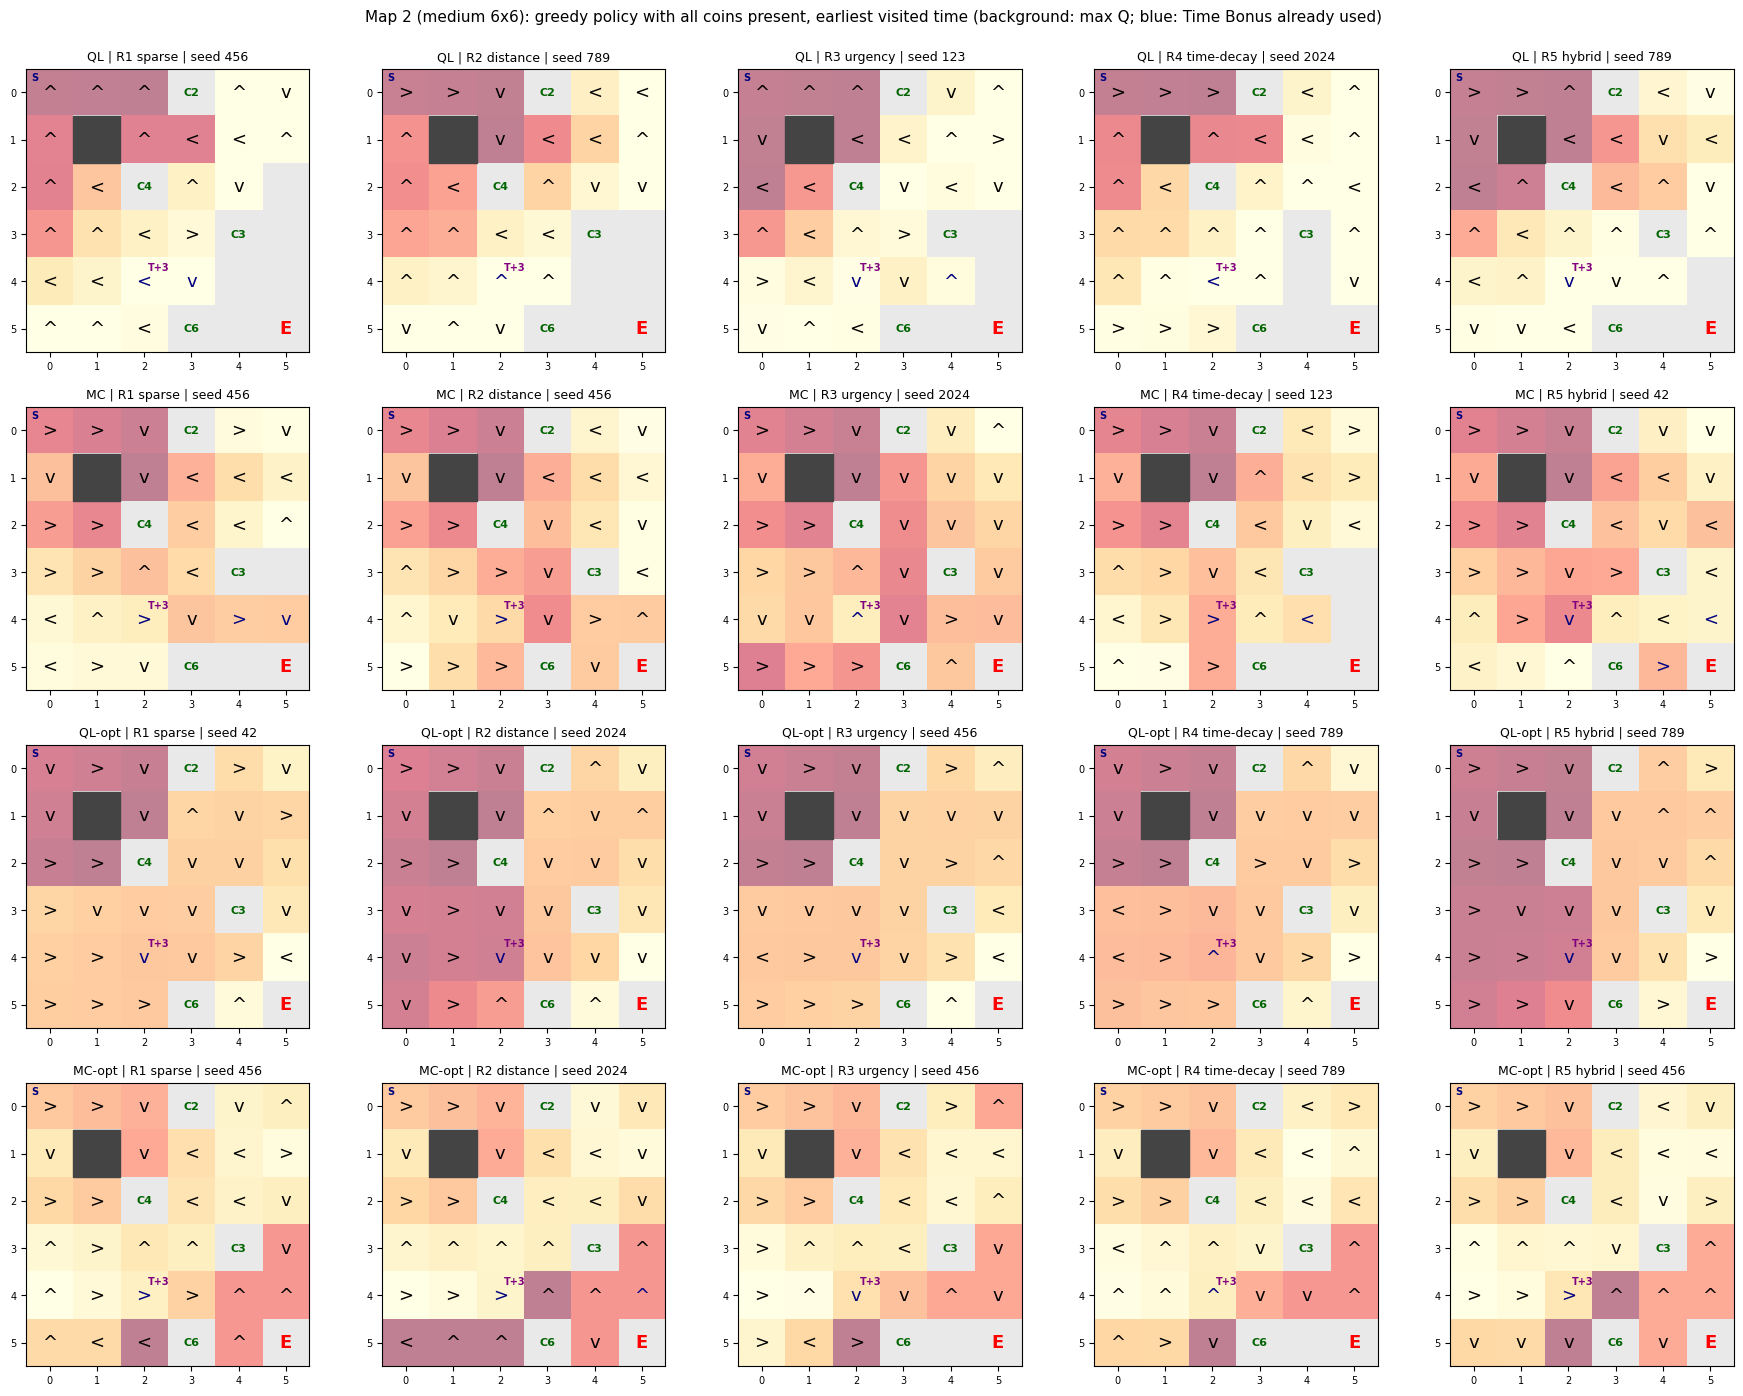

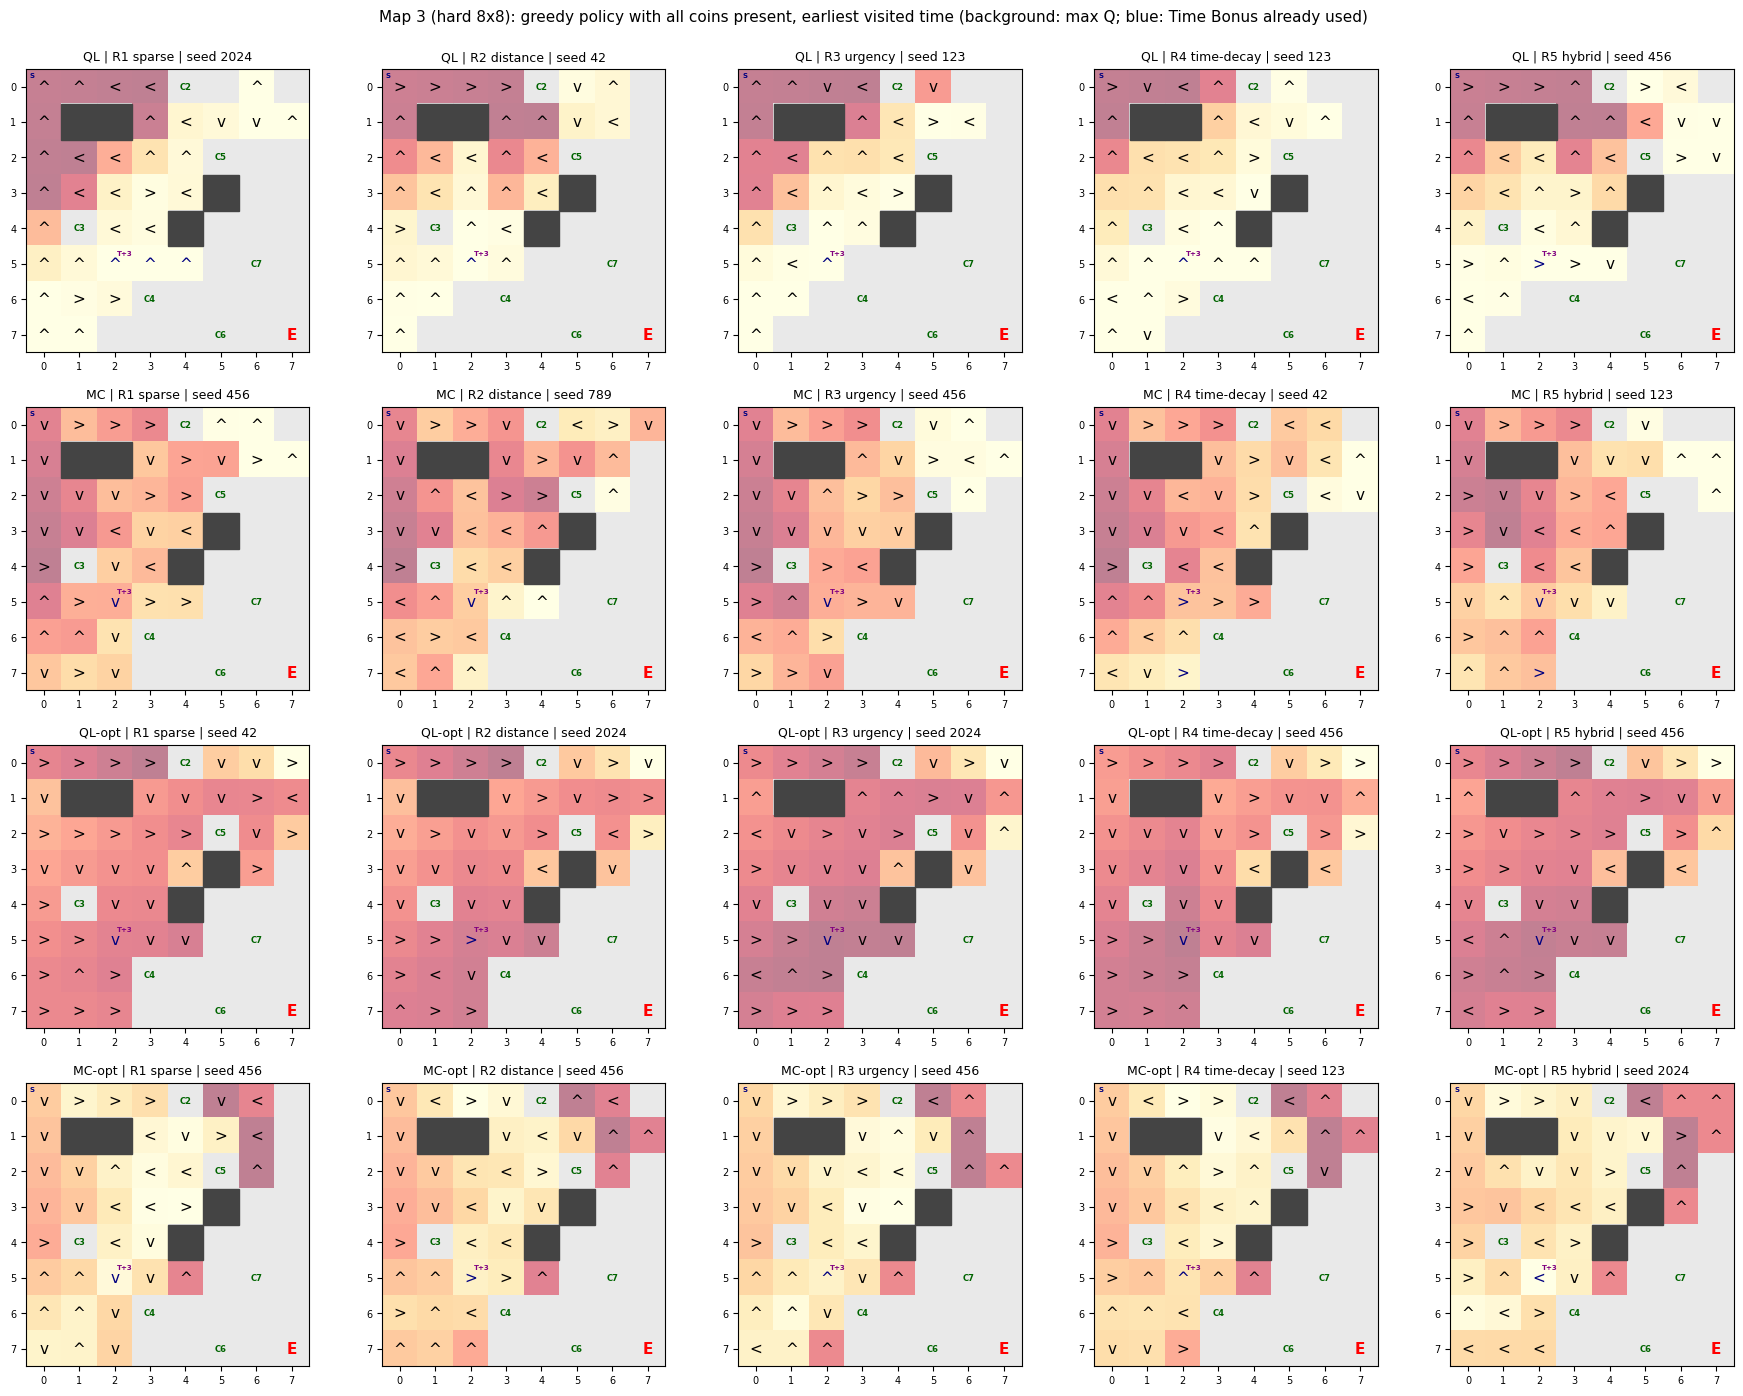

In [18]:
for m in (2, 3):
    plot_policy_grid(RES, m)

## **6.5 Reward làm thay đổi policy như thế nào?**

Bảng tóm tắt hành vi greedy trên Map 3 (coin nào được thu, theo thứ tự nào, có dùng Time Bonus, có tới Exit) cho QL khởi tạo 0, nơi reward ảnh hưởng mạnh nhất, và cho QL-opt.

In [19]:
PS = policy_summary(RES, 3, algos=["QL", "MC", "QL-opt"])
display(PS.set_index(["thuật toán", "reward"]))
display(policy_summary(RES, 2, algos=["QL", "QL-opt"]).set_index(["thuật toán", "reward"]))

coin thu (theo thứ tự)  tổng coin Exit  bước Time Bonus  va tường  điểm
thuật toán reward                                                                        
QL         R1                      3-4-6         13   có    23         có         9  23.0
           R2                    2-5-7-6         20   có    18      không         0  30.0
           R3                    2-5-7-6         20   có    20      không         2  30.0
           R4                  2-5-7-4-6         24   có    22      không         2  34.0
           R5                  2-5-7-4-6         24   có    24      không         2  34.0
MC         R1                    3-4-7-6         20   có    18         có         0  30.0
           R2                    3-4-7-6         20   có    18         có         0  30.0
           R3                    3-4-7-6         20   có    18         có         0  30.0
           R4                    3-4-7-6         20   có    18         có         0  30.0
           R5                    3-4-7-6         20   có    18         có         0  30.0
QL-opt     R1                2-5-7-3-4-6         27   có    26         có         0  37.0
           R2                2-5-7-3-4-6         27   có    26         có         0  37.0
           R3                2-5-7-3-4-6         27   có    27         có         1  37.0
           R4                2-5-7-3-4-6         27   có    26         có         0  37.0
           R5                2-5-7-3-4-6         27   có    27         có         1  37.0

coin thu (theo thứ tự)  tổng coin Exit  bước Time Bonus  va tường  điểm
thuật toán reward                                                                        
QL         R1                        4-6         10   có    14         có         2  20.0
           R2                      4-6-3         13   có    16         có         0  23.0
           R3                      4-6-3         13   có    15         có         1  23.0
           R4                      2-4-3          9   có    12      không         0  19.0
           R5                      4-6-3         13   có    15         có         1  23.0
QL-opt     R1                      4-6-3         13   có    14         có         0  23.0
           R2                      4-6-3         13   có    14         có         0  23.0
           R3                      4-6-3         13   có    15         có         1  23.0
           R4                      4-6-3         13   có    14         có         0  23.0
           R5                      4-6-3         13   có    15         có         1  23.0

# **Phần 7. Kiểm chứng nguyên nhân: vì sao thuật toán A tốt ở bản đồ X nhưng kém ở bản đồ Y?**



## **7.1 Loại trừ lỗi do reward (H0)**

VI cho chính sách tối ưu *theo từng reward*. Nếu điểm nhiệm vụ của chính sách đó bằng DP thì reward **đồng thuận** với mục tiêu và mọi thất bại phía sau là lỗi của thuật toán học, không phải của reward.

In [20]:
# ======================= Chẩn đoán nguyên nhân thất bại =======================
CAUSES = ["Optimal", "Deep exploration: later part of optimal path never tried", "Estimation: all tried but value wrong", "Reward: reward-optimal policy is not task-optimal"]
CAUSE_COLORS = ["#6fbf73", "#e8a33d", "#d9534f", "#7e6bc4"]


def qstar_continuation(M, cfg, rt, state):
    """Chuỗi (s, a*) tối ưu theo Q* tính từ state tới hết episode."""
    env = CoinCollectorEnv(cfg, rt)
    out, s = [], state
    while True:
        a = int(np.argmax(M["Qstar"][M["idx"][s]]))
        out.append((s, a))
        ns, _, _, ter, trun = env.transition(s, a)
        if ter or trun:
            return out
        s = ns


def first_error(cfg, Q, N, M, rt, tol=1e-6):
    """Quyết định SAI đầu tiên dọc theo đường đi greedy, so với Q* của chính reward dùng để huấn luyện.
    Kèm mức phủ của phần đường tối ưu nằm SAU điểm sai (các cặp (s, a*) đã từng được thử bao nhiêu lần).
    Trả về None nếu mọi quyết định đều tối ưu theo reward."""
    env = CoinCollectorEnv(cfg, 1)
    state, _ = env.reset()
    t = 0
    while True:
        qs = M["Qstar"][M["idx"][state]]
        q = Q.get(state)
        a = 0 if q is None else int(np.argmax(q))
        if qs[a] < qs.max() - tol:
            astar = int(np.argmax(qs))
            cont = qstar_continuation(M, cfg, rt, state)
            counts = [(N.get(s) or [0, 0, 0, 0])[ac] for s, ac in cont]
            first_un = next((i for i, c in enumerate(counts) if c == 0), -1)
            n = N.get(state)
            return {"t": t, "gap": float(qs.max() - qs[a]), "n_opt": n[astar] if n else 0,
                    "err_opt": (q[astar] - qs[astar]) if q else np.nan, "err_chosen": (q[a] - qs[a]) if q else np.nan,
                    "cont_len": len(cont), "min_n_cont": int(min(counts)), "n_unvisited": int(sum(c == 0 for c in counts)),
                    "first_unvisited": first_un}
        state, _, ter, trun, _ = env.step(a)
        t += 1
        if ter or trun:
            return None


def classify_run(m, rt, run):
    M = get_model(m, rt)
    fe = first_error(MAPS[m], run["Q"], run["N"], M, rt)
    if run["fin"]["score"] >= DP_SCORES[m] - 1e-9:
        return CAUSES[0], fe
    if fe is None:
        return CAUSES[3], fe
    return (CAUSES[1] if fe["min_n_cont"] == 0 else CAUSES[2]), fe


def diagnose(RES, algos=ALGOS4, maps=(1, 2, 3, 4), rewards=REWARDS):
    rows = []
    for m in maps:
        for a in algos:
            for rt in rewards:
                for run in RES[(m, a, rt)]["runs"]:
                    cause, fe = classify_run(m, rt, run)
                    rows.append({"map": m, "algo": a, "reward": rt, "seed": run["spec"]["seed"], "cause": cause,
                                 "score": run["fin"]["score"], **({} if fe is None else fe)})
    return pd.DataFrame(rows)


def plot_cause_bars(DIAG, algos=ALGOS4, maps=(1, 2, 3, 4)):
    fig, axes = plt.subplots(1, len(maps), figsize=(5.0 * len(maps), 4.2), sharey=True)
    for ax, m in zip(np.atleast_1d(axes), maps):
        sub = DIAG[DIAG["map"] == m]
        bottom = np.zeros(len(algos))
        for c, col in zip(CAUSES, CAUSE_COLORS):
            frac = np.array([(sub[sub["algo"] == a]["cause"] == c).mean() for a in algos])
            ax.bar(range(len(algos)), frac, bottom=bottom, color=col, label=c, edgecolor="white")
            for i, f in enumerate(frac):
                if f > 0.07:
                    ax.text(i, bottom[i] + f / 2, f"{100 * f:.0f}%", ha="center", va="center", fontsize=8.5, color="white", fontweight="bold")
            bottom += frac
        ax.set_xticks(range(len(algos)))
        ax.set_xticklabels(algos)
        ax.set_title(MAP_TITLES[m], fontsize=10.5)
        ax.grid(False)
    np.atleast_1d(axes)[0].set_ylabel("Fraction of runs (all rewards x all seeds)")
    h, l = np.atleast_1d(axes)[0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=2, fontsize=9)
    fig.suptitle("Cause of each run's result, classified by the first wrong decision of the greedy policy", fontsize=12)
    plt.tight_layout(rect=(0, 0.1, 1, 1))
    plt.show()


def optimal_path_states(m, rt):
    M = get_model(m, rt)
    env = CoinCollectorEnv(MAPS[m], rt)
    s = env.initial_state()
    out = []
    while True:
        a = int(np.argmax(M["Qstar"][M["idx"][s]]))
        out.append((s, a))
        ns, _, _, ter, trun = env.transition(s, a)
        if ter or trun:
            return out
        s = ns


def error_along_optimal_path(RES, m, rt, algos=ALGOS4):
    """Với mỗi bước t của đường tối ưu (theo Q*): sai số Q(s_t,a*) - Q*(s_t,a*) và số lần đã thử (s_t,a*), theo seed."""
    M = get_model(m, rt)
    path = optimal_path_states(m, rt)
    out = {}
    for a in algos:
        err = np.full((len(RES[(m, a, rt)]["runs"]), len(path)), np.nan)
        cnt = np.zeros_like(err)
        for k, run in enumerate(RES[(m, a, rt)]["runs"]):
            for t, (s, act) in enumerate(path):
                q, n = run["Q"].get(s), run["N"].get(s)
                cnt[k, t] = n[act] if n else 0
                if q is not None and cnt[k, t] > 0:
                    err[k, t] = q[act] - M["Qstar"][M["idx"][s], act]
        out[a] = (err, cnt)
    return path, out


def plot_error_along_path(RES, maps=(2, 3, 4), rt=1, algos=ALGOS4):
    fig, axes = plt.subplots(2, len(maps), figsize=(6.2 * len(maps), 7.4), squeeze=False)
    for j, m in enumerate(maps):
        path, out = error_along_optimal_path(RES, m, rt, algos)
        x = np.arange(len(path))
        for a in algos:
            err, cnt = out[a]
            mu = np.nanmean(np.where(np.isnan(err), np.nan, err), axis=0)
            sd = np.nanstd(err, axis=0)
            axes[0, j].plot(x, mu, "o-", ms=3, color=ALGO_COLORS[a], label=a, lw=1.3)
            axes[0, j].fill_between(x, mu - sd, mu + sd, color=ALGO_COLORS[a], alpha=0.12)
            axes[1, j].plot(x, (cnt > 0).mean(axis=0), "o-", ms=3, color=ALGO_COLORS[a], lw=1.3, label=a)
        axes[0, j].axhline(0, color="black", lw=0.8)
        axes[0, j].set_title(f"{MAP_TITLES[m]}: Q - Q* at (s_t, a*_t) on the optimal path ({REWARD_LABELS[rt]})", fontsize=9.5)
        axes[0, j].set_ylabel("Q - Q*  (negative: underestimate)")
        axes[1, j].set_ylim(-0.03, 1.05)
        axes[1, j].set_title("Fraction of seeds that ever tried the optimal action a*_t at s_t", fontsize=9.5)
        axes[1, j].set_xlabel("Step t along the optimal path")
        axes[1, j].set_ylabel("Fraction of seeds")
    axes[0, 0].legend(fontsize=8)
    plt.tight_layout()
    plt.show()


def reward_optimum_table():
    """Điểm nhiệm vụ của chính sách TỐI ƯU THEO TỪNG REWARD (VI). Nếu < DP thì chính reward làm lệch mục tiêu."""
    rows = []
    for m in MAPS:
        row = {"Bản đồ": MAP_TITLES[m], "DP (nhiệm vụ)": DP_SCORES[m]}
        for rt in REWARDS:
            M = get_model(m, rt)
            f = eval_policy_q(m, q_dict(M, M["Qstar"]))
            row[f"R{rt}"] = f["score"]
        rows.append(row)
    return pd.DataFrame(rows).set_index("Bản đồ")


In [21]:
RO = reward_optimum_table()
display(RO)
print('Chính sách tối ưu theo reward luôn đạt tối ưu nhiệm vụ:', bool((RO.drop(columns='DP (nhiệm vụ)').values == RO[['DP (nhiệm vụ)']].values).all()))

,DP (nhiệm vụ),R1,R2,R3,R4,R5
Bản đồ,,,,,,
Map 1 (easy 4x4),18.0,18.0,18.0,18.0,18.0,18.0
Map 2 (medium 6x6),23.0,23.0,23.0,23.0,23.0,23.0
Map 3 (hard 8x8),37.0,37.0,37.0,37.0,37.0,37.0
Map 4 (challenge 7x7),30.0,30.0,30.0,30.0,30.0,30.0


Chính sách tối ưu theo reward luôn đạt tối ưu nhiệm vụ: True


## **7.2 Điểm sai quyết định đầu tiên và mức phủ đường tối ưu (H1, H5)**

Với mỗi lượt chạy chưa đạt tối ưu, đi theo chính sách greedy tới **quyết định sai đầu tiên** (hành động có $Q^*$ thấp hơn hành động tối ưu, $Q^*$ tính bằng VI cho chính reward huấn luyện). Rồi xét phần đường tối ưu nằm **sau** điểm đó: nếu có cặp $(s,a^*)$ **chưa từng được thử** thì hành động đúng không thể được định giá đúng, vì phần "tương lai" của nó chưa bao giờ được trải nghiệm: đây là *khám phá sâu*. Nếu mọi cặp đều đã thử mà vẫn sai thì là *ước lượng* (nhiễu hoặc chệch).

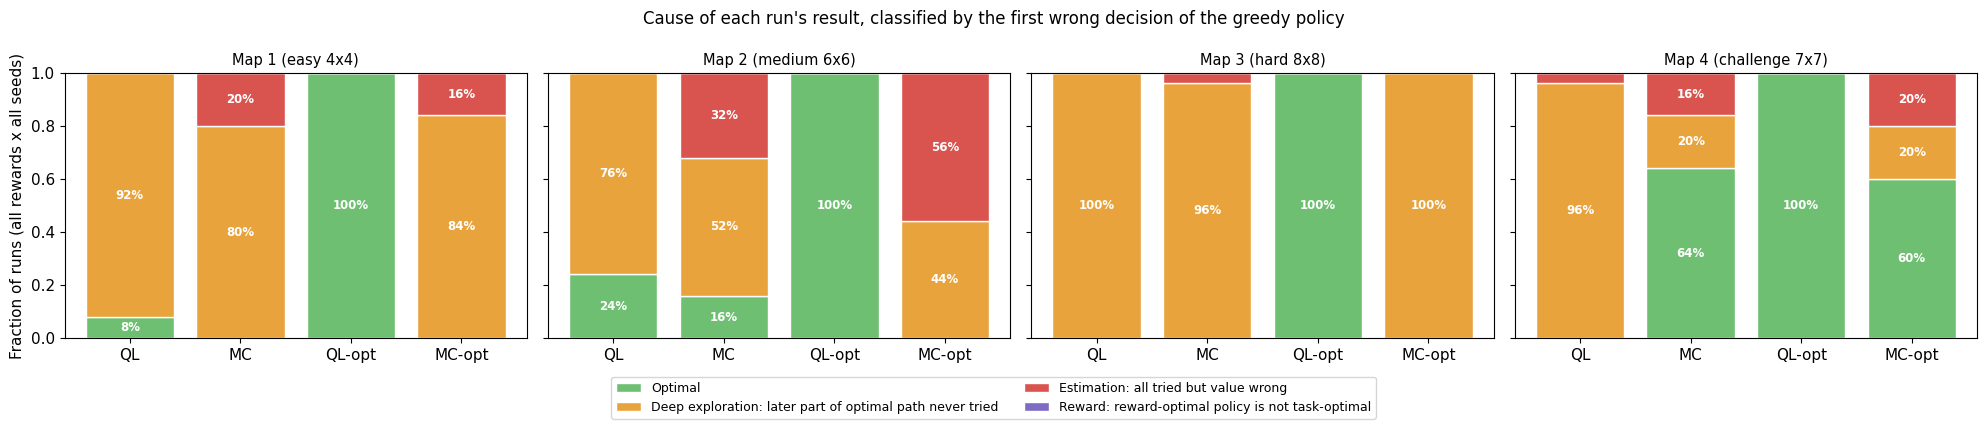

lượt_thất_bại  bước_sai_đầu_tiên  độ_dài_đường_tối_ưu_còn_lại  bước_chưa_thử_đầu_tiên  số_cặp_chưa_thử  sai_số_Q_hành_động_đúng  chênh_lệch_Q_thật
map algo                                                                                                                                                      
1   MC                 25                3.0                          7.0                     5.0             1.48                    -4.26               0.26
    MC-opt             25                3.0                          7.0                     5.0             1.48                    -4.32               0.34
    QL                 23                2.0                          8.0                     4.0             3.30                    -3.04               0.26
2   MC                 21                4.0                         10.0                     4.0             1.19                    -5.96               0.56
    MC-opt             25                4.0                         10.0                    -1.0             0.48                    -6.01               0.55
    QL                 19                0.0                         14.0                     5.0             5.21                    -5.34               0.22
3   MC                 25                0.0                         26.0                    12.0             7.12                   -20.55               1.94
    MC-opt             25                0.0                         26.0                    13.0             9.72                   -20.92               1.94
    QL                 25                0.0                         26.0                     6.0            15.20                    -4.99               0.32
4   MC                  9                6.0                         15.0                     4.0             2.78                    -5.67               0.25
    MC-opt             10                6.5                         16.0                     2.0             2.20                    -5.53               0.40
    QL                 25                0.0                         20.0                     6.0             9.04                    -4.87               0.30

In [22]:
DIAG = diagnose(RES)
plot_cause_bars(DIAG)
fail = DIAG[DIAG["cause"] != CAUSES[0]]
agg = fail.groupby(["map", "algo"]).agg(lượt_thất_bại=("seed", "size"), bước_sai_đầu_tiên=("t", "median"), độ_dài_đường_tối_ưu_còn_lại=("cont_len", "median"),
                                          bước_chưa_thử_đầu_tiên=("first_unvisited", "median"), số_cặp_chưa_thử=("n_unvisited", "mean"),
                                          sai_số_Q_hành_động_đúng=("err_opt", "median"), chênh_lệch_Q_thật=("gap", "median")).round(2)
display(agg)

## **7.3 Sai số Q dọc theo đường tối ưu (H1, H2)**

Trên đường tối ưu theo $Q^*$ (R1), hàng trên vẽ sai số $Q-Q^*$ tại $(s_t,a^*_t)$ (âm: đánh giá thấp; chỉ tính seed đã thử cặp đó), hàng dưới vẽ tỷ lệ seed đã **từng thử** hành động tối ưu tại bước đó.

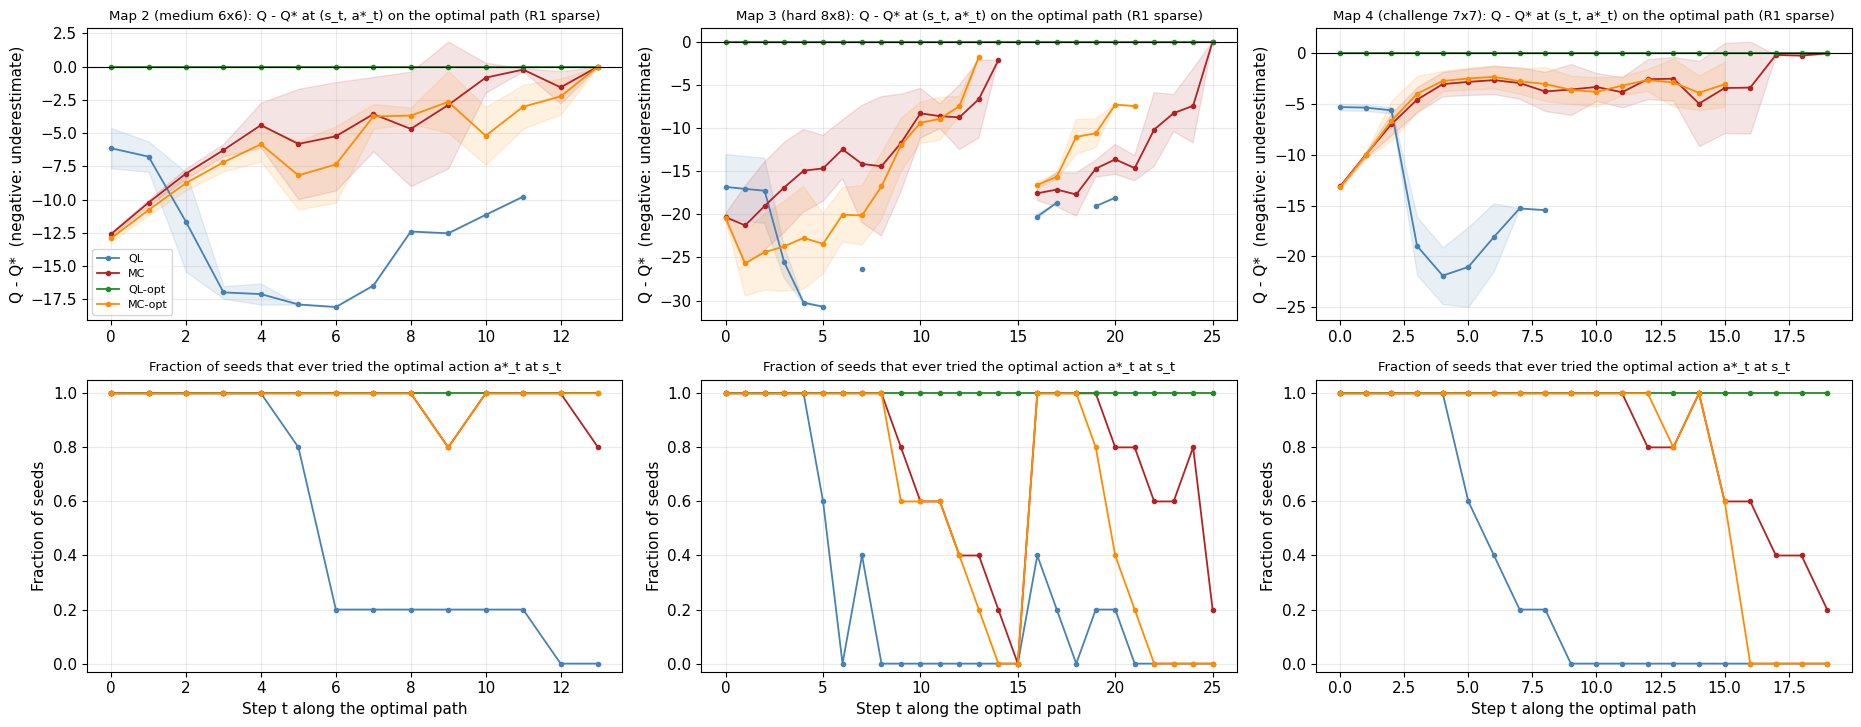

In [23]:
plot_error_along_path(RES, maps=(2, 3, 4), rt=1)

## **7.4 Can thiệp có kiểm soát (H1 đến H5)**

Mỗi can thiệp chỉ đổi một yếu tố, giữ nguyên mọi thứ khác (cùng bản đồ, reward, số episode, 5 seed). Mức đầu của mỗi trục là cấu hình gốc, lấy từ lưới chính.

- **I1 lạc quan hằng số:** khởi tạo mọi $Q=q_0$ ($q_0=30$ là cận trên hợp lệ). Nếu thiếu khám phá là nguyên nhân, QL phải cải thiện; nếu lạc quan bị return thực xóa nhanh, MC thì không.
- **I2 phạt bước:** đổi hệ số phạt bước của R1. Kèm đường tối ưu-theo-reward (VI) để biết phần giảm điểm nào do reward, phần nào do học.
- **I3 số mẫu ảo $n_0$:** làm lạc quan của MC-opt bền hơn (trọng số $n_0$ trong trung bình).
- **I4 epsilon cuối:** thêm khám phá *ngẫu nhiên không định hướng*.
- **I5 bước học hằng cho MC:** thay $1/N$ (nhớ mọi mẫu, kể cả thời kỳ gần ngẫu nhiên) bằng $\max(1/N,\alpha)$ (quên mẫu cũ). Kiểm tra giả thuyết cạnh tranh "chệch do mẫu cũ".
- **I6 exploring starts (can thiệp lý tưởng hóa):** một phần episode bắt đầu từ trạng thái đạt tới ngẫu nhiên, ép phủ sâu. Nếu cả QL và MC trở nên tối ưu thì giới hạn nằm ở **phủ trạng thái**, không phải ở công thức cập nhật.

[can thiệp] 240 lượt huấn luyện xong sau 1784s


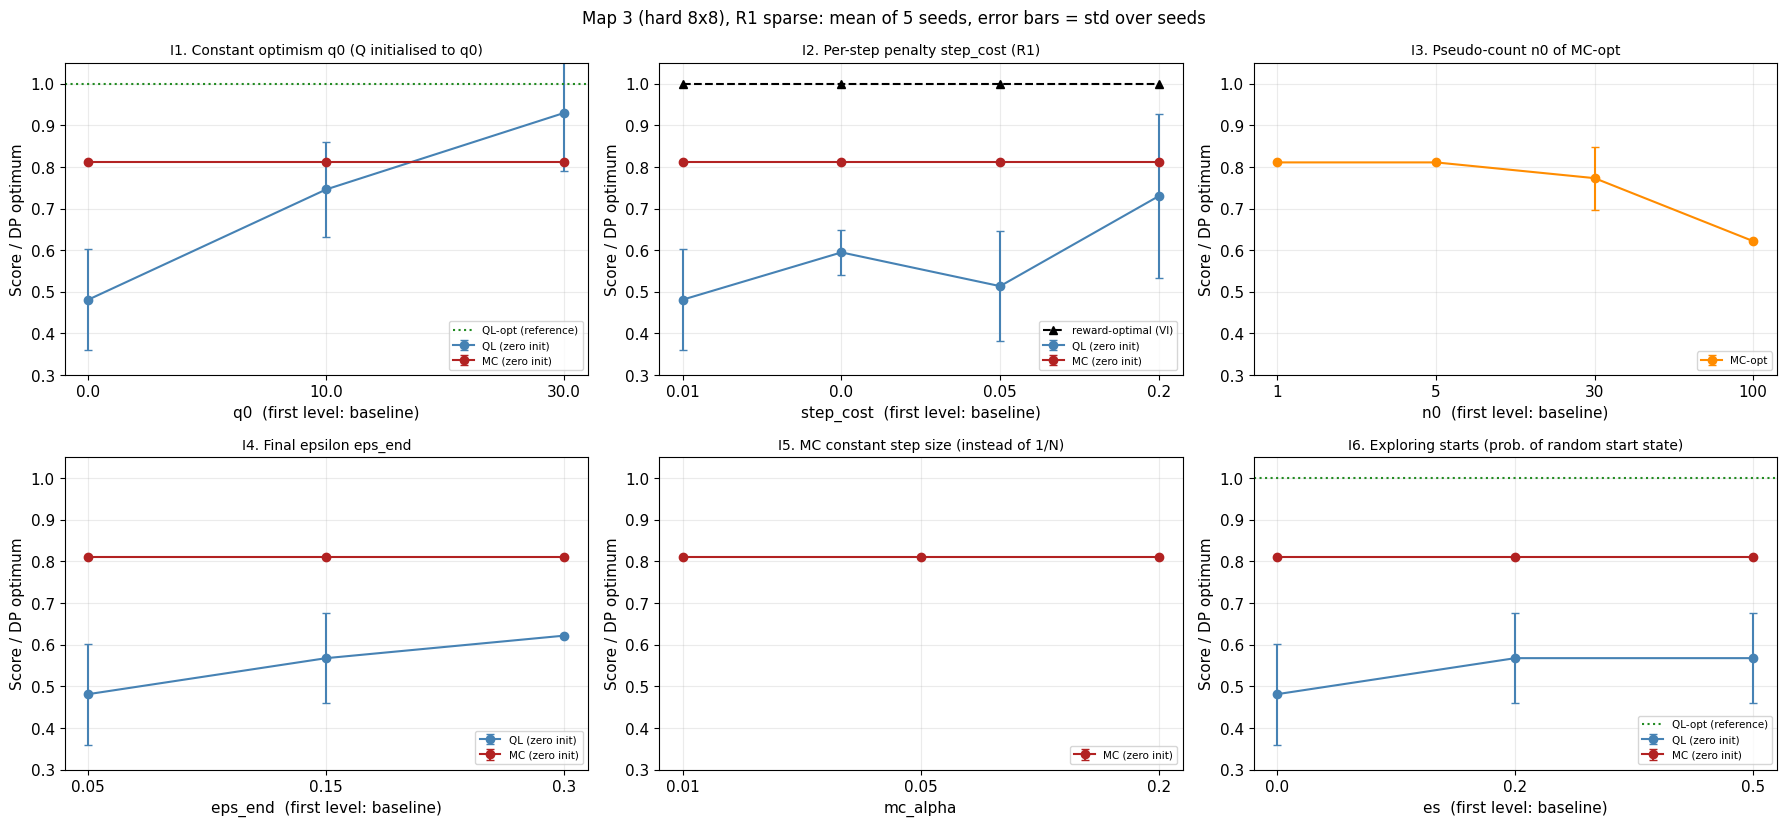

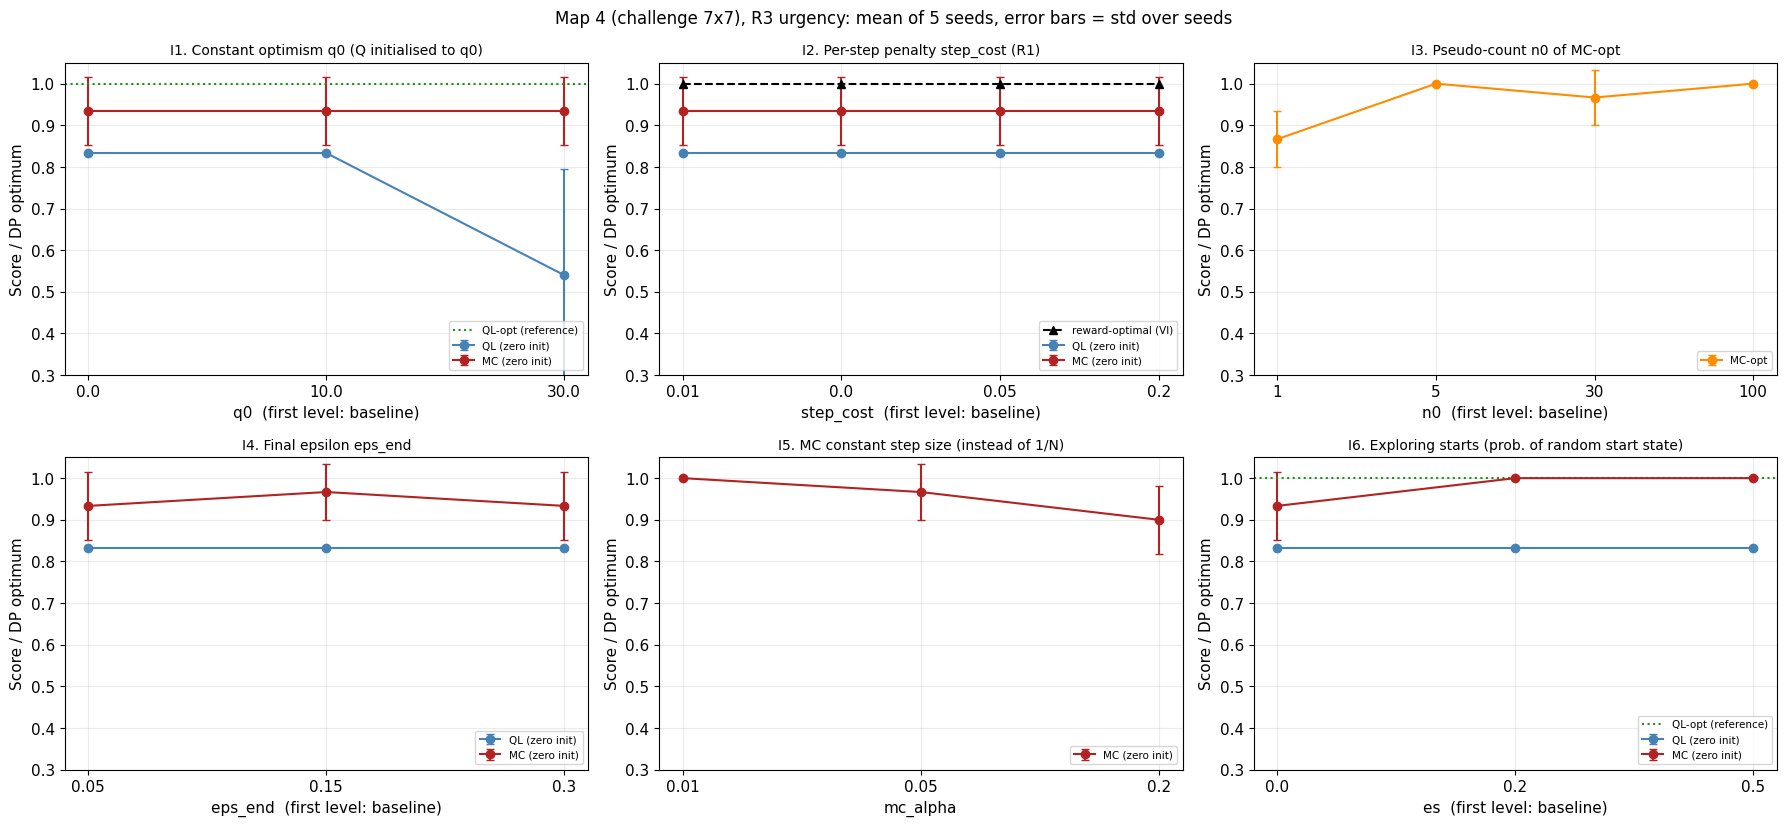

In [24]:
SWEEPS = {   # id: (tiêu đề, tham số, các mức, mức gốc, thuật toán, cách gắn vào spec)
    "I1": ("Constant optimism q0 (Q initialised to q0)", "q0", (10.0, 30.0), 0.0, ("QL", "MC")),
    "I2": ("Per-step penalty step_cost (R1)", "step_cost", (0.0, 0.05, 0.2), 0.01, ("QL", "MC")),
    "I3": ("Pseudo-count n0 of MC-opt", "n0", (5, 30, 100), 1, ("MC",)),
    "I4": ("Final epsilon eps_end", "eps_end", (0.15, 0.3), 0.05, ("QL", "MC")),
    "I5": ("MC constant step size (instead of 1/N)", "mc_alpha", (0.01, 0.05, 0.2), None, ("MC",)),
    "I6": ("Exploring starts (prob. of random start state)", "es", (0.2, 0.5), 0.0, ("QL", "MC")),
}
INT_SETTINGS = [(3, 1), (4, 3)]      # (bản đồ, reward): Map 3 nơi QL-0 kém nhất, Map 4 nơi MC thắng QL


def int_spec_kwargs(sid, param, v):
    if sid == "I3":
        return {"opt": True, "n0": v}
    if sid == "I4":
        return {"hp": {"eps_end": v}}
    if sid == "I5":
        return {"hp": {"alpha": v}}
    return {param: v}


plan = {}
for (m, rt) in INT_SETTINGS:
    for sid, (_, param, values, base, algos) in SWEEPS.items():
        for a in algos:
            for v in values:
                plan[(m, rt, sid, a, v)] = (make_specs(a, MAPS[m], rt, N_EP[m], SEEDS, **int_spec_kwargs(sid, param, v)), DP_SCORES[m])
INT = run_configs(plan, "can thiệp")


def int_point(m, rt, sid, a, v, base):
    if v == base:                                   # mức gốc: lấy từ lưới chính, không chạy lại
        return RES[(m, a + ("-opt" if sid == "I3" else ""), rt)]
    return INT[(m, rt, sid, a, v)]


rows = []
fig_axes = {}
for (m, rt) in INT_SETTINGS:
    fig, axes = plt.subplots(2, 3, figsize=(18, 8.4))
    for ax, (sid, (title, param, values, base, algos)) in zip(axes.ravel(), SWEEPS.items()):
        xs = ([base] if base is not None else []) + list(values)
        for a in algos:
            lab = a + ("-opt" if sid == "I3" else " (zero init)")
            pts = [int_point(m, rt, sid, a, v, base) if base is not None else (INT[(m, rt, sid, a, v)]) for v in xs]
            mu = np.array([p["ratio"] for p in pts])
            sd = np.array([p["greedy_std"] / p["dp"] for p in pts])
            ax.errorbar(range(len(xs)), mu, yerr=sd, fmt="o-", capsize=3, color=ALGO_COLORS[a + ("-opt" if sid == "I3" else "")], label=lab)
            for v, p in zip(xs, pts):
                rows.append({"bản đồ": m, "reward": f"R{rt}", "can thiệp": sid, "thuật toán": lab, "tham số": param, "giá trị": v,
                             "điểm greedy": p["greedy"], "tỷ lệ": p["ratio"], "seed tối ưu": f"{p['n_opt']}/{p['n_seeds']}",
                             "độ phủ (%)": 100 * p["n_states"] / DP[m]["reachable"]})
        if sid in ("I1", "I6"):
            ax.axhline(RES[(m, "QL-opt", rt)]["ratio"], color=ALGO_COLORS["QL-opt"], ls=":", label="QL-opt (reference)")
        if sid == "I2":
            ref = []
            for v in xs:
                Mv = build_model(MAPS[m], rt, step_cost=v)
                ref.append(eval_policy_q(m, q_dict(Mv, value_iteration(Mv)["Q"]))["score"] / DP_SCORES[m])
            ax.plot(range(len(xs)), ref, "k^--", label="reward-optimal (VI)")
        ax.set_xticks(range(len(xs)))
        ax.set_xticklabels([str(v) for v in xs])
        ax.set_xlabel(param + ("  (first level: baseline)" if base is not None else ""))
        ax.set_ylabel("Score / DP optimum")
        ax.set_ylim(0.3, 1.05)
        ax.set_title(f"{sid}. {title}", fontsize=10)
        ax.legend(fontsize=7.5, loc="lower right")
    fig.suptitle(f"{MAP_TITLES[m]}, {REWARD_LABELS[rt]}: mean of {len(SEEDS)} seeds, error bars = std over seeds", fontsize=12)
    plt.tight_layout()
    plt.show()
for _r in INT.values():                      # giải phóng bộ nhớ: chỉ cần thống kê đã gộp
    _r.pop("runs", None); _r.pop("best_Q", None)
INT_DF = pd.DataFrame(rows)
display(INT_DF.set_index(["bản đồ", "reward", "can thiệp", "thuật toán", "giá trị"])[["điểm greedy", "tỷ lệ", "seed tối ưu", "độ phủ (%)"]]
        .style.format({"điểm greedy": "{:.1f}", "tỷ lệ": "{:.3f}", "độ phủ (%)": "{:.1f}"}).background_gradient(subset=["tỷ lệ"], cmap="YlGn", vmin=0.5, vmax=1.0))


# **Phần 8. Độ nhạy theo tham số môi trường**

Bốn yếu tố của môi trường được đổi riêng lẻ, R3, 5 seed: (a) ngân sách bước `max_steps`, (b) kích thước không gian trạng thái (hệ quả của (a)), (c) hạn biến mất của coin, (d) vai trò của Time Bonus. Điểm tối ưu DP được tính lại cho từng cấu hình nên mọi so sánh đều theo tỷ lệ với tối ưu *của chính cấu hình đó*.

[độ nhạy] 500 lượt huấn luyện xong sau 1142s


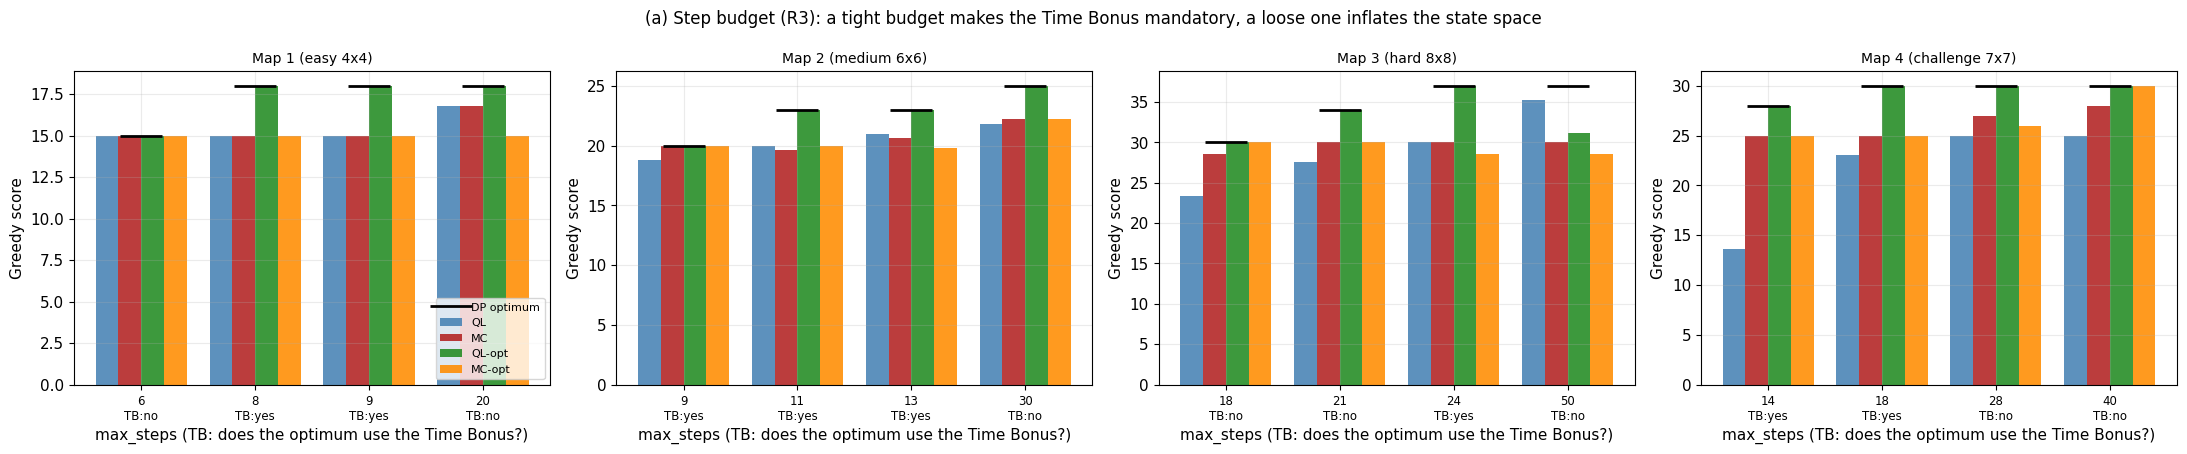

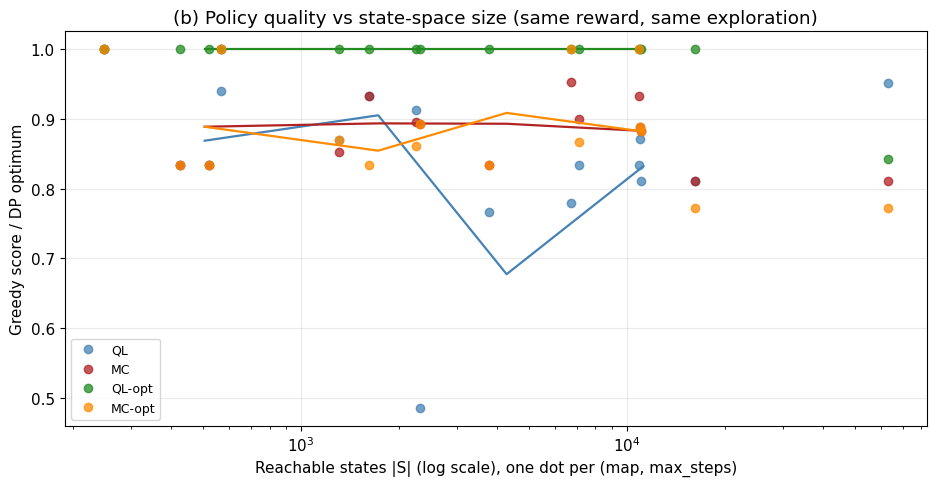

thuật toán                             MC  MC-opt    QL  QL-opt
map mức |S| đạt tới DP   Time Bonus                            
1   6   248         15.0 no          15.0    15.0  15.0    15.0
    8   426         18.0 yes         15.0    15.0  15.0    18.0
    9   523         18.0 yes         15.0    15.0  15.0    18.0
    20  1612        18.0 no          16.8    15.0  16.8    18.0
2   9   569         20.0 yes         20.0    20.0  18.8    20.0
    11  1308        23.0 yes         19.6    20.0  20.0    23.0
    13  2252        23.0 yes         20.6    19.8  21.0    23.0
    30  10948       25.0 no          22.2    22.2  21.8    25.0
3   18  6736        30.0 no          28.6    30.0  23.4    30.0
    21  11022       34.0 no          30.0    30.0  27.6    34.0
    24  16109       37.0 yes         30.0    28.6  30.0    37.0
    50  63085       37.0 no          30.0    28.6  35.2    31.2
4   14  2312        28.0 yes         25.0    25.0  13.6    28.0
    18  3763        30.0 yes         25.0    25.0  23.0    30.0
    28  7117        30.0 no          27.0    26.0  25.0    30.0
    40  10909       30.0 no          28.0    30.0  25.0    30.0

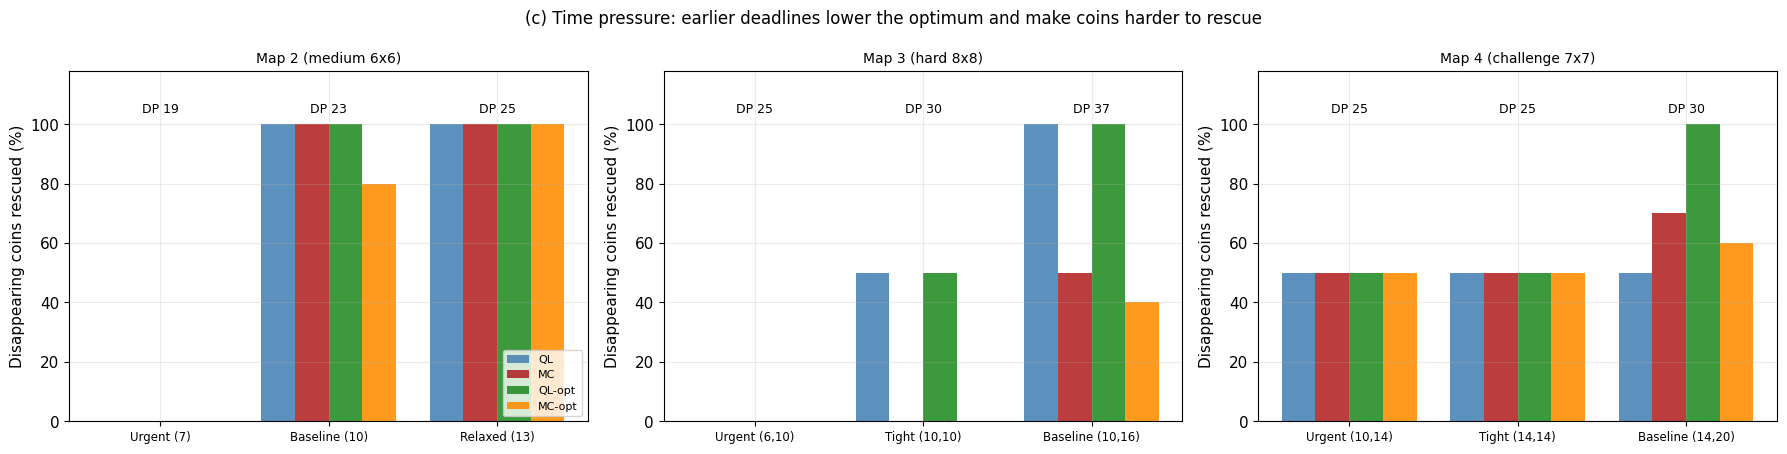

thuật toán                   MC  MC-opt    QL  QL-opt
map mức              DP                              
2   Baseline (10)    23.0  20.6    19.8  21.0    23.0
    Relaxed (13)     25.0  21.0    21.4  20.0    25.0
    Urgent (7)       19.0  17.4    17.0  14.2    19.0
3   Baseline (10,16) 37.0  30.0    28.6  30.0    37.0
    Tight (10,10)    30.0  23.0    23.0  28.6    30.0
    Urgent (6,10)    25.0  23.0    23.0  17.0    25.0
4   Baseline (14,20) 30.0  27.0    26.0  25.0    30.0
    Tight (14,14)    25.0  25.0    25.0  25.0    25.0
    Urgent (10,14)   25.0  25.0    25.0  25.0    25.0

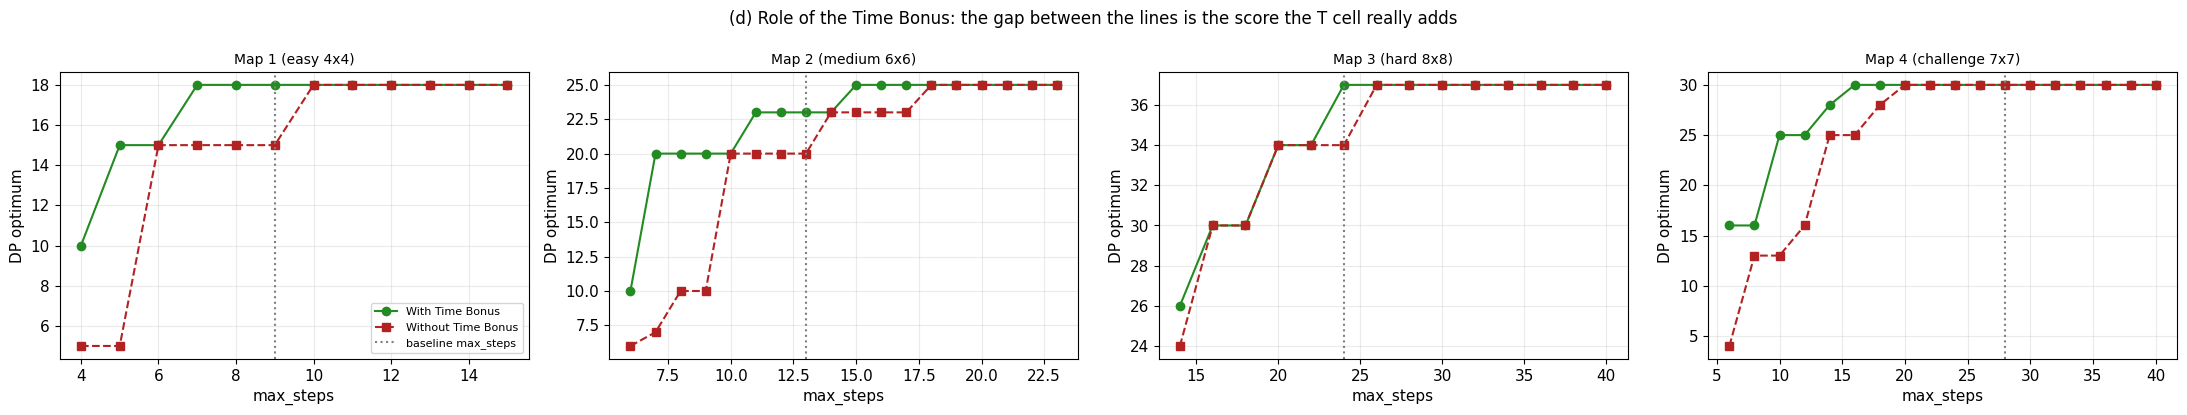

In [25]:
# Độ nhạy theo tham số môi trường (ablation)
ABL_ALGOS = ["QL", "MC", "QL-opt", "MC-opt"]
ABL_RT = 3
BUDGETS = {1: [6, 8, 9, 20], 2: [9, 11, 13, 30], 3: [18, 21, 24, 50], 4: [14, 18, 28, 40]}
DEADLINES = {
    2: [({(5, 3): 7}, "Urgent (7)"), ({(5, 3): 10}, "Baseline (10)"), ({(5, 3): 13}, "Relaxed (13)")],
    3: [({(2, 5): 6, (5, 6): 10}, "Urgent (6,10)"), ({(2, 5): 10, (5, 6): 10}, "Tight (10,10)"), ({(2, 5): 10, (5, 6): 16}, "Baseline (10,16)")],
    4: [({(3, 2): 10, (6, 2): 14}, "Urgent (10,14)"), ({(3, 2): 14, (6, 2): 14}, "Tight (14,14)"), ({(3, 2): 14, (6, 2): 20}, "Baseline (14,20)")],
}

# ---- (a) ngân sách bước + (b) hạn biến mất: gộp thành một lượt chạy song song ----
plan, meta = {}, {}
for m, levels in BUDGETS.items():
    for ms in levels:
        cfg = make_cfg(m, max_steps=ms)
        sol = solve_optimal(cfg)
        meta[("B", m, ms)] = sol
        for a in ABL_ALGOS:
            plan[("B", m, ms, a)] = (make_specs(a.split("-")[0], cfg, ABL_RT, N_EP_ABL[m], SEEDS, opt=a.endswith("opt")), sol["score"])
for m, levels in DEADLINES.items():
    for dis, lbl in levels:
        cfg = make_cfg(m, disappear_info=dict(dis))
        sol = solve_optimal(cfg)
        meta[("D", m, lbl)] = sol
        for a in ABL_ALGOS:
            plan[("D", m, lbl, a)] = (make_specs(a.split("-")[0], cfg, ABL_RT, N_EP_ABL[m], SEEDS, opt=a.endswith("opt")), sol["score"])
ABL = run_configs(plan, "độ nhạy")
for _r in ABL.values():
    _r.pop("runs", None); _r.pop("best_Q", None)

rows = []
for (kind, m, lv, a), r in ABL.items():
    sol = meta[(kind, m, lv)]
    e = [x for x in r["e2o"] if not np.isnan(x)]
    rows.append({"loại": "ngân sách bước" if kind == "B" else "hạn biến mất", "map": m, "mức": lv, "|S| đạt tới": sol["reachable"],
                 "DP": sol["score"], "Time Bonus": "yes" if sol["bonus"] else "no", "thuật toán": a, "greedy": r["greedy"], "tỷ lệ": r["ratio"],
                 "seed tối ưu": r["n_opt"], "cứu coin biến mất (%)": 100 * r["greedy_dis"], "dùng bonus": r["bonus"], "E2O trung vị": np.median(e) if e else np.nan})
ABL_DF = pd.DataFrame(rows)

# ---- Biểu đồ (a): điểm greedy theo ngân sách bước ----
bd = ABL_DF[ABL_DF["loại"] == "ngân sách bước"]
fig, axes = plt.subplots(1, 4, figsize=(22, 4.6))
for ax, m in zip(axes, BUDGETS):
    sub = bd[bd["map"] == m]
    levels = BUDGETS[m]
    w = 0.2
    for j, a in enumerate(ABL_ALGOS):
        ys = [sub[(sub["mức"] == ms) & (sub["thuật toán"] == a)]["greedy"].iloc[0] for ms in levels]
        ax.bar(np.arange(len(levels)) + (j - 1.5) * w, ys, w, color=ALGO_COLORS[a], label=a, alpha=.88)
    dps = [sub[sub["mức"] == ms]["DP"].iloc[0] for ms in levels]
    ax.plot(range(len(levels)), dps, "k_", ms=30, mew=2, label="DP optimum")
    ax.set_xticks(range(len(levels)))
    ax.set_xticklabels([f"{ms}\nTB:{sub[sub['mức'] == ms]['Time Bonus'].iloc[0]}" for ms in levels], fontsize=8.5)
    ax.set_xlabel("max_steps (TB: does the optimum use the Time Bonus?)")
    ax.set_ylabel("Greedy score")
    ax.set_title(MAP_TITLES[m], fontsize=10)
axes[0].legend(fontsize=8, loc="lower right")
fig.suptitle(f"(a) Step budget (R{ABL_RT}): a tight budget makes the Time Bonus mandatory, a loose one inflates the state space", fontsize=12)
plt.tight_layout()
plt.show()

# ---- Biểu đồ (b): tỷ lệ so với DP theo kích thước không gian trạng thái ----
fig, ax = plt.subplots(figsize=(9.5, 5))
for a in ABL_ALGOS:
    sub = bd[bd["thuật toán"] == a].sort_values("|S| đạt tới")
    ax.plot(sub["|S| đạt tới"], sub["tỷ lệ"], "o", color=ALGO_COLORS[a], alpha=.75, label=a)
    # xu hướng: trung bình theo log-bin
    bins = np.logspace(np.log10(bd["|S| đạt tới"].min()), np.log10(bd["|S| đạt tới"].max()), 6)
    xs_, ys_ = [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        g = sub[(sub["|S| đạt tới"] >= lo) & (sub["|S| đạt tới"] <= hi)]
        if len(g):
            xs_.append(g["|S| đạt tới"].mean())
            ys_.append(g["tỷ lệ"].mean())
    ax.plot(xs_, ys_, "-", color=ALGO_COLORS[a], lw=1.6)
ax.set_xscale("log")
ax.set_xlabel("Reachable states |S| (log scale), one dot per (map, max_steps)")
ax.set_ylabel("Greedy score / DP optimum")
ax.set_title("(b) Policy quality vs state-space size (same reward, same exploration)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()
display(bd.pivot_table(index=["map", "mức", "|S| đạt tới", "DP", "Time Bonus"], columns="thuật toán", values="greedy").round(1))

# ---- (c) hạn biến mất ----
dd = ABL_DF[ABL_DF["loại"] == "hạn biến mất"]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
for ax, m in zip(axes, DEADLINES):
    sub = dd[dd["map"] == m]
    lv = [l for _, l in DEADLINES[m]]
    for j, a in enumerate(ABL_ALGOS):
        ys = [sub[(sub["mức"] == l) & (sub["thuật toán"] == a)]["cứu coin biến mất (%)"].iloc[0] for l in lv]
        ax.bar(np.arange(len(lv)) + (j - 1.5) * 0.2, ys, 0.2, color=ALGO_COLORS[a], label=a, alpha=.88)
    for i, l in enumerate(lv):
        ax.text(i, 104, f"DP {sub[sub['mức'] == l]['DP'].iloc[0]:.0f}", ha="center", fontsize=9)
    ax.set_xticks(range(len(lv)))
    ax.set_xticklabels(lv, fontsize=8.5)
    ax.set_ylim(0, 118)
    ax.set_ylabel("Disappearing coins rescued (%)")
    ax.set_title(MAP_TITLES[m], fontsize=10)
axes[0].legend(fontsize=8, loc="lower right")
fig.suptitle("(c) Time pressure: earlier deadlines lower the optimum and make coins harder to rescue", fontsize=12)
plt.tight_layout()
plt.show()
display(dd.pivot_table(index=["map", "mức", "DP"], columns="thuật toán", values="greedy").round(1))

# ---- (d) vai trò của Time Bonus: điểm tối ưu DP có và không có Time Bonus theo ngân sách ----
TB_RANGE = {1: range(4, 16), 2: range(6, 24), 3: range(14, 41, 2), 4: range(6, 42, 2)}
fig, axes = plt.subplots(1, 4, figsize=(22, 4.2))
for ax, m in zip(axes, MAPS):
    xs = list(TB_RANGE[m])
    w_tb = [solve_optimal(make_cfg(m, max_steps=ms))["score"] for ms in xs]
    n_tb = [solve_optimal(make_cfg(m, max_steps=ms, time_bonus_pos=None))["score"] for ms in xs]
    ax.plot(xs, w_tb, "o-", color="forestgreen", label="With Time Bonus")
    ax.plot(xs, n_tb, "s--", color="firebrick", label="Without Time Bonus")
    ax.axvline(MAPS[m]["max_steps"], color="gray", ls=":", label="baseline max_steps")
    ax.set_xlabel("max_steps")
    ax.set_ylabel("DP optimum")
    ax.set_title(MAP_TITLES[m], fontsize=10)
axes[0].legend(fontsize=8)
fig.suptitle("(d) Role of the Time Bonus: the gap between the lines is the score the T cell really adds", fontsize=12)
plt.tight_layout()
plt.show()


# **Phần 9. Thuật toán bổ sung: Sarsa, VI, PI, TPI so với Q-Learning và Monte Carlo**

Hai thuật toán chính: (a) Sarsa so với QL và MC (cùng họ học theo mẫu), (b) VI, PI, TPI giải bằng mô hình, (c) so sánh thống nhất về chất lượng và chi phí.

## **9.1 Sarsa so với Q-Learning và Monte Carlo**

[Sarsa] 200 lượt huấn luyện xong sau 1811s


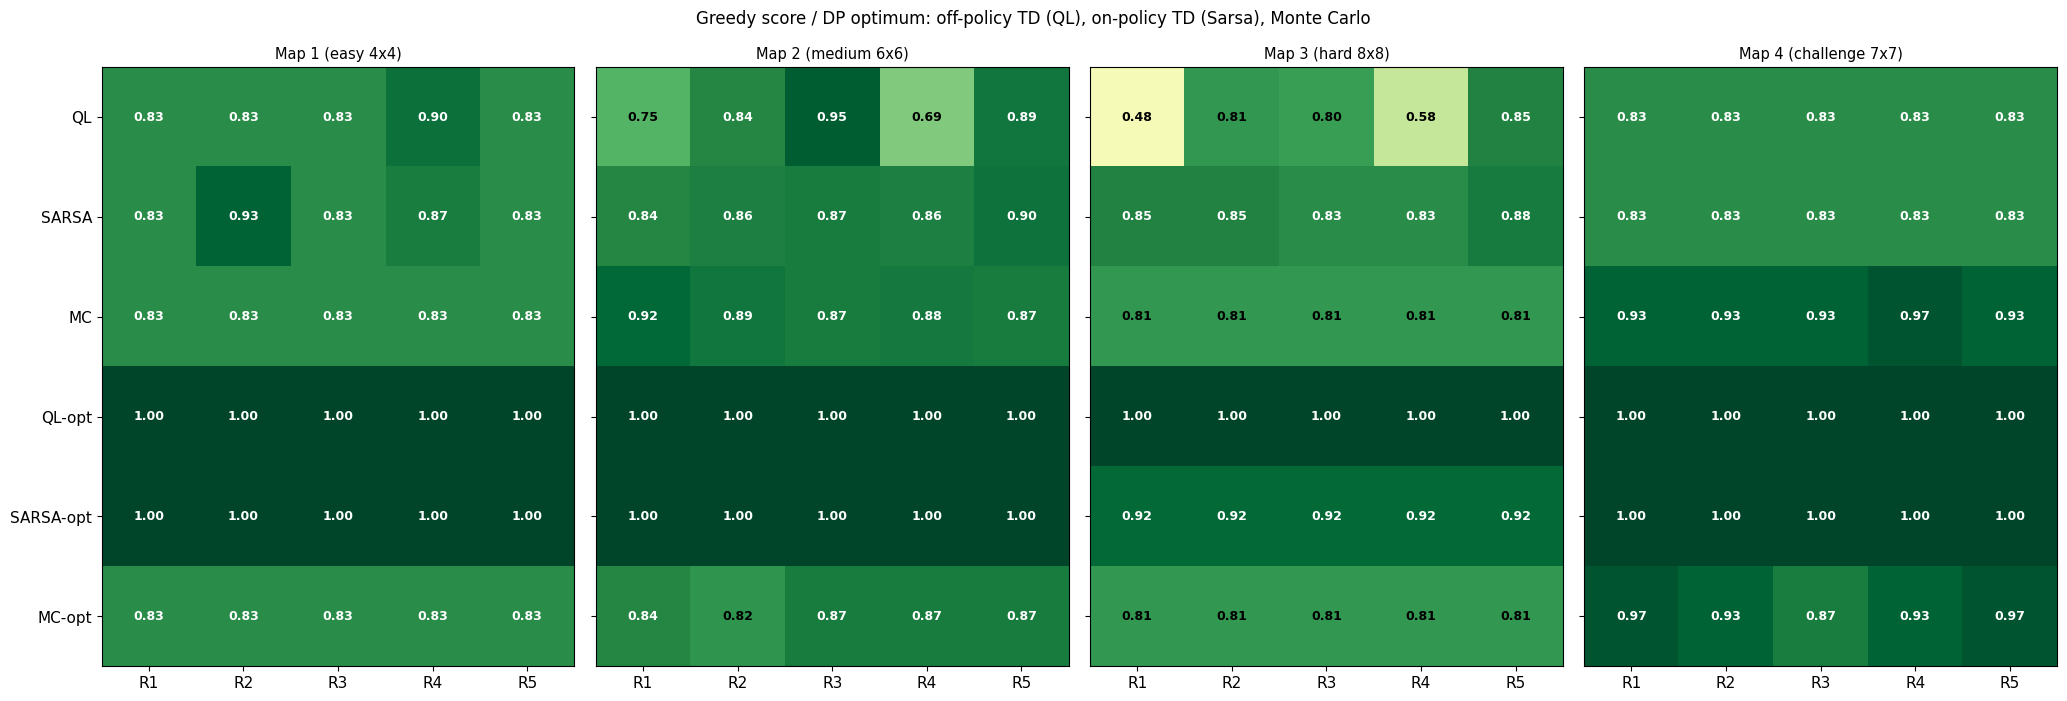

,Map 1,Map 2,Map 3,Map 4,Trung bình
QL,0.847,0.823,0.706,0.833,0.802
SARSA,0.860,0.866,0.850,0.833,0.852
MC,0.833,0.885,0.811,0.940,0.867
QL-opt,1.000,1.000,1.000,1.000,1.000
SARSA-opt,1.000,1.000,0.919,1.000,0.980
MC-opt,0.833,0.854,0.811,0.933,0.858


In [26]:
cfgs = {}
for m in MAPS:
    for a in ("SARSA", "SARSA-opt"):
        for rt in REWARDS:
            cfgs[(m, a, rt)] = (make_specs("SARSA", MAPS[m], rt, N_EP[m], SEEDS, opt=a.endswith("opt")), DP_SCORES[m])
RES_X = run_configs(cfgs, "Sarsa")
for _r in list(RES.values()) + list(RES_X.values()):      # giải phóng bộ nhớ: bảng Q/N từng seed không còn cần
    for _run in _r["runs"]:
        _run.pop("Q", None); _run.pop("N", None)
RES_ALL = {**RES, **RES_X}
MF = ["QL", "SARSA", "MC", "QL-opt", "SARSA-opt", "MC-opt"]
plot_ratio_heatmaps(RES_ALL, algos=MF, title="Greedy score / DP optimum: off-policy TD (QL), on-policy TD (Sarsa), Monte Carlo")
tab = pd.DataFrame({MAP_TITLES[m].split(" (")[0]: {a: np.mean([RES_ALL[(m, a, rt)]["ratio"] for rt in REWARDS]) for a in MF} for m in MAPS})
tab["Trung bình"] = tab.mean(axis=1)
display(tab.style.format("{:.3f}").background_gradient(cmap="YlGn", vmin=0.6, vmax=1.0).set_caption("Tỷ lệ so với DP, trung bình trên 5 reward"))


## **9.2 VI, PI, TPI: hội tụ và chi phí**

Ba thuật toán biết mô hình nên không có khám phá, không có seed, và (với DAG hữu hạn bước này) cùng hội tụ **chính xác** tới $Q^*$. Điểm đáng so sánh là chi phí: số vòng lặp, số backup $S\times A$, và vai trò của tham số $m$ của TPI.

Các thuật toán dựa trên mô hình hội tụ về cùng Q* (max|Q-Q*| lớn nhất): 0.00e+00


,thuật toán,VI,PI,TPI(m=1),TPI(m=2),TPI(m=3),TPI(m=5),TPI(m=10),TPI(m=20)
map,|S|,,,,,,,,
1,523,"23,012","41,317","23,012","26,150","31,380","41,840","67,990","120,290"
2,2252,"144,128","315,280","144,128","135,120","148,632","198,176","322,036","569,756"
3,16109,"1,804,208","3,382,890","1,804,208","1,610,900","1,739,772","2,190,824","3,560,089","6,298,619"
4,7117,"825,572","2,170,685","825,572","782,870","896,742","1,195,656","1,942,941","3,437,511"


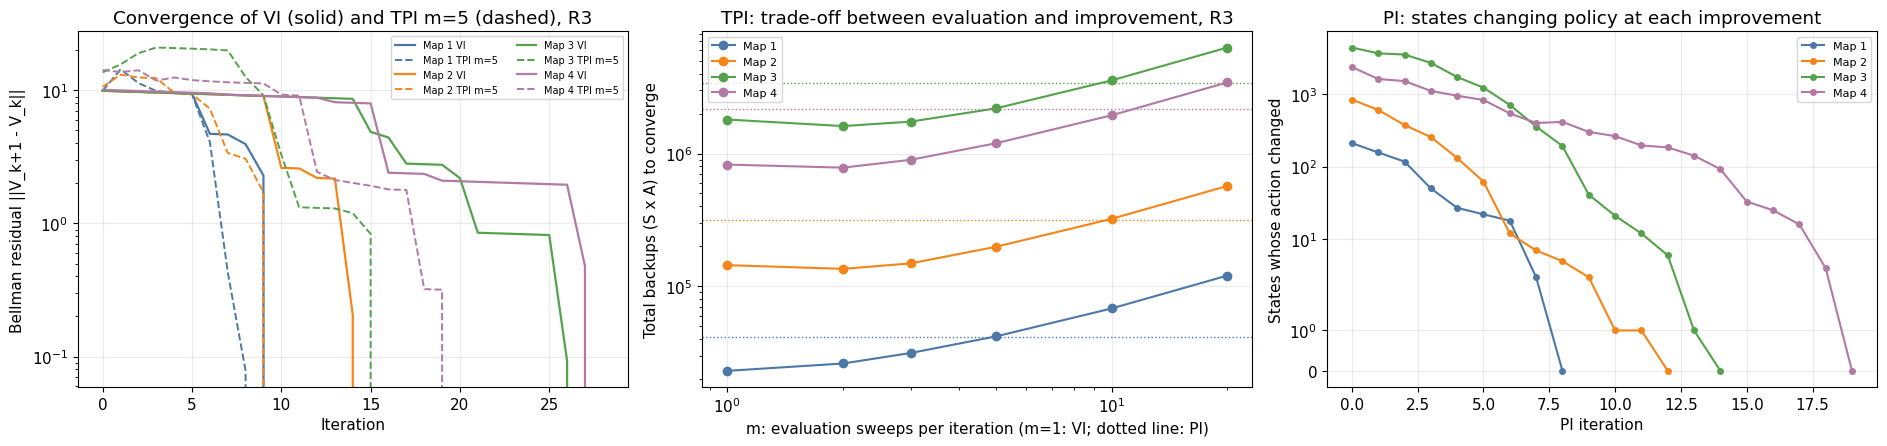

In [27]:
TPI_M = (1, 2, 3, 5, 10, 20)
rows, CONV = [], {}
for m in MAPS:
    for rt in REWARDS:
        M = get_model(m, rt)
        outs = {"VI": value_iteration(M), "PI": policy_iteration(M)}
        for mm in TPI_M:
            outs[f"TPI(m={mm})"] = truncated_policy_iteration(M, mm)
        for name, o in outs.items():
            f = eval_policy_q(m, q_dict(M, o["Q"]))
            rows.append({"map": m, "reward": f"R{rt}", "thuật toán": name, "vòng lặp": o["iters"], "backups (S x A)": o["backups"],
                         "thời gian (ms)": 1000 * o["time"], "điểm nhiệm vụ": f["score"], "DP": DP_SCORES[m],
                         "max|Q-Q*|": float(np.abs(o["Q"] - M["Qstar"]).max()), "|S|": M["S"]})
        CONV[(m, rt)] = outs
MB = pd.DataFrame(rows)
print("Các thuật toán dựa trên mô hình hội tụ về cùng Q* (max|Q-Q*| lớn nhất):", f"{MB['max|Q-Q*|'].max():.2e}")
sub = MB[(MB["reward"] == "R3")]
display(sub.pivot_table(index=["map", "|S|"], columns="thuật toán", values="backups (S x A)")[["VI", "PI"] + [f"TPI(m={mm})" for mm in TPI_M]].style.format("{:,.0f}"))

fig, axes = plt.subplots(1, 3, figsize=(19, 4.6))
for m, col in zip(MAPS, ["#4c78a8", "#f58518", "#54a24b", "#b279a2"]):
    o = CONV[(m, 3)]
    axes[0].semilogy(o["VI"]["hist"], color=col, label=f"{MAP_TITLES[m].split(' (')[0]} VI", lw=1.6)
    axes[0].semilogy(o["TPI(m=5)"]["hist"], color=col, ls="--", label=f"{MAP_TITLES[m].split(' (')[0]} TPI m=5", lw=1.4)
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("Bellman residual ||V_k+1 - V_k||")
axes[0].set_title("Convergence of VI (solid) and TPI m=5 (dashed), R3")
axes[0].legend(fontsize=7, ncol=2)
for m, col in zip(MAPS, ["#4c78a8", "#f58518", "#54a24b", "#b279a2"]):
    ys = [MB[(MB["map"] == m) & (MB["reward"] == "R3") & (MB["thuật toán"] == f"TPI(m={mm})")]["backups (S x A)"].iloc[0] for mm in TPI_M]
    axes[1].plot(TPI_M, ys, "o-", color=col, label=MAP_TITLES[m].split(" (")[0])
    pi_b = MB[(MB["map"] == m) & (MB["reward"] == "R3") & (MB["thuật toán"] == "PI")]["backups (S x A)"].iloc[0]
    axes[1].axhline(pi_b, color=col, ls=":", lw=1)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("m: evaluation sweeps per iteration (m=1: VI; dotted line: PI)")
axes[1].set_ylabel("Total backups (S x A) to converge")
axes[1].set_title("TPI: trade-off between evaluation and improvement, R3")
axes[1].legend(fontsize=8)
for m, col in zip(MAPS, ["#4c78a8", "#f58518", "#54a24b", "#b279a2"]):
    axes[2].plot(CONV[(m, 3)]["PI"]["hist"], "o-", color=col, label=MAP_TITLES[m].split(" (")[0], ms=4)
axes[2].set_xlabel("PI iteration")
axes[2].set_ylabel("States whose action changed")
axes[2].set_yscale("symlog")
axes[2].set_title("PI: states changing policy at each improvement")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()


## **9.3 So sánh thống nhất**

map,Map 1,Map 2,Map 3,Map 4
thuật toán,,,,
VI,1.000,1.000,1.000,1.000
PI,1.000,1.000,1.000,1.000
TPI(m=3),1.000,1.000,1.000,1.000
TPI(m=10),1.000,1.000,1.000,1.000
QL,0.847,0.823,0.706,0.833
SARSA,0.860,0.866,0.850,0.833
MC,0.833,0.885,0.811,0.940
QL-opt,1.000,1.000,1.000,1.000
SARSA-opt,1.000,1.000,0.919,1.000


map,Map 1,Map 2,Map 3,Map 4
thuật toán,,,,
VI,"23,012","144,128","1,804,208","825,572"
PI,"41,317","315,280","3,382,890","2,170,685"
TPI(m=3),"31,380","148,632","1,739,772","896,742"
TPI(m=10),"67,990","322,036","3,560,089","1,942,941"
QL-opt,"37,697","166,585","1,293,207","470,058"
SARSA-opt,"64,387","272,024",không đạt,"738,346"
QL,không đạt,"200,520",không đạt,không đạt
MC,không đạt,không đạt,không đạt,"529,568"
MC-opt,không đạt,không đạt,không đạt,"586,892"


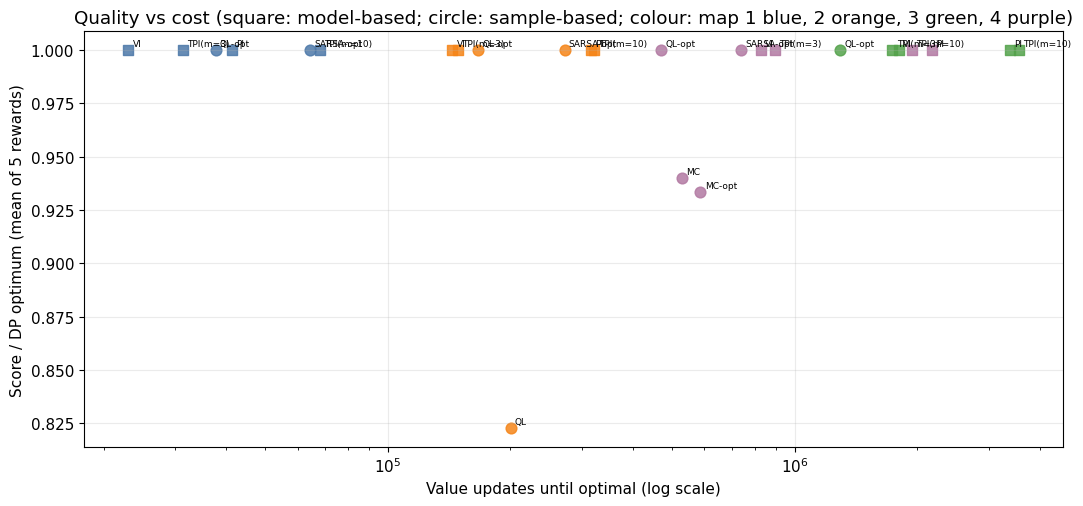

In [28]:
def updates_to_optimal(r):
    """Trung vị số cập nhật (tổng bước tương tác) tới khi greedy luôn tối ưu, trên các seed có đạt."""
    vals = []
    for run, e in zip(r["runs"], r["e2o"]):
        if not np.isnan(e):
            vals.append(float(run["st"]["lengths"][: int(e)].sum()))
    return (float(np.median(vals)) if vals else np.nan), len(vals)


rows = []
for m in MAPS:
    M3 = get_model(m, 3)
    for name in ("VI", "PI", "TPI(m=3)", "TPI(m=10)"):
        sel = MB[(MB["map"] == m) & (MB["thuật toán"] == name)]
        rows.append({"map": MAP_TITLES[m].split(" (")[0], "thuật toán": name, "loại": "dựa trên mô hình", "cần P, R": "có",
                     "tỷ lệ TB (5 reward)": float((sel["điểm nhiệm vụ"] / sel["DP"]).mean()),
                     "cập nhật tới tối ưu (R3)": float(sel[sel["reward"] == "R3"]["backups (S x A)"].iloc[0]), "seed đạt": "-"})
    for a in MF:
        up, k = updates_to_optimal(RES_ALL[(m, a, 3)])
        rows.append({"map": MAP_TITLES[m].split(" (")[0], "thuật toán": a, "loại": "học theo mẫu", "cần P, R": "không",
                     "tỷ lệ TB (5 reward)": float(np.mean([RES_ALL[(m, a, rt)]["ratio"] for rt in REWARDS])),
                     "cập nhật tới tối ưu (R3)": up, "seed đạt": f"{k}/{len(SEEDS)}"})
UNI = pd.DataFrame(rows)
display(UNI.pivot_table(index="thuật toán", columns="map", values="tỷ lệ TB (5 reward)", sort=False).style.format("{:.3f}").background_gradient(cmap="YlGn", vmin=0.6, vmax=1.0)
        .set_caption("Chất lượng (tỷ lệ so với DP, trung bình 5 reward)"))
display(UNI.pivot_table(index="thuật toán", columns="map", values="cập nhật tới tối ưu (R3)", sort=False).style.format("{:,.0f}", na_rep="không đạt")
        .set_caption("Chi phí: số lần cập nhật giá trị tới khi chính sách luôn tối ưu (R3, trung vị các seed đạt; 'không đạt' nếu không seed nào)"))

fig, ax = plt.subplots(figsize=(11, 5.2))
order = ["VI", "PI", "TPI(m=3)", "TPI(m=10)"] + MF
markers = {"dựa trên mô hình": "s", "học theo mẫu": "o"}
for m, col in zip(MAPS, ["#4c78a8", "#f58518", "#54a24b", "#b279a2"]):
    sub = UNI[UNI["map"] == MAP_TITLES[m].split(" (")[0]]
    for _, rr in sub.iterrows():
        if not np.isnan(rr["cập nhật tới tối ưu (R3)"]):
            ax.scatter(rr["cập nhật tới tối ưu (R3)"], rr["tỷ lệ TB (5 reward)"], color=col, marker=markers[rr["loại"]], s=60, alpha=.85)
            ax.annotate(rr["thuật toán"], (rr["cập nhật tới tối ưu (R3)"], rr["tỷ lệ TB (5 reward)"]), fontsize=6.5, xytext=(3, 3), textcoords="offset points")
ax.set_xscale("log")
ax.set_xlabel("Value updates until optimal (log scale)")
ax.set_ylabel("Score / DP optimum (mean of 5 rewards)")
ax.set_title("Quality vs cost (square: model-based; circle: sample-based; colour: map 1 blue, 2 orange, 3 green, 4 purple)")
plt.tight_layout()
plt.show()


# **Phần 10. Demo một episode bằng policy đã học**

Chạy một episode đầy đủ với chính sách của seed tốt nhất, hiển thị từng bước trên bàn cờ. Chọn Map 2 với R3 vì có coin biến mất cần cứu.

QL-opt, Map 2 (medium 6x6), R3 urgency (seed 456)
Trạng thái đầu:
Bước:   0 | Thời gian:  13 | Coin đã thu: 0/4
    0  1  2  3  4  5
0   A  .  .  2  .  .
1   .  #  .  .  .  .
2   .  .  4  .  .  .
3   .  .  .  .  3  .
4   .  .  T  .  .  .
5   .  .  .  6  .  E

Bước 1: Xuống -> (1, 0) | reward -0.050 
Bước:   1 | Thời gian:  12 | Coin đã thu: 0/4
    0  1  2  3  4  5
0   .  .  .  2  .  .
1   A  #  .  .  .  .
2   .  .  4  .  .  .
3   .  .  .  .  3  .
4   .  .  T  .  .  .
5   .  .  .  6  .  E

Bước 2: Xuống -> (2, 0) | reward +0.062 
Bước:   2 | Thời gian:  11 | Coin đã thu: 0/4
    0  1  2  3  4  5
0   .  .  .  2  .  .
1   .  #  .  .  .  .
2   A  .  4  .  .  .
3   .  .  .  .  3  .
4   .  .  T  .  .  .
5   .  .  .  6  .  E

Bước 3: Phải -> (2, 1) | reward +0.079 
Bước:   3 | Thời gian:  10 | Coin đã thu: 0/4
    0  1  2  3  4  5
0   .  .  .  2  .  .
1   .  #  .  .  .  .
2   .  A  4  .  .  .
3   .  .  .  .  3  .
4   .  .  T  .  .  .
5   .  .  .  6  .  E

Bước 4: Phải -> (2, 2) | reward +4.1

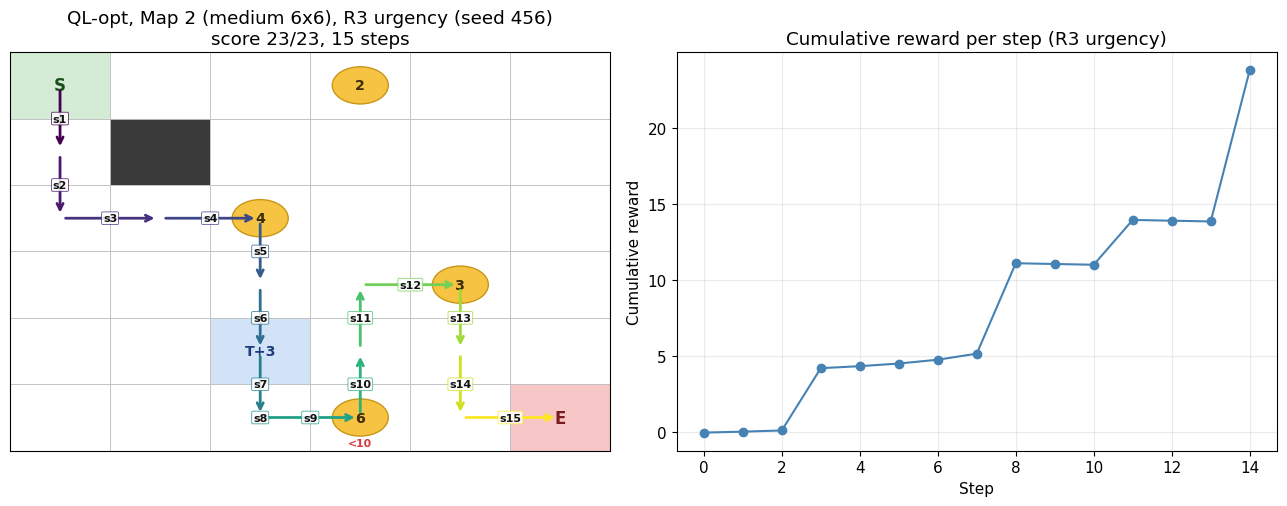

In [29]:
def demo_episode(Q, m, rt, title, show_boards=True):
    cfg = MAPS[m]
    env = CoinCollectorEnv(cfg, rt)
    env.reset(seed=0)
    path, rews, log = [tuple(env.pos)], [], []
    if show_boards:
        print(f"{title}\nTrạng thái đầu:")
        env.render()
    while True:
        s = env.state
        q = Q.get(s)
        a = int(np.argmax(q)) if q is not None else 0
        prev = tuple(env.pos)
        coins_before = env.coins_caught
        _, r, ter, trun, _ = env.step(a)
        rews.append(r)
        path.append(tuple(env.pos))
        note = ("thu coin " + str(cfg["coins"].get(tuple(env.pos)))) if env.coins_caught > coins_before else ""
        if cfg.get("time_bonus_pos") and tuple(env.pos) == tuple(cfg["time_bonus_pos"]) and env.bonus and s[4] == 0:
            note += " kích hoạt Time Bonus"
        if tuple(env.pos) == prev:
            note += " va tường/biên"
        log.append((len(rews), ACTION_NAMES[a], tuple(env.pos), round(r, 3), note.strip()))
        if show_boards:
            print(f"Bước {len(rews)}: {ACTION_NAMES[a]} -> {tuple(env.pos)} | reward {r:+.3f} {('| ' + note.strip()) if note.strip() else ''}")
            env.render()
        if ter or trun:
            break
    score = env.value_caught + (10 if env.reached_exit else 0)
    print(f"Kết thúc: {'tới Exit' if env.reached_exit else 'hết thời gian'} | {len(rews)} bước | coin {env.coins_caught}/{env.n_coins} | điểm nhiệm vụ {score} (tối ưu DP: {DP_SCORES[m]:.0f}) | tổng reward {sum(rews):.3f}")
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
    draw_board(axes[0], cfg, 1.2)
    draw_path(axes[0], path, lw=2, label_size=8)
    axes[0].set_title(f"{title}\nscore {score}/{DP_SCORES[m]:.0f}, {len(rews)} steps")
    axes[1].plot(np.cumsum(rews), "o-", color="steelblue")
    axes[1].set_xlabel("Step")
    axes[1].set_ylabel("Cumulative reward")
    axes[1].set_title(f"Cumulative reward per step ({REWARD_LABELS[rt]})")
    plt.tight_layout()
    plt.show()
    return log


demo_m, demo_rt = 2, 3
_ = demo_episode(RES_ALL[(demo_m, "QL-opt", demo_rt)]["best_Q"], demo_m, demo_rt,
                 f"QL-opt, {MAP_TITLES[demo_m]}, {REWARD_LABELS[demo_rt]} (seed {RES_ALL[(demo_m, 'QL-opt', demo_rt)]['best_seed']})")
